# F1 Forecasting — Baselines

This notebook establishes simple reference forecasts for fashion popularity
4 and 8 weeks ahead.

Predictions and score tables will be saved in `results/f1/` using the
team's agreed format.

## 1. Setup and File Paths

Import the required libraries, locate the two F1 dataset files, and
create the results folder.

- Data location: `Project/data/`
- Notebook location: `Project/Progress/`
- Results location: `Project/results/f1/`

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the Project folder.
CURRENT_DIR = Path.cwd()
PROJECT_DIR = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "Progress"
    else CURRENT_DIR
)

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results" / "f1"

POPULARITY_PATH = DATA_DIR / "f1_main.csv"
INFLUENCER_PATH = DATA_DIR / "f1_fashion_forward.csv"

# Check that both datasets exist.
for file_path in [POPULARITY_PATH, INFLUENCER_PATH]:
    if not file_path.is_file():
        raise FileNotFoundError(f"Dataset not found: {file_path}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Settings for reproducible analysis.
RANDOM_SEED = 42
HORIZONS = [4, 8]

pd.set_option("display.max_columns", 12)
plt.rcParams["figure.figsize"] = (12, 4)

print("Project folder:", PROJECT_DIR)
print("Data folder:", DATA_DIR)
print("Results folder:", RESULTS_DIR)
print("\nBoth F1 dataset files were found.")

Project folder: /Users/daki/Desktop/SEM 2/ML/Project
Data folder: /Users/daki/Desktop/SEM 2/ML/Project/data
Results folder: /Users/daki/Desktop/SEM 2/ML/Project/results/f1

Both F1 dataset files were found.


## 2. Load the F1 Datasets

Load weekly popularity and influencer measurements from the two CSV files.
The first column contains dates; the remaining columns contain fashion series.

The original files are read without being modified.

In [4]:
# Read the first CSV column as the date index.
popularity = pd.read_csv(POPULARITY_PATH, index_col=0)
influencer = pd.read_csv(INFLUENCER_PATH, index_col=0)

# Convert the index to dates and sort chronologically.
popularity.index = pd.to_datetime(popularity.index, errors="raise")
influencer.index = pd.to_datetime(influencer.index, errors="raise")

popularity = popularity.sort_index()
influencer = influencer.sort_index()

popularity.index.name = "date"
influencer.index.name = "date"

# Confirm that all measurement columns are numeric.
for name, data in [
    ("Popularity", popularity),
    ("Influencer", influencer),
]:
    non_numeric = data.select_dtypes(exclude="number").columns.tolist()

    if non_numeric:
        raise TypeError(
            f"{name} contains non-numeric columns: {non_numeric[:5]}"
        )

    print(f"{name}: {data.shape[0]:,} weeks × {data.shape[1]:,} series")
    print(
        f"Date range: {data.index.min().date()} "
        f"to {data.index.max().date()}\n"
    )

print("Popularity preview:")
display(popularity.iloc[:5, :5])

print("Influencer preview:")
display(influencer.iloc[:5, :5])

Popularity: 261 weeks × 10,000 series
Date range: 2015-01-05 to 2019-12-30

Influencer: 261 weeks × 10,000 series
Date range: 2015-01-05 to 2019-12-30

Popularity preview:


,br_female_outerwear_0,br_female_outerwear_1,br_female_outerwear_2,br_female_outerwear_3,br_female_outerwear_4
date,,,,,
2015-01-05,0.014472,0.000000,0.000000,0.014472,0.000000
2015-01-12,0.000000,0.000000,0.000000,0.000000,0.029515
2015-01-19,0.000000,0.029996,0.014998,0.014998,0.029996
2015-01-26,0.011684,0.000000,0.000000,0.000000,0.005842
2015-02-02,0.006146,0.006146,0.006146,0.007170,0.016390


Influencer preview:


,br_female_outerwear_0,br_female_outerwear_1,br_female_outerwear_2,br_female_outerwear_3,br_female_outerwear_4
date,,,,,
2015-01-05,0.022968,0.010440,0.010440,0.014616,0.018792
2015-01-12,0.025582,0.016279,0.013954,0.020930,0.027907
2015-01-19,0.024387,0.022170,0.017736,0.028821,0.026604
2015-01-26,0.031788,0.020435,0.015894,0.043141,0.029517
2015-02-02,0.022019,0.019267,0.019267,0.019267,0.030277


## 3. Verify Data Quality and Alignment

Check that both files contain the same dates and series identifiers,
with regular weekly observations and valid numeric values.

Identical influencer columns are retained: they may be paired with
different popularity series.

In [5]:
quality_rows = []

for name, data in [
    ("Popularity", popularity),
    ("Influencer", influencer),
]:
    values = data.to_numpy()
    weekly_gaps = data.index.to_series().diff().dropna()

    quality_rows.append({
        "dataset": name,
        "weeks": len(data),
        "series": data.shape[1],
        "duplicate_dates": int(data.index.duplicated().sum()),
        "duplicate_column_names": int(data.columns.duplicated().sum()),
        "missing_values": int(data.isna().sum().sum()),
        "infinite_values": int(np.isinf(values).sum()),
        "negative_values": int((values < 0).sum()),
        "regular_weekly_dates": bool(
            weekly_gaps.eq(pd.Timedelta(weeks=1)).all()
        ),
    })

quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

# Stop rather than silently drop or rearrange mismatched data.
if not popularity.index.equals(influencer.index):
    raise ValueError("The two files have different dates.")

if not popularity.columns.equals(influencer.columns):
    raise ValueError(
        "Series identifiers or their column order differ between files."
    )

problem_columns = [
    "duplicate_dates",
    "duplicate_column_names",
    "missing_values",
    "infinite_values",
    "negative_values",
]

if quality_summary[problem_columns].to_numpy().any():
    raise ValueError("Data-quality issues found. Review the table above.")

if not quality_summary["regular_weekly_dates"].all():
    raise ValueError("Dates are not consistently one week apart.")

# Save the checks alongside the experiment outputs.
quality_summary.to_csv(
    RESULTS_DIR / "data_quality_summary.csv",
    index=False,
)

print("All checks passed: dates and series align, with valid weekly data.")
print("Shared influencer curves are retained; no series were removed.")

,dataset,weeks,series,duplicate_dates,duplicate_column_names,missing_values,infinite_values,negative_values,regular_weekly_dates
0,Popularity,261,10000,0,0,0,0,0,True
1,Influencer,261,10000,0,0,0,0,0,True


All checks passed: dates and series align, with valid weekly data.
Shared influencer curves are retained; no series were removed.


## 4. Define Chronological Data Splits

Keep observations in time order:

- Training: first 182 weeks.
- Validation: next 39 weeks.
- Test: final 40 weeks.

We will develop and compare baselines using validation results.
The test period is reserved for the final comparison.

Evaluation periods are assigned by the target date—the week being
predicted. Forecasts use only information available on the forecast date.
For trained models, training examples must also have all their targets
inside the training period.

This cell defines the splits; it does not train models or evaluate the test set.

In [6]:
TRAIN_WEEKS = 182
VALIDATION_WEEKS = 39
TEST_WEEKS = 40

expected_weeks = TRAIN_WEEKS + VALIDATION_WEEKS + TEST_WEEKS

if len(popularity) != expected_weeks:
    raise ValueError(
        f"Expected {expected_weeks} weeks, found {len(popularity)}. "
        "Review the split before continuing."
    )

TRAIN_END_POS = TRAIN_WEEKS
VALIDATION_END_POS = TRAIN_WEEKS + VALIDATION_WEEKS

# Store split labels against target dates.
split_by_date = pd.Series(
    ["training"] * TRAIN_WEEKS
    + ["validation"] * VALIDATION_WEEKS
    + ["test"] * TEST_WEEKS,
    index=popularity.index,
    name="period",
)
split_by_date.index.name = "date"

split_rows = []

for period in ["training", "validation", "test"]:
    dates = split_by_date.index[split_by_date.eq(period)]

    split_rows.append({
        "period": period,
        "start_date": dates.min(),
        "end_date": dates.max(),
        "weeks": len(dates),
    })

split_summary = pd.DataFrame(split_rows)

display(split_summary)

# These training-only tables can be used for exploratory analysis
# and, later, fitting preprocessing parameters.
popularity_train = popularity.iloc[:TRAIN_END_POS].copy()
influencer_train = influencer.iloc[:TRAIN_END_POS].copy()

# Save split definitions for the team.
split_summary.to_csv(
    RESULTS_DIR / "split_summary.csv",
    index=False,
    date_format="%Y-%m-%d",
)

split_by_date.to_csv(
    RESULTS_DIR / "split_dates.csv",
    date_format="%Y-%m-%d",
)

print("Chronological splits defined and saved.")
print("Next: prepare validation forecast dates and targets for 4 and 8 weeks ahead.")

,period,start_date,end_date,weeks
0,training,2015-01-05,2018-06-25,182
1,validation,2018-07-02,2019-03-25,39
2,test,2019-04-01,2019-12-30,40


Chronological splits defined and saved.
Next: prepare validation forecast dates and targets for 4 and 8 weeks ahead.


## 5. Prepare Validation Forecast Dates and Targets

For each validation target week, identify the forecast date exactly
4 or 8 weeks earlier.

The target is popularity in that specific future week, not an average
over the intervening weeks.

All baselines will use the same target dates and series for a fair
comparison. Later validation forecasts may use earlier validation
observations because those values would already be known.

Only validation targets are prepared here. Test results remain reserved.

In [7]:
# Use 52 weeks for the annual seasonal baseline.
SEASONAL_PERIOD = 52

validation_dates = split_by_date.index[
    split_by_date.eq("validation")
]

validation_targets = {}
schedule_parts = []

for horizon in HORIZONS:
    target_positions = popularity.index.get_indexer(validation_dates)
    forecast_positions = target_positions - horizon

    # Check that all three baselines have sufficient past information.
    # Four-week average: forecast week and the preceding three weeks.
    # Seasonal baseline: target week minus 52 weeks.
    seasonal_positions = target_positions - SEASONAL_PERIOD

    if (forecast_positions < 3).any():
        raise ValueError("Insufficient history for the four-week average.")

    if (seasonal_positions < 0).any():
        raise ValueError("Insufficient history for the seasonal baseline.")

    if (seasonal_positions > forecast_positions).any():
        raise ValueError("Seasonal baseline would use future information.")

    forecast_dates = popularity.index[forecast_positions]
    target_dates = popularity.index[target_positions]

    if not (
        (target_dates - forecast_dates)
        == pd.Timedelta(weeks=horizon)
    ).all():
        raise ValueError("Forecast and target dates have an incorrect gap.")

    schedule = pd.DataFrame({
        "forecast_date": forecast_dates,
        "date": target_dates,
        "horizon": horizon,
        "period": "validation",
    })

    schedule_parts.append(schedule)

    # Store a wide target table for now:
    # rows = target weeks; columns = series.
    validation_targets[horizon] = popularity.iloc[
        target_positions
    ].copy()

validation_schedule = pd.concat(
    schedule_parts,
    ignore_index=True,
)

schedule_summary = (
    validation_schedule.groupby("horizon", as_index=False)
    .agg(
        target_weeks=("date", "size"),
        first_forecast_date=("forecast_date", "min"),
        last_forecast_date=("forecast_date", "max"),
        first_target_date=("date", "min"),
        last_target_date=("date", "max"),
    )
)

schedule_summary["series"] = popularity.shape[1]
schedule_summary["predictions_per_baseline"] = (
    schedule_summary["target_weeks"] * schedule_summary["series"]
)

display(schedule_summary)
display(validation_schedule.head())

validation_schedule.to_csv(
    RESULTS_DIR / "validation_forecast_schedule.csv",
    index=False,
    date_format="%Y-%m-%d",
)

print("Validation forecast dates and targets are ready.")
print("No baseline predictions have been made yet.")

,horizon,target_weeks,first_forecast_date,last_forecast_date,first_target_date,last_target_date,series,predictions_per_baseline
0,4,39,2018-06-04,2019-02-25,2018-07-02,2019-03-25,10000,390000
1,8,39,2018-05-07,2019-01-28,2018-07-02,2019-03-25,10000,390000


,forecast_date,date,horizon,period
0,2018-06-04,2018-07-02,4,validation
1,2018-06-11,2018-07-09,4,validation
2,2018-06-18,2018-07-16,4,validation
3,2018-06-25,2018-07-23,4,validation
4,2018-07-02,2018-07-30,4,validation


Validation forecast dates and targets are ready.
No baseline predictions have been made yet.


## 6. Generate Baseline Predictions

Generate three simple forecasts for each validation target:

1. Last value: repeat the popularity value known on the forecast date.
2. Four-week average: average the forecast week and its preceding three weeks.
3. Seasonal naive: use the popularity value 52 weeks before the target week.

Each forecast uses only information available on its forecast date.
Predictions are stored in memory here; scoring and CSV export follow.

In [8]:
# Rolling averages use the current week and the previous three weeks.
popularity_rolling4 = popularity.rolling(
    window=4,
    min_periods=4,
).mean()

# Keys: (model name, horizon).
# Values: prediction tables indexed by target date.
baseline_predictions = {}

for horizon in HORIZONS:
    schedule = (
        validation_schedule.loc[
            validation_schedule["horizon"].eq(horizon)
        ]
        .sort_values("date")
        .reset_index(drop=True)
    )

    target_dates = pd.DatetimeIndex(schedule["date"], name="date")
    forecast_dates = pd.DatetimeIndex(schedule["forecast_date"])

    seasonal_dates = target_dates - pd.Timedelta(
        weeks=SEASONAL_PERIOD
    )

    source_tables = {
        "last_value": popularity.loc[forecast_dates],
        "four_week_average": popularity_rolling4.loc[forecast_dates],
        "seasonal_naive": popularity.loc[seasonal_dates],
    }

    actual = validation_targets[horizon].loc[target_dates]

    for model_name, source in source_tables.items():
        # Source rows come from historical dates.
        # Relabel them with the future dates they predict.
        predicted = pd.DataFrame(
            source.to_numpy(copy=True),
            index=target_dates,
            columns=popularity.columns,
        )

        if not predicted.index.equals(actual.index):
            raise ValueError("Prediction dates do not match actual dates.")

        if not predicted.columns.equals(actual.columns):
            raise ValueError("Prediction series do not match actual series.")

        if not np.isfinite(predicted.to_numpy()).all():
            raise ValueError(
                f"Invalid predictions for {model_name}, horizon {horizon}."
            )

        baseline_predictions[(model_name, horizon)] = predicted

# Preview one series for the four-week horizon.
example_item = popularity.columns[0]
example_horizon = 4

example_schedule = (
    validation_schedule.loc[
        validation_schedule["horizon"].eq(example_horizon)
    ]
    .sort_values("date")
)

preview = example_schedule.set_index("date")[
    ["forecast_date"]
].copy()

preview["actual"] = validation_targets[
    example_horizon
][example_item]

for model_name in [
    "last_value",
    "four_week_average",
    "seasonal_naive",
]:
    preview[model_name] = baseline_predictions[
        (model_name, example_horizon)
    ][example_item]

print(f"Example series: {example_item}")
print(f"Forecast horizon: {example_horizon} weeks")
display(preview.head())

print(
    f"Created {len(baseline_predictions)} prediction tables: "
    "3 baselines × 2 horizons."
)
print("Validation predictions are ready for scoring.")

Example series: br_female_outerwear_0
Forecast horizon: 4 weeks


,forecast_date,actual,last_value,four_week_average,seasonal_naive
date,,,,,
2018-07-02,2018-06-04,0.012046,0.014812,0.014382,0.024154
2018-07-09,2018-06-11,0.017923,0.013548,0.014047,0.018244
2018-07-16,2018-06-18,0.017091,0.012875,0.013145,0.017190
2018-07-23,2018-06-25,0.009142,0.014790,0.014006,0.016119
2018-07-30,2018-07-02,0.013703,0.012046,0.013315,0.014328


Created 6 prediction tables: 3 baselines × 2 horizons.
Validation predictions are ready for scoring.


## 7. Evaluate Baselines on Validation Data

Calculate two error measures:

- MAE: the average absolute difference between predictions and actual values.
- MASE: each series' MAE divided by its average absolute weekly change
  in the training period (non-seasonal reference, m = 1).

Lower scores are better. Overall MASE is the mean of the per-series scores.
A MASE below 1 means the error is below the training-period reference;
it does not automatically mean the model beats a baseline on validation data.

Series with a zero MASE denominator are excluded from MASE only.
Their MAE is still reported.

Save both overall scores and per-series scores for the team's analysis."

In [9]:
# MASE definition: training-only, one-week naive reference.
# Share this definition with Person 5 so scores are interpreted consistently.
MASE_PERIOD = 1

mase_denominator = (
    popularity_train.diff(MASE_PERIOD)
    .abs()
    .iloc[MASE_PERIOD:]
    .mean(axis=0)
)

valid_mase = (
    np.isfinite(mase_denominator)
    & mase_denominator.gt(0)
)

overall_rows = []
per_series_parts = []

for (model_name, horizon), predicted in baseline_predictions.items():
    actual = validation_targets[horizon].loc[
        predicted.index, predicted.columns
    ]

    absolute_errors = (predicted - actual).abs()
    mae_by_series = absolute_errors.mean(axis=0)

    mase_by_series = (
        mae_by_series
        .div(mase_denominator)
        .where(valid_mase)
    )

    overall_rows.append({
        "dataset": "f1",
        "frequency": "weekly",
        "model": model_name,
        "horizon": horizon,
        "period": "validation",
        "with_influencer": "not_applicable",
        "mae": float(absolute_errors.to_numpy().mean()),
        "mase": float(mase_by_series.mean()),
        "mase_period": MASE_PERIOD,
        "n_series": predicted.shape[1],
        "n_target_weeks": predicted.shape[0],
        "n_predictions": predicted.size,
        "n_series_mase": int(valid_mase.sum()),
    })

    per_series_parts.append(pd.DataFrame({
        "dataset": "f1",
        "frequency": "weekly",
        "item": predicted.columns,
        "model": model_name,
        "horizon": horizon,
        "period": "validation",
        "with_influencer": "not_applicable",
        "mae": mae_by_series.to_numpy(),
        "mase": mase_by_series.to_numpy(),
        "mase_denominator": mase_denominator.to_numpy(),
        "mase_period": MASE_PERIOD,
        "n_predictions": predicted.shape[0],
    }))

baseline_scores = (
    pd.DataFrame(overall_rows)
    .sort_values(["horizon", "mae"])
    .reset_index(drop=True)
)

baseline_scores_by_series = pd.concat(
    per_series_parts,
    ignore_index=True,
)

display(baseline_scores[[
    "model",
    "horizon",
    "period",
    "mae",
    "mase",
    "n_predictions",
]])

baseline_scores.to_csv(
    RESULTS_DIR / "baseline_scores_validation.csv",
    index=False,
)

baseline_scores_by_series.to_csv(
    RESULTS_DIR / "baseline_scores_by_series_validation.csv",
    index=False,
)

print(f"Series excluded from MASE: {(~valid_mase).sum():,}")
print("Overall and per-series validation scores saved.")
print("The test period has not been evaluated.")

,model,horizon,period,mae,mase,n_predictions
0,seasonal_naive,4,validation,0.003518,0.944008,390000
1,last_value,4,validation,0.004459,1.055599,390000
2,four_week_average,4,validation,0.004677,1.062286,390000
3,seasonal_naive,8,validation,0.003518,0.944008,390000
4,last_value,8,validation,0.006217,1.398347,390000
5,four_week_average,8,validation,0.006458,1.413411,390000


Series excluded from MASE: 0
Overall and per-series validation scores saved.
The test period has not been evaluated.


### Comparison of Validation Baselines

Seasonal naive performed best among the three baselines at both horizons.
Its MAE was approximately 21% lower than the last-value baseline at
4 weeks and 43% lower at 8 weeks.

Last-value and four-week-average errors increased at the longer horizon.
Seasonal naive scores remained identical because both horizons evaluated
the same target weeks using their values 52 weeks earlier.

The results support including annual history in subsequent models.
Seasonal naive will remain an important reference: a trained model must
demonstrate additional value beyond this simple seasonal forecast.

These findings apply to validation data; final test performance and the
benefit of influencer inputs have not yet been evaluated.

## 8. Export Validation Predictions

Save one CSV per baseline using the team's required columns:

date, item, horizon, actual, predicted, model, period

Additional columns record the forecast date, dataset, frequency and
whether influencer inputs were used. For these baselines,
with_influencer is "not_applicable".

Each row represents one series, one target week and one forecast horizon.
Only validation predictions are exported here.

In [10]:
required_columns = [
    "date", "item", "horizon", "actual",
    "predicted", "model", "period",
]

extra_columns = [
    "forecast_date", "dataset", "frequency", "with_influencer",
]

export_summary_rows = []

for model_name in [
    "last_value",
    "four_week_average",
    "seasonal_naive",
]:
    output_path = (
        RESULTS_DIR / f"predictions_{model_name}_validation.csv"
    )

    rows_written = 0

    for horizon_number, horizon in enumerate(HORIZONS):
        predicted = baseline_predictions[(model_name, horizon)]
        actual = validation_targets[horizon].loc[
            predicted.index, predicted.columns
        ]

        # Match each target date to the date its forecast was made.
        forecast_dates = (
            validation_schedule.loc[
                validation_schedule["horizon"].eq(horizon)
            ]
            .set_index("date")
            .loc[predicted.index, "forecast_date"]
        )

        n_dates, n_items = predicted.shape

        # Flatten both tables in the same order:
        # all items for the first date, then all items for the next date.
        export_frame = pd.DataFrame({
            "date": np.repeat(predicted.index.to_numpy(), n_items),
            "item": np.tile(predicted.columns.to_numpy(), n_dates),
            "horizon": horizon,
            "actual": actual.to_numpy().ravel(),
            "predicted": predicted.to_numpy().ravel(),
            "model": model_name,
            "period": "validation",
            "forecast_date": np.repeat(
                forecast_dates.to_numpy(), n_items
            ),
            "dataset": "f1",
            "frequency": "weekly",
            "with_influencer": "not_applicable",
        })

        if export_frame[required_columns + extra_columns].isna().any().any():
            raise ValueError("Missing values found in the export.")

        if export_frame.duplicated(
            ["forecast_date", "date", "item", "horizon"]
        ).any():
            raise ValueError("Duplicate prediction rows found.")

        # Write the first horizon, then append the second.
        export_frame[required_columns + extra_columns].to_csv(
            output_path,
            index=False,
            mode="w" if horizon_number == 0 else "a",
            header=(horizon_number == 0),
            date_format="%Y-%m-%d",
        )

        rows_written += len(export_frame)

        if model_name == "last_value" and horizon_number == 0:
            print("Example of the team's prediction-file format:")
            display(export_frame.head())

        del export_frame

    export_summary_rows.append({
        "file": output_path.name,
        "model": model_name,
        "period": "validation",
        "rows": rows_written,
        "size_mb": round(output_path.stat().st_size / (1024 ** 2), 2),
    })

export_summary = pd.DataFrame(export_summary_rows)
display(export_summary)

print("Validation prediction files saved to:", RESULTS_DIR)
print("Each CSV contains both the 4-week and 8-week horizons.")

Example of the team's prediction-file format:


,date,item,horizon,actual,predicted,model,period,forecast_date,dataset,frequency,with_influencer
0,2018-07-02,br_female_outerwear_0,4,0.012046,0.014812,last_value,validation,2018-06-04,f1,weekly,not_applicable
1,2018-07-02,br_female_outerwear_1,4,0.022887,0.014812,last_value,validation,2018-06-04,f1,weekly,not_applicable
2,2018-07-02,br_female_outerwear_2,4,0.019876,0.011932,last_value,validation,2018-06-04,f1,weekly,not_applicable
3,2018-07-02,br_female_outerwear_3,4,0.012046,0.015635,last_value,validation,2018-06-04,f1,weekly,not_applicable
4,2018-07-02,br_female_outerwear_4,4,0.048786,0.035795,last_value,validation,2018-06-04,f1,weekly,not_applicable


,file,model,period,rows,size_mb
0,predictions_last_value_validation.csv,last_value,validation,780000,95.07
1,predictions_four_week_average_validation.csv,four_week_average,validation,780000,101.54
2,predictions_seasonal_naive_validation.csv,seasonal_naive,validation,780000,98.02


Validation prediction files saved to: /Users/daki/Desktop/SEM 2/ML/Project/results/f1
Each CSV contains both the 4-week and 8-week horizons.


## 9. Plot Actual and Predicted Popularity

Compare actual popularity with the three baseline forecasts at
4-week and 8-week horizons.

Select three series randomly using a fixed seed, rather than choosing
only examples where a baseline performs well. Use the same examples
for both horizons.

These plots illustrate individual forecasts; the score tables summarise
performance across all 10,000 series.

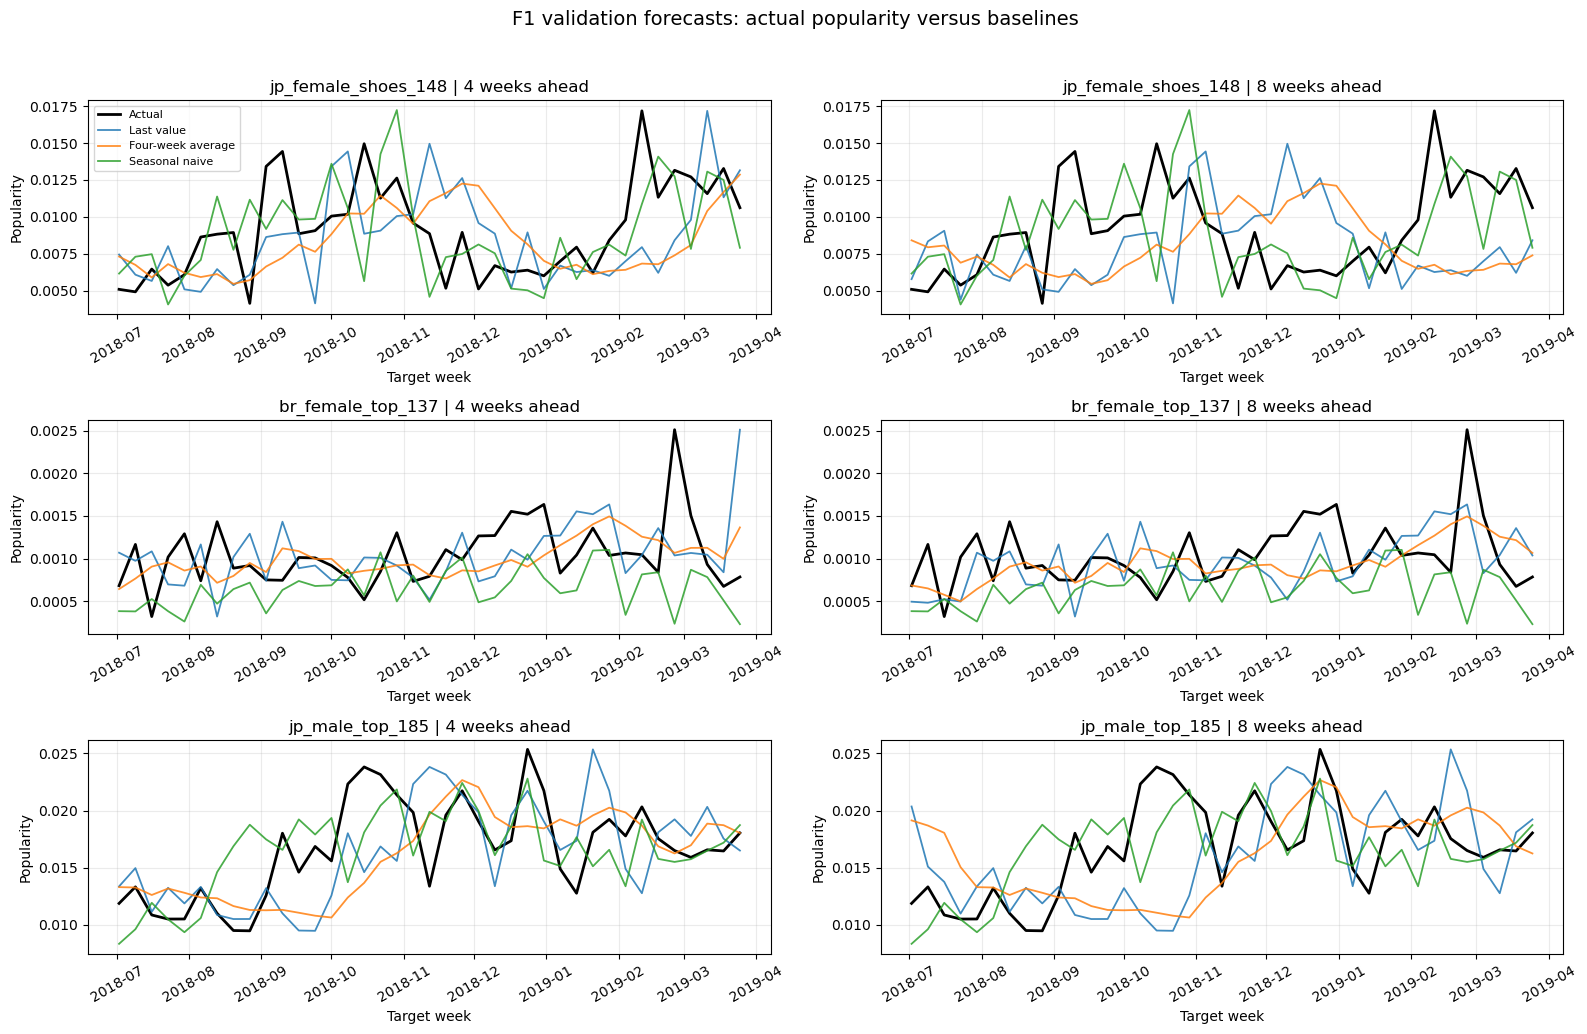

Forecast plot saved to: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/baseline_forecast_examples_validation.png


In [11]:
# Reproducible selection, independent of forecast performance.
rng = np.random.default_rng(RANDOM_SEED)

example_items = rng.choice(
    popularity.columns.to_numpy(),
    size=min(3, popularity.shape[1]),
    replace=False,
).tolist()

model_styles = {
    "last_value": ("Last value", "tab:blue"),
    "four_week_average": ("Four-week average", "tab:orange"),
    "seasonal_naive": ("Seasonal naive", "tab:green"),
}

fig, axes = plt.subplots(
    nrows=len(example_items),
    ncols=len(HORIZONS),
    figsize=(16, 3.5 * len(example_items)),
    squeeze=False,
)

for row, item in enumerate(example_items):
    for col, horizon in enumerate(HORIZONS):
        ax = axes[row, col]
        actual = validation_targets[horizon][item]

        ax.plot(
            actual.index,
            actual,
            label="Actual",
            color="black",
            linewidth=2,
        )

        for model_name, (label, color) in model_styles.items():
            predicted = baseline_predictions[(model_name, horizon)][item]

            ax.plot(
                predicted.index,
                predicted,
                label=label,
                color=color,
                linewidth=1.3,
                alpha=0.85,
            )

        ax.set_title(f"{item} | {horizon} weeks ahead")
        ax.set_xlabel("Target week")
        ax.set_ylabel("Popularity")
        ax.grid(alpha=0.25)
        ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)

fig.suptitle(
    "F1 validation forecasts: actual popularity versus baselines",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

plot_path = RESULTS_DIR / "baseline_forecast_examples_validation.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")

plt.show()

# Record the example selection for reproducibility.
pd.DataFrame({"item": example_items}).to_csv(
    RESULTS_DIR / "baseline_example_items.csv",
    index=False,
)

print("Forecast plot saved to:", plot_path)

## 10. Summarise Baseline Results

Identify the lowest-error baseline at each forecast horizon.

Compare MAE and MASE separately because they summarise errors differently.
These are validation findings, not final test results.

In [12]:
summary_rows = []

for horizon in HORIZONS:
    scores = baseline_scores.loc[
        baseline_scores["horizon"].eq(horizon)
    ]

    for metric in ["mae", "mase"]:
        valid_scores = scores.dropna(subset=[metric])

        if valid_scores.empty:
            continue

        best = valid_scores.loc[valid_scores[metric].idxmin()]

        summary_rows.append({
            "horizon": horizon,
            "metric": metric,
            "best_baseline": best["model"],
            "score": best[metric],
            "period": "validation",
        })

baseline_summary = pd.DataFrame(summary_rows)
display(baseline_summary)

baseline_summary.to_csv(
    RESULTS_DIR / "baseline_summary_validation.csv",
    index=False,
)

print("Validation findings:")
for row in baseline_summary.itertuples(index=False):
    print(
        f"- At {row.horizon} weeks ahead, {row.best_baseline} "
        f"has the lowest {row.metric.upper()}: {row.score:.6f}."
    )

print(
    "\nThese establish reference scores for the later model comparisons. "
    "They do not yet show whether influencer information helps."
)

print("\nPrediction CSV sizes:")
display(export_summary[["file", "rows", "size_mb"]])

,horizon,metric,best_baseline,score,period
0,4,mae,seasonal_naive,0.003518,validation
1,4,mase,seasonal_naive,0.944008,validation
2,8,mae,seasonal_naive,0.003518,validation
3,8,mase,seasonal_naive,0.944008,validation


Validation findings:
- At 4 weeks ahead, seasonal_naive has the lowest MAE: 0.003518.
- At 4 weeks ahead, seasonal_naive has the lowest MASE: 0.944008.
- At 8 weeks ahead, seasonal_naive has the lowest MAE: 0.003518.
- At 8 weeks ahead, seasonal_naive has the lowest MASE: 0.944008.

These establish reference scores for the later model comparisons. They do not yet show whether influencer information helps.

Prediction CSV sizes:


,file,rows,size_mb
0,predictions_last_value_validation.csv,780000,95.07
1,predictions_four_week_average_validation.csv,780000,101.54
2,predictions_seasonal_naive_validation.csv,780000,98.02


In [13]:
import gzip
import shutil

for csv_path in RESULTS_DIR.glob("predictions_*_validation.csv"):
    compressed_path = csv_path.with_suffix(".csv.gz")

    with csv_path.open("rb") as source:
        with gzip.open(compressed_path, "wb") as destination:
            shutil.copyfileobj(source, destination)

    print(
        f"{compressed_path.name}: "
        f"{compressed_path.stat().st_size / (1024 ** 2):.2f} MB"
    )

predictions_last_value_validation.csv.gz: 11.58 MB
predictions_seasonal_naive_validation.csv.gz: 11.35 MB
predictions_four_week_average_validation.csv.gz: 14.43 MB


### Baseline Findings

Seasonal naive achieved the lowest validation MAE and MASE among the
three baselines at both horizons: MAE = 0.003518 and MASE = 0.944.

Its scores are identical across horizons because the evaluation uses
the same target weeks, and seasonal naive predicts each target using
its value 52 weeks earlier.

These results establish seasonal naive as the strongest baseline to
compare against in later model experiments. They do not yet establish
whether influencer inputs improve forecasts.

## 11. Compare Timing in Both Directions

Use 100 reproducibly sampled series from the training period.

Compare weekly changes at gaps of 0–8 weeks:

- Influencers lead: compare influencer changes with later popularity changes.
- Popularity leads: compare popularity changes with later influencer changes.

Positive correlation means changes tend to move in the same direction.
Correlation near zero means no clear linear relationship.

Report the median across sampled series. Individual series may behave
differently. This analysis describes timing, not causation.

direction,influencers_lead,popularity_leads
lag_weeks,,
0,0.0536,0.0536
1,-0.0002,-0.0096
2,0.0212,0.0270
3,-0.0138,-0.0095
4,0.0118,0.0117
5,0.0183,-0.0185
6,0.0113,0.0065
7,-0.0061,0.0121
8,0.0020,-0.0010


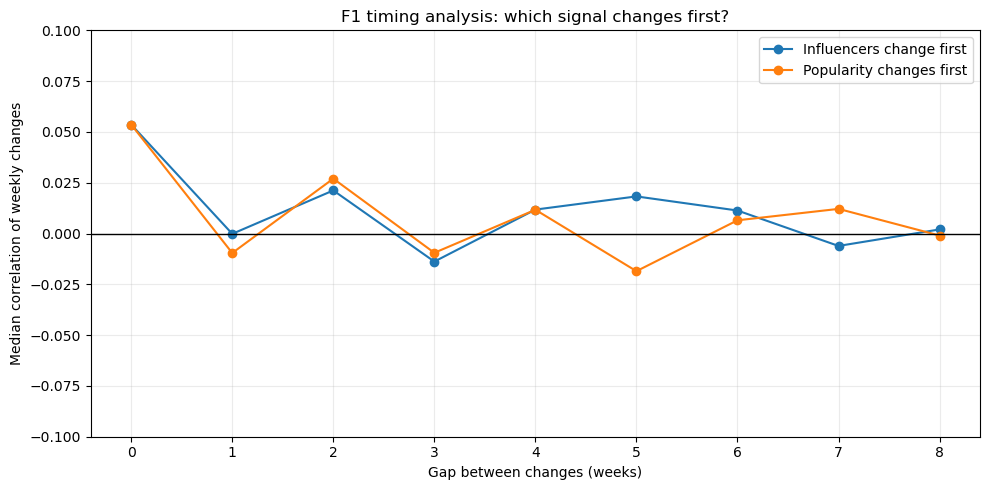

Timing results and chart saved to: /Users/daki/Desktop/SEM 2/ML/Project/results/f1
Only training data was used.
At lag 0, both directions should give the same correlation.


In [14]:
# Sample using training data only.
timing_rng = np.random.default_rng(RANDOM_SEED)

timing_items = timing_rng.choice(
    popularity_train.columns.to_numpy(),
    size=min(100, popularity_train.shape[1]),
    replace=False,
).tolist()

# Calculate changes from one week to the next.
pop_changes = popularity_train[timing_items].diff()
inf_changes = influencer_train[timing_items].diff()

timing_parts = []

for lag in range(9):
    # At date t, shift(lag) gives the measurement from t - lag.
    comparisons = {
        "influencers_lead": (
            inf_changes.shift(lag),
            pop_changes,
        ),
        "popularity_leads": (
            pop_changes.shift(lag),
            inf_changes,
        ),
    }

    for direction, (earlier, later) in comparisons.items():
        correlations = earlier.corrwith(later)

        # Number of valid paired observations for each series.
        pair_counts = (
            earlier.notna() & later.notna()
        ).sum(axis=0)

        timing_parts.append(pd.DataFrame({
            "item": timing_items,
            "direction": direction,
            "lag_weeks": lag,
            "correlation": correlations.reindex(
                timing_items
            ).to_numpy(),
            "n_pairs": pair_counts.reindex(
                timing_items
            ).to_numpy(),
            "period": "training",
        }))

timing_by_series = pd.concat(timing_parts, ignore_index=True)

timing_summary = (
    timing_by_series
    .groupby(["direction", "lag_weeks"], as_index=False)
    .agg(
        median_correlation=("correlation", "median"),
        mean_correlation=("correlation", "mean"),
        n_valid_series=("correlation", "count"),
    )
)

display(
    timing_summary.pivot(
        index="lag_weeks",
        columns="direction",
        values="median_correlation",
    ).round(4)
)

# Plot both directions.
fig, ax = plt.subplots(figsize=(10, 5))

labels = {
    "influencers_lead": "Influencers change first",
    "popularity_leads": "Popularity changes first",
}

for direction, label in labels.items():
    subset = timing_summary.loc[
        timing_summary["direction"].eq(direction)
    ].sort_values("lag_weeks")

    ax.plot(
        subset["lag_weeks"],
        subset["median_correlation"],
        marker="o",
        label=label,
    )

ax.axhline(0, color="black", linewidth=1)
ax.set(
    xlabel="Gap between changes (weeks)",
    ylabel="Median correlation of weekly changes",
    title="F1 timing analysis: which signal changes first?",
)
ax.set_xticks(range(9))
ax.grid(alpha=0.25)
ax.legend()

# Include a reasonable scale so small correlations are not exaggerated.
largest = timing_summary["median_correlation"].abs().max()
limit = max(0.1, float(largest) * 1.2) if pd.notna(largest) else 0.1
ax.set_ylim(-limit, limit)

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "timing_comparison_training.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Save detailed results for Person 5.
timing_by_series.to_csv(
    RESULTS_DIR / "timing_correlations_by_series_training.csv",
    index=False,
)

timing_summary.to_csv(
    RESULTS_DIR / "timing_summary_training.csv",
    index=False,
)

pd.DataFrame({"item": timing_items}).to_csv(
    RESULTS_DIR / "timing_sample_items.csv",
    index=False,
)

print("Timing results and chart saved to:", RESULTS_DIR)
print("Only training data was used.")
print("At lag 0, both directions should give the same correlation.")

### Timing Analysis Findings

Across the 100 sampled training series, median correlations were close
to zero in both directions at gaps of 1–8 weeks. This analysis therefore
found no consistent linear pattern of influencers leading popularity
or popularity leading influencers.

The same-week median correlation was approximately 0.054, which is
also weak. Individual series may have stronger relationships that the
median does not capture.

Next, we will compare forecasts with and without historical influencer
inputs to test whether they improve prediction accuracy.

## 12. Identify Fashion Categories

Inspect the series identifiers to determine which fashion categories
are available.

Identifiers such as `eu_female_pants_76` contain a region code,
a gender label, a category and a series number. These labels describe
broad groups, not exact named styles.

We will use these groups to investigate whether relationships differ
by category. No category will be removed based on its correlation.

In [15]:
# Inspect the naming structure before analysing category differences.
print("Example series identifiers:")
display(
    pd.DataFrame({
        "item": popularity.columns[:20]
    })
)

# Read identifiers from both ends so categories can contain underscores.
# Expected structure: region_gender_category_number
series_metadata = pd.DataFrame({
    "item": popularity.columns.astype(str)
})

parsed = series_metadata["item"].str.extract(
    r"^(?P<region>[^_]+)_"
    r"(?P<gender>[^_]+)_"
    r"(?P<category>.+)_"
    r"(?P<series_number>\d+)$"
)

series_metadata = pd.concat(
    [series_metadata, parsed],
    axis=1,
)

unparsed = series_metadata["category"].isna()

if unparsed.any():
    print("Identifiers that need manual review:")
    display(series_metadata.loc[unparsed, ["item"]].head(20))
    raise ValueError(
        "Some identifiers do not match the expected structure. "
        "Review them before category analysis."
    )

series_metadata["series_number"] = (
    series_metadata["series_number"].astype(int)
)

category_summary = (
    series_metadata
    .groupby("category", as_index=False)
    .agg(
        n_series=("item", "size"),
        n_region_codes=("region", "nunique"),
        n_gender_labels=("gender", "nunique"),
    )
    .sort_values("n_series", ascending=False)
    .reset_index(drop=True)
)

category_summary["share_percent"] = (
    100 * category_summary["n_series"] / len(series_metadata)
).round(2)

print("\nCategories available in F1:")
display(category_summary)

print("\nRegion codes:", sorted(series_metadata["region"].unique()))
print("Gender labels:", sorted(series_metadata["gender"].unique()))

# Save metadata for category-level analysis and Person 5.
series_metadata.to_csv(
    RESULTS_DIR / "series_metadata.csv",
    index=False,
)

category_summary.to_csv(
    RESULTS_DIR / "category_summary.csv",
    index=False,
)

print(f"\nParsed {len(series_metadata):,} series identifiers.")
print("No series were removed.")

Example series identifiers:


,item
0,br_female_outerwear_0
1,br_female_outerwear_1
2,br_female_outerwear_2
3,br_female_outerwear_3
4,br_female_outerwear_4
5,br_female_outerwear_5
6,br_female_outerwear_6
7,br_female_outerwear_7
8,br_female_outerwear_8
9,br_female_outerwear_9



Categories available in F1:


,category,n_series,n_region_codes,n_gender_labels,share_percent
0,top,3156,5,2,31.56
1,shoes,1924,5,2,19.24
2,outerwear,1757,5,2,17.57
3,pants,1264,5,2,12.64
4,texture,840,5,2,8.40
5,colortrend,430,5,2,4.30
6,shorts,369,5,2,3.69
7,skirt,142,5,1,1.42
8,dress,118,5,1,1.18



Region codes: ['br', 'cn', 'eu', 'jp', 'us']
Gender labels: ['female', 'male']

Parsed 10,000 series identifiers.
No series were removed.


## 13. Compare Timing Relationships by Category

Calculate correlations of weekly changes separately for each category,
using all series in the training period.

Check both directions at gaps of 1–8 weeks:
- Influencer activity changes before popularity.
- Popularity changes before influencer activity.

Report the median and the middle 50% of correlations in each group.
This helps identify differences that the overall median may hide.

These are exploratory findings. Any promising relationship must later
be checked on validation data. Categories contain different numbers
of series, and some series share influencer signals.


Influencers change first: median correlations


lag_weeks,1,2,3,4,5,6,7,8
category,,,,,,,,
top,0.006,0.008,0.006,0.011,0.004,0.005,0.008,-0.004
shoes,0.011,-0.001,0.010,0.005,0.003,0.008,-0.003,0.003
outerwear,0.004,-0.001,0.018,0.021,0.024,0.003,0.008,0.001
pants,0.007,0.002,-0.007,0.018,0.013,-0.002,0.001,-0.003
texture,-0.004,0.005,0.001,0.010,0.005,-0.005,0.007,-0.003
colortrend,0.006,-0.001,-0.011,0.013,-0.005,0.007,-0.003,-0.008
shorts,0.009,0.002,0.015,0.009,0.004,0.017,0.031,0.003
skirt,0.002,-0.000,0.028,-0.028,0.020,0.019,-0.009,-0.014
dress,-0.016,0.001,0.015,-0.006,-0.006,-0.002,0.005,0.000



Popularity changes first: median correlations


lag_weeks,1,2,3,4,5,6,7,8
category,,,,,,,,
top,0.008,-0.001,0.008,0.008,0.005,0.005,0.008,0.000
shoes,-0.004,0.005,0.002,-0.002,-0.008,-0.002,0.002,-0.003
outerwear,0.002,-0.006,0.012,-0.005,-0.006,0.003,0.011,-0.016
pants,-0.018,0.005,0.002,-0.012,-0.005,0.006,0.010,-0.020
texture,-0.002,-0.004,0.005,0.011,-0.002,0.003,0.001,-0.003
colortrend,-0.003,-0.001,0.007,-0.002,-0.014,0.001,-0.001,-0.011
shorts,-0.010,0.034,0.000,0.009,0.009,0.003,-0.010,0.020
skirt,0.012,0.012,-0.038,0.026,0.002,-0.003,0.005,0.001
dress,-0.028,0.009,0.002,-0.021,-0.006,0.010,-0.005,-0.009


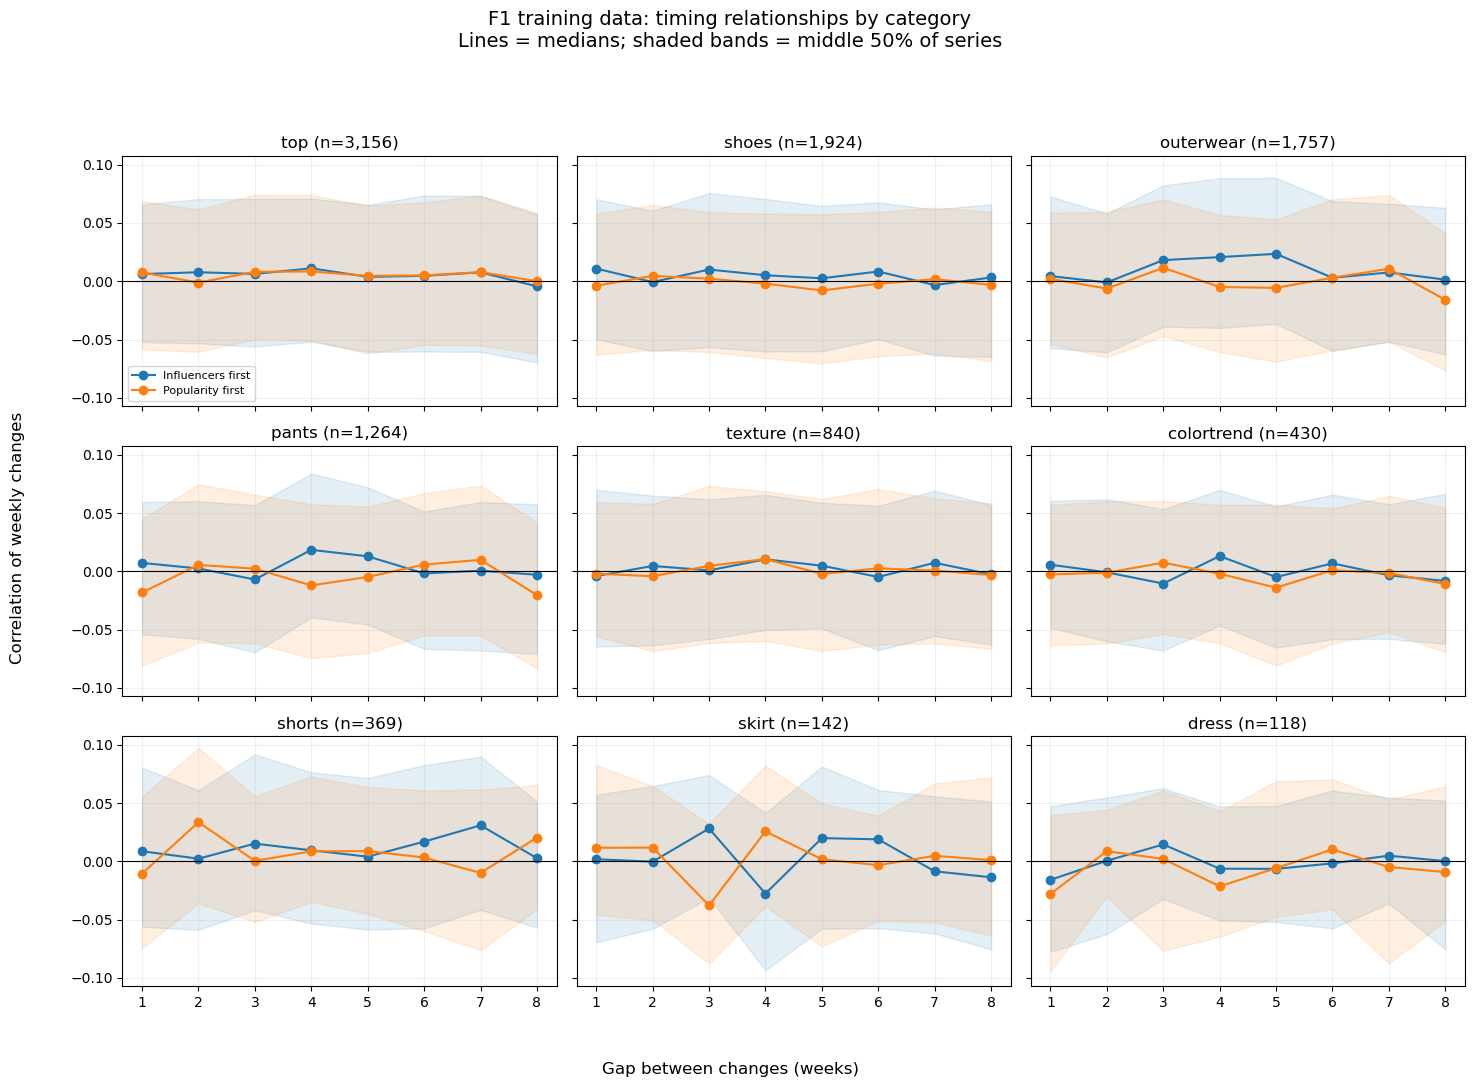

Category timing results saved.
Validation and test data were not used.


In [16]:
# All calculations use training observations only.
all_pop_changes = popularity_train.diff()
all_inf_changes = influencer_train.diff()

metadata_indexed = series_metadata.set_index("item")
category_timing_parts = []

for lag in range(1, 9):
    comparisons = {
        "influencers_lead": (
            all_inf_changes.shift(lag),
            all_pop_changes,
        ),
        "popularity_leads": (
            all_pop_changes.shift(lag),
            all_inf_changes,
        ),
    }

    for direction, (earlier, later) in comparisons.items():
        correlations = earlier.corrwith(later)

        result = pd.DataFrame({
            "item": correlations.index,
            "correlation": correlations.to_numpy(),
        })

        result["category"] = result["item"].map(
            metadata_indexed["category"]
        )
        result["lag_weeks"] = lag
        result["direction"] = direction
        result["period"] = "training"

        category_timing_parts.append(result)

category_timing_by_series = pd.concat(
    category_timing_parts,
    ignore_index=True,
)

category_timing_summary = (
    category_timing_by_series
    .groupby(
        ["category", "direction", "lag_weeks"],
        as_index=False,
    )
    .agg(
        n_valid_series=("correlation", "count"),
        median_correlation=("correlation", "median"),
        q25=("correlation", lambda x: x.quantile(0.25)),
        q75=("correlation", lambda x: x.quantile(0.75)),
    )
)

# Display category medians at each lag for both directions.
for direction, heading in [
    ("influencers_lead", "Influencers change first"),
    ("popularity_leads", "Popularity changes first"),
]:
    print(f"\n{heading}: median correlations")

    table = (
        category_timing_summary.loc[
            category_timing_summary["direction"].eq(direction)
        ]
        .pivot(
            index="category",
            columns="lag_weeks",
            values="median_correlation",
        )
        .reindex(category_summary["category"])
    )

    display(table.round(3))

# One panel per category.
categories = category_summary["category"].tolist()

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 11),
    sharex=True,
    sharey=True,
)

direction_styles = {
    "influencers_lead": ("Influencers first", "tab:blue"),
    "popularity_leads": ("Popularity first", "tab:orange"),
}

# Shared vertical scale across all panels.
bounds = category_timing_summary[["q25", "q75"]].to_numpy()
finite_bounds = bounds[np.isfinite(bounds)]
limit = (
    max(0.1, float(np.abs(finite_bounds).max()) * 1.1)
    if finite_bounds.size else 0.1
)

counts = category_summary.set_index("category")["n_series"]

for ax, category in zip(axes.flat, categories):
    for direction, (label, color) in direction_styles.items():
        subset = category_timing_summary.loc[
            category_timing_summary["category"].eq(category)
            & category_timing_summary["direction"].eq(direction)
        ].sort_values("lag_weeks")

        x = subset["lag_weeks"].to_numpy()
        median = subset["median_correlation"].to_numpy()

        ax.plot(x, median, marker="o", color=color, label=label)

        # Shading shows variation between series—not a confidence interval.
        ax.fill_between(
            x,
            subset["q25"].to_numpy(),
            subset["q75"].to_numpy(),
            color=color,
            alpha=0.12,
        )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{category} (n={counts[category]:,})")
    ax.set_xticks(range(1, 9))
    ax.set_ylim(-limit, limit)
    ax.grid(alpha=0.2)

axes[0, 0].legend(fontsize=8)
fig.supxlabel("Gap between changes (weeks)")
fig.supylabel("Correlation of weekly changes")
fig.suptitle(
    "F1 training data: timing relationships by category\n"
    "Lines = medians; shaded bands = middle 50% of series",
    fontsize=14,
)

fig.tight_layout(rect=[0.03, 0.03, 1, 0.93])

fig.savefig(
    RESULTS_DIR / "timing_by_category_training.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

category_timing_summary.to_csv(
    RESULTS_DIR / "timing_by_category_summary_training.csv",
    index=False,
)

category_timing_by_series.to_csv(
    RESULTS_DIR / "timing_by_category_series_training.csv",
    index=False,
)

print("Category timing results saved.")
print("Validation and test data were not used.")

## 14. Heatmap of Timing Relationships by Category

Each cell shows the median correlation for one category and time gap.

- Blue: positive correlation.
- Red: negative correlation.
- White: correlation near zero.

Both heatmaps use the same colour scale. Colours show the direction
and size of correlations, not statistical significance.

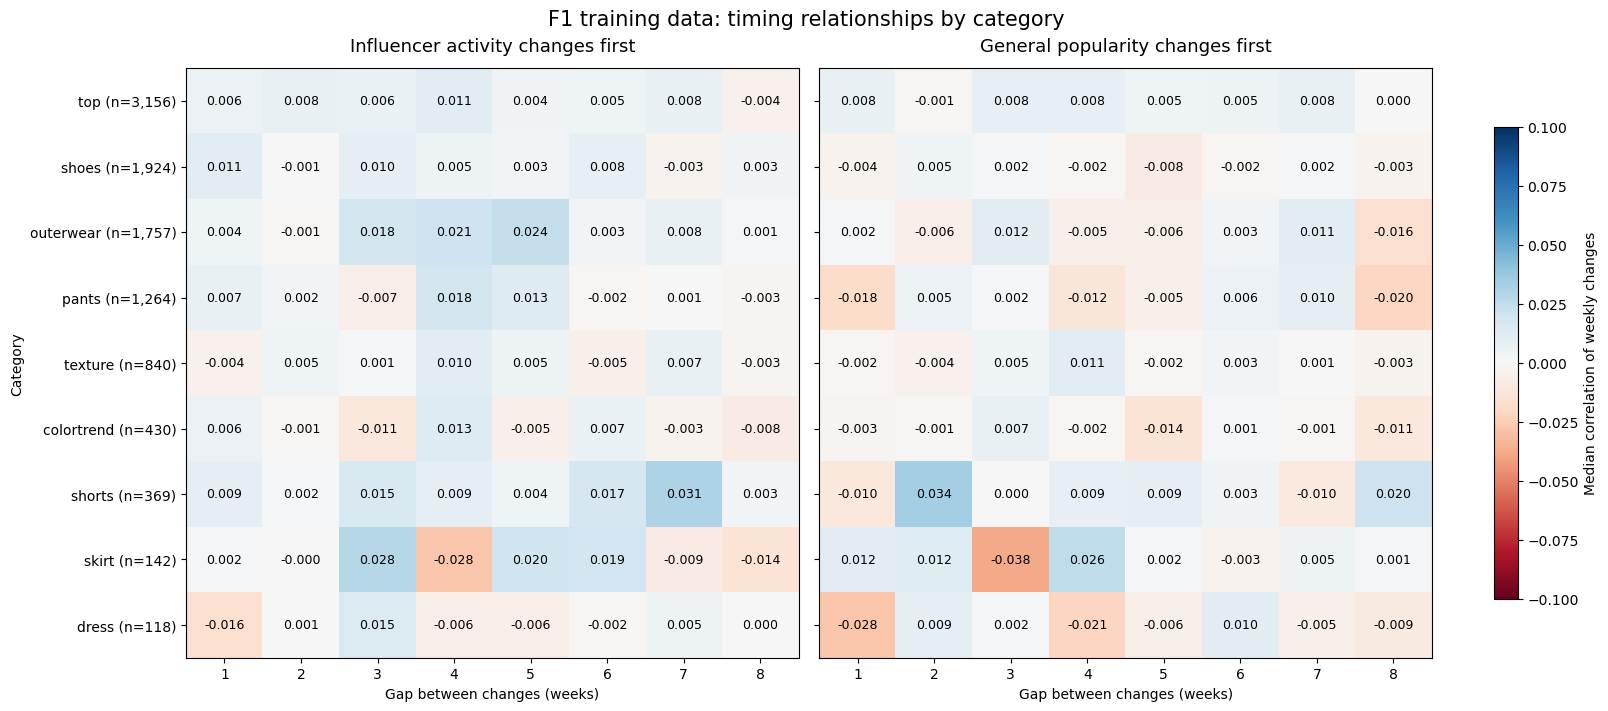

Heatmap saved to: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/timing_heatmap_by_category_training.png


In [17]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    sharey=True,
    constrained_layout=True,
)

categories = category_summary["category"].tolist()

# Use the same scale for both panels.
# A minimum range of ±0.10 avoids exaggerating tiny correlations.
max_correlation = (
    category_timing_summary["median_correlation"].abs().max()
)
colour_limit = max(0.10, float(max_correlation))

for ax, (direction, title) in zip(
    axes,
    [
        ("influencers_lead", "Influencer activity changes first"),
        ("popularity_leads", "General popularity changes first"),
    ],
):
    heatmap_table = (
        category_timing_summary.loc[
            category_timing_summary["direction"].eq(direction)
        ]
        .pivot(
            index="category",
            columns="lag_weeks",
            values="median_correlation",
        )
        .reindex(index=categories, columns=range(1, 9))
    )

    values = heatmap_table.to_numpy()

    image = ax.imshow(
        np.ma.masked_invalid(values),
        cmap="RdBu",
        vmin=-colour_limit,
        vmax=colour_limit,
        aspect="auto",
    )

    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel("Gap between changes (weeks)")
    ax.set_xticks(range(8))
    ax.set_xticklabels(range(1, 9))
    ax.set_yticks(range(len(categories)))
    ax.set_yticklabels([
        f"{category} (n={counts[category]:,})"
        for category in categories
    ])

    # Show exact values so weak correlations remain clear.
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values[row, col]

            label = f"{value:.3f}" if np.isfinite(value) else "N/A"
            text_colour = (
                "white"
                if np.isfinite(value)
                and abs(value) > colour_limit * 0.65
                else "black"
            )

            ax.text(
                col, row, label,
                ha="center",
                va="center",
                fontsize=9,
                color=text_colour,
            )

axes[0].set_ylabel("Category")

fig.colorbar(
    image,
    ax=axes,
    label="Median correlation of weekly changes",
    shrink=0.8,
)

fig.suptitle(
    "F1 training data: timing relationships by category",
    fontsize=15,
)

heatmap_path = RESULTS_DIR / "timing_heatmap_by_category_training.png"

fig.savefig(
    heatmap_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
print("Heatmap saved to:", heatmap_path)

### Category-Level Findings

Across all nine categories, median correlations of weekly changes
remained close to zero in both directions. Separating the data by
category therefore did not reveal a strong, consistent leading
relationship.

Outerwear showed small positive correlations when influencer activity
led by 3–5 weeks. Other categories showed isolated positive or negative
values rather than a stable pattern.

These exploratory results do not establish predictive usefulness.
We will retain the categories and assess influencer information through
forecasts with and without influencer inputs.

## 15. Check Whether Individual Relationships Continue in Validation

For each series and direction, select the time gap with the strongest
absolute training correlation. Then select the five strongest series
per direction.

Check those same series and gaps in validation without selecting again.

Strong training correlations may occur by chance when many combinations
are examined. Validation results are exploratory checks, not proof of
causation or statistical significance. The test period remains unused.

,item,category,direction,lag_weeks,training_correlation,validation_correlation,same_sign,validation_pairs
0,eu_female_shoes_54,shoes,influencers_lead,1,0.453,0.366,True,39
1,eu_female_shoes_72,shoes,influencers_lead,1,0.439,0.390,True,39
2,eu_female_shoes_62,shoes,influencers_lead,1,0.417,0.366,True,39
3,jp_female_pants_17,pants,influencers_lead,1,-0.414,0.110,False,39
4,eu_female_shoes_32,shoes,influencers_lead,1,0.411,0.265,True,39
5,jp_male_shoes_65,shoes,popularity_leads,6,0.441,0.069,True,39
6,jp_male_outerwear_140,outerwear,popularity_leads,2,0.394,0.180,True,39
7,eu_male_outerwear_91,outerwear,popularity_leads,3,0.390,-0.253,False,39
8,jp_female_top_138,top,popularity_leads,3,0.377,-0.144,False,39
9,jp_male_outerwear_126,outerwear,popularity_leads,2,0.375,-0.231,False,39


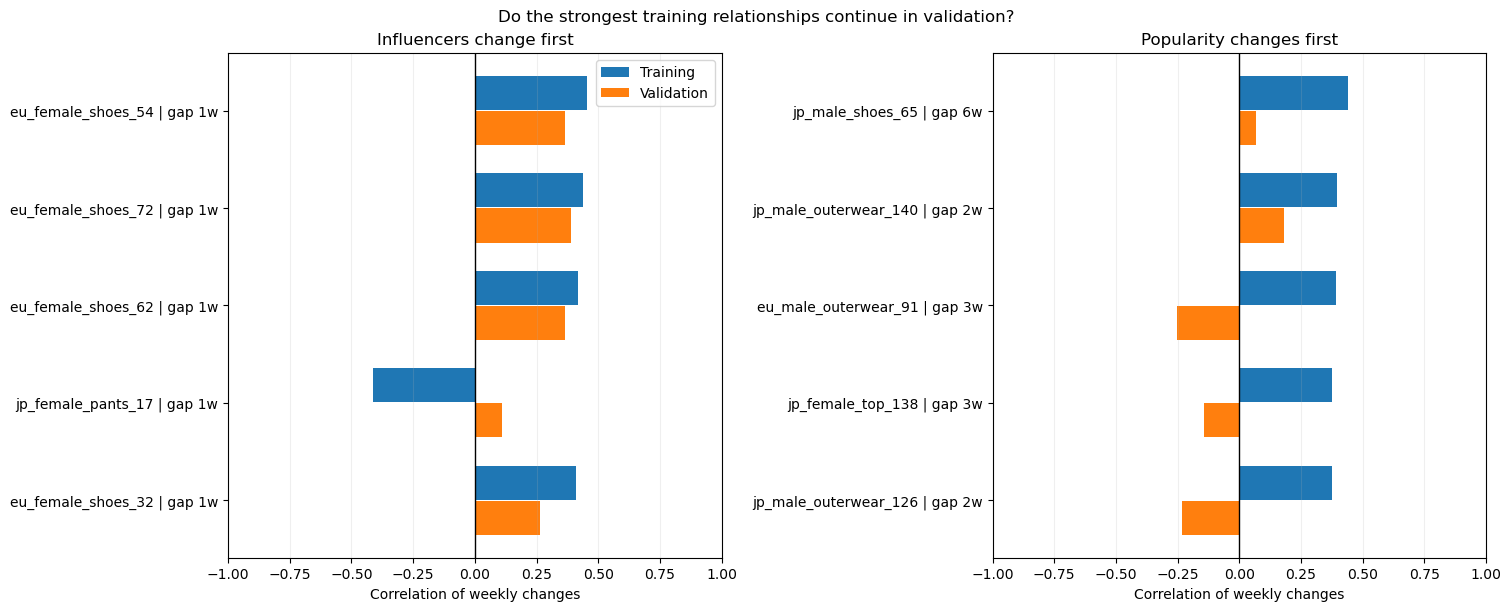

Candidates were selected using training data only.
Matching signs alone do not establish a reliable relationship.
Validation covers only 39 weeks, so correlations can be noisy.
No test data was used.


In [18]:
# Select candidates using TRAINING correlations only.
candidates = category_timing_by_series.dropna(
    subset=["correlation"]
).copy()

candidates["abs_training_correlation"] = (
    candidates["correlation"].abs()
)

# Choose one lag per item and direction.
best_lag_indices = (
    candidates.groupby(["item", "direction"])[
        "abs_training_correlation"
    ].idxmax()
)

best_lag_per_series = candidates.loc[best_lag_indices].copy()

# Predefined selection: five strongest series per direction.
selected_relationships = (
    best_lag_per_series
    .sort_values(
        ["direction", "abs_training_correlation", "item"],
        ascending=[True, False, True],
    )
    .groupby("direction", group_keys=False)
    .head(5)
    .copy()
)

# Calculate changes through the end of validation.
# Training history is available for lagged values at its beginning.
pop_changes_available = popularity.iloc[
    :VALIDATION_END_POS
].diff()

inf_changes_available = influencer.iloc[
    :VALIDATION_END_POS
].diff()

validation_dates = split_by_date.index[
    split_by_date.eq("validation")
]

validation_checks = []

for row in selected_relationships.itertuples(index=False):
    item = row.item
    lag = int(row.lag_weeks)

    if row.direction == "influencers_lead":
        earlier = inf_changes_available[item].shift(lag)
        later = pop_changes_available[item]
    else:
        earlier = pop_changes_available[item].shift(lag)
        later = inf_changes_available[item]

    # Only pairs whose later observation falls in validation.
    pairs = pd.DataFrame({
        "earlier_change": earlier.loc[validation_dates],
        "later_change": later.loc[validation_dates],
    }).dropna()

    validation_correlation = pairs["earlier_change"].corr(
        pairs["later_change"]
    )

    same_sign = (
        bool(
            row.correlation * validation_correlation > 0
        )
        if np.isfinite(validation_correlation)
        else pd.NA
    )

    validation_checks.append({
        "item": item,
        "category": row.category,
        "direction": row.direction,
        "lag_weeks": lag,
        "training_correlation": row.correlation,
        "validation_correlation": validation_correlation,
        "same_sign": same_sign,
        "validation_pairs": len(pairs),
    })

individual_validation_results = pd.DataFrame(validation_checks)

display(individual_validation_results.round(3))

individual_validation_results.to_csv(
    RESULTS_DIR / "selected_timing_relationships_validation.csv",
    index=False,
)

# Compare correlations visually.
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharex=True,
    constrained_layout=True,
)

for ax, (direction, title) in zip(
    axes,
    [
        ("influencers_lead", "Influencers change first"),
        ("popularity_leads", "Popularity changes first"),
    ],
):
    subset = individual_validation_results.loc[
        individual_validation_results["direction"].eq(direction)
    ].reset_index(drop=True)

    positions = np.arange(len(subset))

    ax.barh(
        positions - 0.18,
        subset["training_correlation"],
        height=0.35,
        label="Training",
        color="tab:blue",
    )
    ax.barh(
        positions + 0.18,
        subset["validation_correlation"],
        height=0.35,
        label="Validation",
        color="tab:orange",
    )

    ax.set_yticks(positions)
    ax.set_yticklabels([
        f"{row.item} | gap {row.lag_weeks}w"
        for row in subset.itertuples(index=False)
    ])
    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Correlation of weekly changes")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.2)

axes[0].legend()

fig.suptitle(
    "Do the strongest training relationships continue in validation?"
)

fig.savefig(
    RESULTS_DIR / "selected_timing_relationships_validation.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Candidates were selected using training data only.")
print("Matching signs alone do not establish a reliable relationship.")
print("Validation covers only 39 weeks, so correlations can be noisy.")
print("No test data was used.")

### Individual-Series Validation Findings

Four selected shoe series retained positive correlations in validation
when influencer activity led popularity by one week. Their correlations
were weaker than in training but remained positive. The selected pants
series changed sign.

In the reverse direction, the selected relationships generally weakened,
and three changed sign in validation.

These findings suggest that relationships may differ between individual
series, despite weak category-level medians. They do not establish that
influencers generally lead fashion popularity.

The examples were selected for strong training correlations, validation
covers only 39 weeks, and some series share influencer signals. Forecast
comparisons with and without influencer inputs are therefore needed to
assess practical predictive value.

## 16. Define Model Inputs

Prepare two versions of the same forecasting task:

- Popularity only: historical popularity and calendar information.
- Popularity plus influencers: the same inputs, plus historical
  influencer measurements.

Popularity inputs include annual history because seasonal naive was
the strongest validation baseline.

Both versions will use identical examples and targets. All inputs must
be available on the forecast date. No model is trained in this section.

In [19]:
# Lag 0 means the latest completed week, available when forecasting.
POPULARITY_LAGS = [0, 1, 2, 4, 8, 12, 26, 52]
INFLUENCER_LAGS = [0, 1, 2, 4, 8]
ROLLING_WINDOWS = [4, 8]

popularity_features = (
    [f"pop_lag_{lag}" for lag in POPULARITY_LAGS]
    + [f"pop_mean_{window}" for window in ROLLING_WINDOWS]
    + [
        "pop_change_1",       # Latest value minus previous week
        "pop_change_4",       # Latest value minus four weeks earlier
        "pop_std_8",          # Recent fluctuations
        "target_week_sin",    # Calendar position of the target week
        "target_week_cos",
    ]
)

influencer_features = (
    [f"inf_lag_{lag}" for lag in INFLUENCER_LAGS]
    + [f"inf_mean_{window}" for window in ROLLING_WINDOWS]
    + [
        "inf_change_1",
        "inf_change_4",
        "inf_std_8",
    ]
)

FEATURE_SETS = {
    "popularity_only": popularity_features,
    "with_influencer": popularity_features + influencer_features,
}

feature_schema = pd.DataFrame(
    [
        {
            "feature": feature,
            "source": "popularity_or_calendar",
            "used_without_influencer": "yes",
            "used_with_influencer": "yes",
        }
        for feature in popularity_features
    ]
    + [
        {
            "feature": feature,
            "source": "influencer",
            "used_without_influencer": "no",
            "used_with_influencer": "yes",
        }
        for feature in influencer_features
    ]
)

display(feature_schema)

feature_schema.to_csv(
    RESULTS_DIR / "feature_schema.csv",
    index=False,
)

print("Popularity-only inputs:", len(FEATURE_SETS["popularity_only"]))
print("Inputs including influencers:", len(FEATURE_SETS["with_influencer"]))
print("\nFeature definitions saved. Training tables are not yet built.")

,feature,source,used_without_influencer,used_with_influencer
0,pop_lag_0,popularity_or_calendar,yes,yes
1,pop_lag_1,popularity_or_calendar,yes,yes
2,pop_lag_2,popularity_or_calendar,yes,yes
3,pop_lag_4,popularity_or_calendar,yes,yes
4,pop_lag_8,popularity_or_calendar,yes,yes
5,pop_lag_12,popularity_or_calendar,yes,yes
6,pop_lag_26,popularity_or_calendar,yes,yes
7,pop_lag_52,popularity_or_calendar,yes,yes
8,pop_mean_4,popularity_or_calendar,yes,yes
9,pop_mean_8,popularity_or_calendar,yes,yes


Popularity-only inputs: 15
Inputs including influencers: 25

Feature definitions saved. Training tables are not yet built.


## 17. Build Forecast Examples Without Future Information

For each forecast date, build one row per fashion series.

Each row contains:
- Past popularity and influencer measurements.
- Calendar information for the target week.
- Actual popularity 4 or 8 weeks later, stored separately as the target.

The target date determines whether an example belongs to training or
validation. Training examples cannot have targets outside training.

Rows need at least 52 weeks of history. Test examples are not prepared yet.

In [20]:
def build_forecast_examples(forecast_pos, horizon):
    """Build one forecast date's examples for all series."""
    target_pos = forecast_pos + horizon

    if horizon not in HORIZONS:
        raise ValueError("Horizon must be 4 or 8 weeks.")

    if forecast_pos < max(POPULARITY_LAGS):
        raise ValueError("At least 52 weeks of history are required.")

    if target_pos >= VALIDATION_END_POS:
        raise ValueError("This function currently excludes test targets.")

    forecast_date = popularity.index[forecast_pos]
    target_date = popularity.index[target_pos]
    period = split_by_date.loc[target_date]

    # Historical measurements only, including the latest completed week.
    features = {}

    for lag in POPULARITY_LAGS:
        features[f"pop_lag_{lag}"] = (
            popularity.iloc[forecast_pos - lag].to_numpy()
        )

    for lag in INFLUENCER_LAGS:
        features[f"inf_lag_{lag}"] = (
            influencer.iloc[forecast_pos - lag].to_numpy()
        )

    for window in ROLLING_WINDOWS:
        start = forecast_pos - window + 1

        features[f"pop_mean_{window}"] = (
            popularity.iloc[start:forecast_pos + 1]
            .mean(axis=0).to_numpy()
        )
        features[f"inf_mean_{window}"] = (
            influencer.iloc[start:forecast_pos + 1]
            .mean(axis=0).to_numpy()
        )

    for gap in [1, 4]:
        features[f"pop_change_{gap}"] = (
            features["pop_lag_0"] - features[f"pop_lag_{gap}"]
        )
        features[f"inf_change_{gap}"] = (
            features["inf_lag_0"] - features[f"inf_lag_{gap}"]
        )

    features["pop_std_8"] = (
        popularity.iloc[forecast_pos - 7:forecast_pos + 1]
        .std(axis=0, ddof=0).to_numpy()
    )
    features["inf_std_8"] = (
        influencer.iloc[forecast_pos - 7:forecast_pos + 1]
        .std(axis=0, ddof=0).to_numpy()
    )

    # Future calendar dates are known at forecast time.
    angle = 2 * np.pi * (target_date.dayofyear - 1) / 365.25
    features["target_week_sin"] = np.sin(angle)
    features["target_week_cos"] = np.cos(angle)

    feature_table = pd.DataFrame(
        features,
        index=pd.Index(popularity.columns, name="item"),
    )[FEATURE_SETS["with_influencer"]].astype("float32")

    if not np.isfinite(feature_table.to_numpy()).all():
        raise ValueError("Invalid feature values found.")

    # Keep targets and identifiers separate from model inputs.
    metadata = pd.DataFrame({
        "item": popularity.columns,
        "forecast_date": forecast_date,
        "date": target_date,
        "horizon": horizon,
        "period": period,
        "actual": popularity.iloc[target_pos].to_numpy(),
    })

    return feature_table, metadata


# Identify eligible forecast dates without building huge tables yet.
eligible_forecasts = {}

for horizon in HORIZONS:
    for period in ["training", "validation"]:
        target_positions = np.flatnonzero(
            split_by_date.eq(period).to_numpy()
        )
        forecast_positions = target_positions - horizon

        eligible_forecasts[(period, horizon)] = forecast_positions[
            forecast_positions >= max(POPULARITY_LAGS)
        ]

example_counts = pd.DataFrame([
    {
        "period": period,
        "horizon": horizon,
        "forecast_dates": len(positions),
        "series_per_date": popularity.shape[1],
        "total_examples": len(positions) * popularity.shape[1],
    }
    for (period, horizon), positions in eligible_forecasts.items()
])

display(example_counts)

# Preview the first eligible four-week validation forecast.
preview_pos = int(eligible_forecasts[("validation", 4)][0])

X_preview, metadata_preview = build_forecast_examples(
    preview_pos, horizon=4
)

print("Identifiers and targets:")
display(metadata_preview.head())

print("Popularity-only inputs:")
display(X_preview[FEATURE_SETS["popularity_only"]].head())

print("Additional influencer inputs:")
display(X_preview[influencer_features].head())

example_counts.to_csv(
    RESULTS_DIR / "model_example_counts.csv",
    index=False,
)

print("Feature-building function is ready.")
print("No model has been trained and no test examples were prepared.")

,period,horizon,forecast_dates,series_per_date,total_examples
0,training,4,126,10000,1260000
1,validation,4,39,10000,390000
2,training,8,122,10000,1220000
3,validation,8,39,10000,390000


Identifiers and targets:


,item,forecast_date,date,horizon,period,actual
0,br_female_outerwear_0,2018-06-04,2018-07-02,4,validation,0.012046
1,br_female_outerwear_1,2018-06-04,2018-07-02,4,validation,0.022887
2,br_female_outerwear_2,2018-06-04,2018-07-02,4,validation,0.019876
3,br_female_outerwear_3,2018-06-04,2018-07-02,4,validation,0.012046
4,br_female_outerwear_4,2018-06-04,2018-07-02,4,validation,0.048786


Popularity-only inputs:


,pop_lag_0,pop_lag_1,pop_lag_2,pop_lag_4,pop_lag_8,pop_lag_12,...,pop_mean_8,pop_change_1,pop_change_4,pop_std_8,target_week_sin,target_week_cos
item,,,,,,,,,,,,,
br_female_outerwear_0,0.014812,0.011345,0.016482,0.011251,0.005171,0.006533,...,0.012254,0.003467,0.003561,0.003237,0.010751,-0.999942
br_female_outerwear_1,0.014812,0.012253,0.019621,0.023480,0.012222,0.013067,...,0.015479,0.002559,-0.008668,0.004661,0.010751,-0.999942
br_female_outerwear_2,0.011932,0.008622,0.019229,0.019077,0.009871,0.011056,...,0.013015,0.003310,-0.007145,0.004314,0.010751,-0.999942
br_female_outerwear_3,0.015635,0.008622,0.015697,0.006848,0.003761,0.005026,...,0.010486,0.007012,0.008786,0.003953,0.010751,-0.999942
br_female_outerwear_4,0.035795,0.036758,0.037673,0.047938,0.027264,0.026133,...,0.035347,-0.000963,-0.012142,0.007406,0.010751,-0.999942


Additional influencer inputs:


,inf_lag_0,inf_lag_1,inf_lag_2,inf_lag_4,inf_lag_8,inf_mean_4,inf_mean_8,inf_change_1,inf_change_4,inf_std_8
item,,,,,,,,,,
br_female_outerwear_0,0.006340,0.005489,0.007219,0.007775,0.004323,0.006818,0.005618,0.000851,-0.001435,0.002232
br_female_outerwear_1,0.014265,0.012350,0.011550,0.009330,0.005764,0.011186,0.009602,0.001915,0.004935,0.002771
br_female_outerwear_2,0.014265,0.012350,0.011550,0.009330,0.004323,0.010775,0.009027,0.001915,0.004935,0.003407
br_female_outerwear_3,0.012680,0.002744,0.008662,0.010885,0.004323,0.008078,0.007160,0.009936,0.001795,0.003718
br_female_outerwear_4,0.036456,0.023328,0.021656,0.023324,0.018733,0.023649,0.020934,0.013128,0.013131,0.007009


Feature-building function is ready.
No model has been trained and no test examples were prepared.


## 18. Set Up the LightGBM Comparison

We compare two versions of the same forecasting model:

- **Without influencers:** past popularity and calendar information.
- **With influencers:** the same inputs plus past influencer information.

Both versions use identical series, forecast dates and targets.
Models predict popularity 4 and 8 weeks ahead.

Training uses only answers already available on each refit date.
Validation results guide development; the test period remains reserved.
Models will be retrained every four forecast weeks.

In [21]:
%pip install lightgbm -q

Note: you may need to restart the kernel to use updated packages.


In [22]:
import lightgbm as lgb

MODEL_DIR = RESULTS_DIR / "lightgbm"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

REFIT_EVERY = 4
MODEL_SEED = 42

# Initial settings—not yet selected as the final settings.
LGBM_PARAMS = {
    "objective": "regression_l1",
    "n_estimators": 500,
    "learning_rate": 0.03,
    "num_leaves": 15,
    "max_depth": 5,
    "min_child_samples": 200,
    "reg_lambda": 10.0,
    "random_state": MODEL_SEED,
    "n_jobs": 4,
    "verbosity": -1,
}

# Use all series for the main experiment.
model_items = popularity.columns.copy()

comparison_inputs = {
    "no": FEATURE_SETS["popularity_only"].copy(),
    "yes": FEATURE_SETS["with_influencer"].copy(),
}

print("LightGBM version:", lgb.__version__)
print(f"Series: {len(model_items):,}")
print("Forecast horizons:", HORIZONS)
print("Retraining interval:", REFIT_EVERY, "weeks")
print("Inputs without influencers:", len(comparison_inputs["no"]))
print("Inputs with influencers:", len(comparison_inputs["yes"]))
print("Results folder:", MODEL_DIR)
print("\nSetup complete. No models trained or test results evaluated.")

LightGBM version: 4.7.0
Series: 10,000
Forecast horizons: [4, 8]
Retraining interval: 4 weeks
Inputs without influencers: 15
Inputs with influencers: 25
Results folder: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/lightgbm

Setup complete. No models trained or test results evaluated.


## 19. Prepare the Seasonal Reference and Model Tables

The seasonal reference uses popularity 52 weeks before the target week.
This value is already known when making a 4- or 8-week-ahead forecast.

LightGBM will predict an adjustment to this reference:

Final forecast = seasonal reference + predicted adjustment.

Both model versions receive the same seasonal reference.
Only the version with influencers receives influencer features.

We prepare training and validation examples here.
During training, examples will also be filtered so their answers were
already known on the model's refit date. Test examples remain excluded.

In [25]:
SEASONAL_FEATURE = "seasonal_target_reference"

# Add the same seasonal feature to both versions.
# This also avoids duplicate feature names if the cell is rerun.
comparison_inputs = {
    "no": list(dict.fromkeys(
        FEATURE_SETS["popularity_only"] + [SEASONAL_FEATURE]
    )),
    "yes": list(dict.fromkeys(
        FEATURE_SETS["with_influencer"] + [SEASONAL_FEATURE]
    )),
}


def build_seasonal_examples(forecast_pos, horizon):
    """Build one forecast week's features and metadata."""
    X, metadata = build_forecast_examples(forecast_pos, horizon)

    target_pos = forecast_pos + horizon
    seasonal_pos = target_pos - SEASONAL_PERIOD

    # The reference must be available on the forecast date.
    if not 0 <= seasonal_pos <= forecast_pos:
        raise ValueError("Seasonal reference is not available.")

    reference = popularity.iloc[seasonal_pos].to_numpy(
        dtype=np.float32
    )

    X = X.copy()
    X[SEASONAL_FEATURE] = reference

    metadata = metadata.copy()
    metadata["seasonal_reference"] = reference
    metadata["residual_target"] = (
        metadata["actual"] - metadata["seasonal_reference"]
    )

    return X, metadata


def build_model_table(horizon):
    """Build training and validation examples for one horizon."""
    positions = np.sort(np.concatenate([
        eligible_forecasts[("training", horizon)],
        eligible_forecasts[("validation", horizon)],
    ]))

    feature_parts = []
    metadata_parts = []

    for number, position in enumerate(positions, start=1):
        X, metadata = build_seasonal_examples(
            int(position), horizon
        )

        # Keep identical items and ordering in both tables.
        X = X.loc[model_items]
        metadata = (
            metadata.set_index("item")
            .loc[model_items]
            .rename_axis("item")
            .reset_index()
        )

        feature_parts.append(X.reset_index(drop=True))
        metadata_parts.append(metadata)

        if number % 40 == 0 or number == len(positions):
            print(
                f"{horizon}-week horizon: prepared "
                f"{number}/{len(positions)} forecast weeks"
            )

    X_all = pd.concat(feature_parts, ignore_index=True)
    metadata_all = pd.concat(metadata_parts, ignore_index=True)

    assert len(X_all) == len(metadata_all)
    assert not metadata_all["period"].eq("test").any()
    assert np.isfinite(X_all.to_numpy()).all()
    assert np.isfinite(metadata_all["residual_target"]).all()

    return X_all, metadata_all


# Preview one forecast week before building the full tables.
preview_position = int(
    eligible_forecasts[("validation", 4)][0]
)

X_check, metadata_check = build_seasonal_examples(
    preview_position, horizon=4
)

display(
    metadata_check[
        [
            "item", "forecast_date", "date", "actual",
            "seasonal_reference", "residual_target",
        ]
    ].head()
)

print("Inputs without influencers:", len(comparison_inputs["no"]))
print("Inputs with influencers:", len(comparison_inputs["yes"]))
print("\nFunctions ready. No models trained; test period untouched.")

,item,forecast_date,date,actual,seasonal_reference,residual_target
0,br_female_outerwear_0,2018-06-04,2018-07-02,0.012046,0.024154,-0.012108
1,br_female_outerwear_1,2018-06-04,2018-07-02,0.022887,0.023715,-0.000828
2,br_female_outerwear_2,2018-06-04,2018-07-02,0.019876,0.021080,-0.001204
3,br_female_outerwear_3,2018-06-04,2018-07-02,0.012046,0.019323,-0.007277
4,br_female_outerwear_4,2018-06-04,2018-07-02,0.048786,0.042599,0.006187


Inputs without influencers: 16
Inputs with influencers: 26

Functions ready. No models trained; test period untouched.


## 20. Build the Four-Week Forecasting Table

Combine the prepared examples into one feature table and one matching
table of dates, identifiers and targets.

The table contains training and validation examples only.
Before each model fit, training targets will be restricted to answers
already known on the refit date.

In [26]:
# Build the four-week table using the function from Section 19.
X_h4, metadata_h4 = build_model_table(horizon=4)

# Convert repeated text to categories to reduce memory use.
for column in ["item", "period"]:
    metadata_h4[column] = metadata_h4[column].astype("category")

# Confirm that every feature row matches its metadata row.
assert X_h4.index.equals(metadata_h4.index)
assert metadata_h4["horizon"].eq(4).all()
assert not metadata_h4["period"].eq("test").any()

# Verify the forecast dates and target dates.
assert (
    metadata_h4["date"] - metadata_h4["forecast_date"]
).eq(pd.Timedelta(weeks=4)).all()

table_summary = (
    metadata_h4.groupby("period", observed=True)
    .agg(
        examples=("item", "size"),
        series=("item", "nunique"),
        forecast_weeks=("forecast_date", "nunique"),
        first_target=("date", "min"),
        last_target=("date", "max"),
    )
    .reset_index()
)

display(table_summary)

memory_mb = (
    X_h4.memory_usage(deep=True).sum()
    + metadata_h4.memory_usage(deep=True).sum()
) / 1024**2

print(f"Feature table: {X_h4.shape[0]:,} rows × {X_h4.shape[1]} inputs")
print(f"Combined table memory: {memory_mb:.1f} MB")

# Check the training cutoff for the first validation forecast.
first_refit_date = metadata_h4.loc[
    metadata_h4["period"].eq("validation"),
    "forecast_date",
].min()

available_training = metadata_h4["date"].le(first_refit_date)

assert available_training.any()
assert (
    metadata_h4.loc[available_training, "date"].max()
    <= first_refit_date
)

print("\nFirst validation forecast date:", first_refit_date.date())
print(
    "Latest training answer available that day:",
    metadata_h4.loc[available_training, "date"].max().date(),
)
print(
    "Training examples available that day:",
    f"{available_training.sum():,}",
)

table_summary.to_csv(
    MODEL_DIR / "table_summary_4w.csv",
    index=False,
)

print("\nFour-week table ready. No model trained yet.")

4-week horizon: prepared 40/165 forecast weeks
4-week horizon: prepared 80/165 forecast weeks
4-week horizon: prepared 120/165 forecast weeks
4-week horizon: prepared 160/165 forecast weeks
4-week horizon: prepared 165/165 forecast weeks


,period,examples,series,forecast_weeks,first_target,last_target
0,training,1260000,10000,126,2016-02-01,2018-06-25
1,validation,390000,10000,39,2018-07-02,2019-03-25


Feature table: 1,650,000 rows × 26 inputs
Combined table memory: 238.5 MB

First validation forecast date: 2018-06-04
Latest training answer available that day: 2018-06-04
Training examples available that day: 1,230,000

Four-week table ready. No model trained yet.


## 21. Train LightGBM and Generate Validation Forecasts

Train two versions: without and with influencer information.

Every four forecast weeks, each model is retrained using only targets
already known on that refit date. Earlier validation observations may
enter later training once their answers become available.

LightGBM predicts an adjustment to the seasonal reference.
Negative final popularity forecasts are clipped to zero.

Predictions follow the team's shared format and include forecast_date
and with_influencer. The test period remains unused.

In [27]:
import gc
import json
import time

def run_validation_forecasts(X, metadata, params):
    """Walk-forward validation with identical examples for both versions."""
    validation_mask = metadata["period"].eq("validation")

    forecast_dates = pd.DatetimeIndex(
        metadata.loc[validation_mask, "forecast_date"]
        .drop_duplicates()
        .sort_values()
    )

    prediction_parts = []
    fit_records = []
    importance_parts = []

    horizon = int(metadata["horizon"].iloc[0])
    n_blocks = (len(forecast_dates) + REFIT_EVERY - 1) // REFIT_EVERY

    for block_number, start in enumerate(
        range(0, len(forecast_dates), REFIT_EVERY), start=1
    ):
        block_dates = forecast_dates[start:start + REFIT_EVERY]
        refit_date = block_dates[0]

        # Only answers known by this refit date can train the model.
        train_mask = metadata["date"].le(refit_date)
        predict_mask = (
            validation_mask
            & metadata["forecast_date"].isin(block_dates)
        )

        assert train_mask.any() and predict_mask.any()
        assert metadata.loc[train_mask, "date"].max() <= refit_date

        y_train = metadata.loc[
            train_mask, "residual_target"
        ].to_numpy()

        for with_influencer, features in comparison_inputs.items():
            started = time.perf_counter()

            model = lgb.LGBMRegressor(**params)
            model.fit(
                X.loc[train_mask, features],
                y_train,
            )

            adjustment = model.predict(
                X.loc[predict_mask, features]
            )

            output = metadata.loc[
                predict_mask,
                ["date", "item", "horizon", "actual",
                 "period", "forecast_date", "seasonal_reference"],
            ].copy()

            output["predicted"] = np.maximum(
                output["seasonal_reference"].to_numpy() + adjustment,
                0.0,
            )
            output["model"] = "lightgbm_seasonal_correction"
            output["with_influencer"] = with_influencer
            output["refit_date"] = refit_date
            output["seed"] = params["random_state"]

            output = output[
                [
                    "date", "item", "horizon", "actual", "predicted",
                    "model", "period", "with_influencer",
                    "forecast_date", "refit_date", "seed",
                    "seasonal_reference",
                ]
            ]

            assert np.isfinite(output["predicted"]).all()
            prediction_parts.append(output)

            elapsed = time.perf_counter() - started

            fit_records.append({
                "horizon": horizon,
                "block": block_number,
                "refit_date": refit_date,
                "with_influencer": with_influencer,
                "training_rows": int(train_mask.sum()),
                "prediction_rows": int(predict_mask.sum()),
                "latest_training_target":
                    metadata.loc[train_mask, "date"].max(),
                "seconds": elapsed,
            })

            # Gain importance is saved for later analysis.
            importance_parts.append(pd.DataFrame({
                "feature": features,
                "gain": model.booster_.feature_importance(
                    importance_type="gain"
                ),
                "horizon": horizon,
                "with_influencer": with_influencer,
                "refit_date": refit_date,
            }))

            model.booster_.save_model(str(
                MODEL_DIR
                / (
                    f"model_{horizon}w_influencer_{with_influencer}"
                    f"_{refit_date:%Y%m%d}.txt"
                )
            ))

            print(
                f"Block {block_number}/{n_blocks} | "
                f"refit {refit_date.date()} | "
                f"influencers={with_influencer} | "
                f"{elapsed:.1f} seconds",
                flush=True,
            )

            del model
            gc.collect()

    predictions = pd.concat(prediction_parts, ignore_index=True)
    fit_log = pd.DataFrame(fit_records)
    importance = pd.concat(importance_parts, ignore_index=True)

    keys = ["date", "item", "horizon", "with_influencer"]
    assert not predictions.duplicated(keys).any()

    expected_rows = int(validation_mask.sum())
    for flag in ["no", "yes"]:
        subset = predictions[
            predictions["with_influencer"].eq(flag)
        ]
        assert len(subset) == expected_rows

        subset.to_csv(
            MODEL_DIR
            / f"predictions_{horizon}w_influencer_{flag}_validation.csv.gz",
            index=False,
            compression="gzip",
        )

    fit_log.to_csv(
        MODEL_DIR / f"fit_log_{horizon}w_validation.csv",
        index=False,
    )
    importance.to_csv(
        MODEL_DIR / f"gain_importance_{horizon}w_validation.csv",
        index=False,
    )

    return predictions, fit_log, importance


# Record these development settings alongside the results.
with open(MODEL_DIR / "initial_parameters.json", "w") as file:
    json.dump(LGBM_PARAMS, file, indent=2)

predictions_h4, fit_log_h4, importance_h4 = (
    run_validation_forecasts(X_h4, metadata_h4, LGBM_PARAMS)
)

print("\nFour-week validation complete.")
print("Predictions per version:")
display(predictions_h4.groupby("with_influencer").size())
print("Prediction files, fit logs and models saved to:", MODEL_DIR)

Block 1/10 | refit 2018-06-04 | influencers=no | 8.7 seconds
Block 1/10 | refit 2018-06-04 | influencers=yes | 9.9 seconds
Block 2/10 | refit 2018-07-02 | influencers=no | 8.5 seconds
Block 2/10 | refit 2018-07-02 | influencers=yes | 10.0 seconds
Block 3/10 | refit 2018-07-30 | influencers=no | 9.3 seconds
Block 3/10 | refit 2018-07-30 | influencers=yes | 10.8 seconds
Block 4/10 | refit 2018-08-27 | influencers=no | 9.0 seconds
Block 4/10 | refit 2018-08-27 | influencers=yes | 10.6 seconds
Block 5/10 | refit 2018-09-24 | influencers=no | 10.3 seconds
Block 5/10 | refit 2018-09-24 | influencers=yes | 11.1 seconds
Block 6/10 | refit 2018-10-22 | influencers=no | 10.1 seconds
Block 6/10 | refit 2018-10-22 | influencers=yes | 11.7 seconds
Block 7/10 | refit 2018-11-19 | influencers=no | 10.1 seconds
Block 7/10 | refit 2018-11-19 | influencers=yes | 12.8 seconds
Block 8/10 | refit 2018-12-17 | influencers=no | 11.8 seconds
Block 8/10 | refit 2018-12-17 | influencers=yes | 16.6 seconds
Block

with_influencer
no     390000
yes    390000
dtype: int64

Prediction files, fit logs and models saved to: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/lightgbm


## 22. Evaluate Four-Week Validation Forecasts

Compare both LightGBM versions with the three baselines on identical
series and target weeks.

Report MAE and MASE using the same training-period denominator
defined in Section 7. Lower scores are better.

Calculate the percentage change in MAE after adding influencer inputs.
A positive reduction means influencer information helped.
These are development results; the test period remains unused.

In [28]:
def score_prediction_rows(rows):
    """Score forecasts using the notebook's original MASE definition."""
    scored = rows[["item", "actual", "predicted"]].copy()

    assert np.isfinite(
        scored[["actual", "predicted"]].to_numpy()
    ).all()

    scored["absolute_error"] = (
        scored["actual"] - scored["predicted"]
    ).abs()

    per_item_mae = scored.groupby(
        "item", observed=True
    )["absolute_error"].mean()

    denominators = mase_denominator.reindex(per_item_mae.index)
    valid = np.isfinite(denominators) & denominators.gt(0)

    return {
        "mae": scored["absolute_error"].mean(),
        "mase": (
            per_item_mae.loc[valid] / denominators.loc[valid]
        ).mean(),
        "n_predictions": len(scored),
        "n_series": len(per_item_mae),
        "n_series_mase": int(valid.sum()),
    }


# Use the same target dates and item order for every comparison.
reference_rows = (
    predictions_h4.loc[
        predictions_h4["with_influencer"].eq("no"),
        ["date", "item", "actual"],
    ]
    .copy()
    .reset_index(drop=True)
)

assert not reference_rows.duplicated(["date", "item"]).any()

score_rows = []

for flag in ["no", "yes"]:
    rows = predictions_h4.loc[
        predictions_h4["with_influencer"].eq(flag)
    ]

    # Confirm that both versions predict exactly the same examples.
    matched = reference_rows.merge(
        rows[["date", "item", "actual", "predicted"]],
        on=["date", "item"],
        how="outer",
        suffixes=("_reference", "_model"),
        validate="one_to_one",
        indicator=True,
    )

    assert matched["_merge"].eq("both").all()
    assert np.allclose(
        matched["actual_reference"], matched["actual_model"]
    )

    score_rows.append({
        "model": "lightgbm_seasonal_correction",
        "with_influencer": flag,
        "horizon": 4,
        "period": "validation",
        **score_prediction_rows(rows),
    })

# Retrieve baseline predictions for those exact examples.
for baseline_name in [
    "last_value", "four_week_average", "seasonal_naive"
]:
    prediction_table = baseline_predictions[(baseline_name, 4)]

    row_positions = prediction_table.index.get_indexer(
        reference_rows["date"]
    )
    column_positions = prediction_table.columns.get_indexer(
        reference_rows["item"]
    )

    assert (row_positions >= 0).all()
    assert (column_positions >= 0).all()

    baseline_rows = reference_rows.copy()
    baseline_rows["predicted"] = prediction_table.to_numpy()[
        row_positions, column_positions
    ]

    score_rows.append({
        "model": baseline_name,
        "with_influencer": "not_applicable",
        "horizon": 4,
        "period": "validation",
        **score_prediction_rows(baseline_rows),
    })

comparison_h4 = (
    pd.DataFrame(score_rows)
    .sort_values("mae")
    .reset_index(drop=True)
)

comparison_h4.to_csv(
    MODEL_DIR / "scores_4w_validation.csv",
    index=False,
)

display(comparison_h4.round(6))

# Measure the extra value of influencer inputs.
model_scores = comparison_h4.loc[
    comparison_h4["model"].eq("lightgbm_seasonal_correction")
].set_index("with_influencer")

mae_without = model_scores.loc["no", "mae"]
mae_with = model_scores.loc["yes", "mae"]

reduction_percent = 100 * (mae_without - mae_with) / mae_without

print(
    f"\nMAE reduction from adding influencers: "
    f"{reduction_percent:+.3f}%"
)
print("Positive = lower error; negative = higher error.")
print("This comparison alone does not establish statistical reliability.")
print("\nScores saved. Test period remains unused.")

,model,with_influencer,horizon,period,mae,mase,n_predictions,n_series,n_series_mase
0,lightgbm_seasonal_correction,yes,4,validation,0.002943,0.758313,390000,10000,10000
1,lightgbm_seasonal_correction,no,4,validation,0.002951,0.760066,390000,10000,10000
2,seasonal_naive,not_applicable,4,validation,0.003518,0.944008,390000,10000,10000
3,last_value,not_applicable,4,validation,0.004459,1.055599,390000,10000,10000
4,four_week_average,not_applicable,4,validation,0.004677,1.062286,390000,10000,10000



MAE reduction from adding influencers: +0.264%
Positive = lower error; negative = higher error.
This comparison alone does not establish statistical reliability.

Scores saved. Test period remains unused.


### Evaluation conventions

F1 forecasts popularity in a single week, 4 or 8 weeks ahead.
This differs from the four-week-average target used in the
Google Trends experiment.

The current MASE uses a training-period, one-week naive reference.
Any error ratio against the four-week-average baseline will be
reported separately as relative MAE.

Where rising labels are used, the agreed threshold is 1.2.
Final exports will distinguish forecast dates from target dates.

## 23. Generate Eight-Week Validation Forecasts

Repeat the comparison with an eight-week forecast horizon.

Both versions use identical examples and model settings.
Models are retrained every four forecast weeks, using only answers
already known on each refit date.

The target remains popularity in one future week.
The test period remains unused.

In [29]:
# Release the large four-week input tables.
# Predictions, scores and saved results are retained.
del X_h4, metadata_h4
gc.collect()

# Build the eight-week tables.
X_h8, metadata_h8 = build_model_table(horizon=8)

for column in ["item", "period"]:
    metadata_h8[column] = metadata_h8[column].astype("category")

assert X_h8.index.equals(metadata_h8.index)
assert metadata_h8["horizon"].eq(8).all()
assert not metadata_h8["period"].eq("test").any()

assert (
    metadata_h8["date"] - metadata_h8["forecast_date"]
).eq(pd.Timedelta(weeks=8)).all()

display(
    metadata_h8.groupby("period", observed=True)
    .agg(
        examples=("item", "size"),
        series=("item", "nunique"),
        forecast_weeks=("forecast_date", "nunique"),
        first_target=("date", "min"),
        last_target=("date", "max"),
    )
    .reset_index()
)

# Reuse the same training procedure and initial settings.
predictions_h8, fit_log_h8, importance_h8 = (
    run_validation_forecasts(
        X_h8,
        metadata_h8,
        LGBM_PARAMS,
    )
)

print("\nEight-week validation complete.")
print("Predictions per version:")
display(
    predictions_h8.groupby("with_influencer").size()
)

print("Results saved to:", MODEL_DIR)
print("Test period remains unused.")

8-week horizon: prepared 40/161 forecast weeks
8-week horizon: prepared 80/161 forecast weeks
8-week horizon: prepared 120/161 forecast weeks
8-week horizon: prepared 160/161 forecast weeks
8-week horizon: prepared 161/161 forecast weeks


,period,examples,series,forecast_weeks,first_target,last_target
0,training,1220000,10000,122,2016-02-29,2018-06-25
1,validation,390000,10000,39,2018-07-02,2019-03-25


Block 1/10 | refit 2018-05-07 | influencers=no | 7.8 seconds
Block 1/10 | refit 2018-05-07 | influencers=yes | 9.5 seconds
Block 2/10 | refit 2018-06-04 | influencers=no | 8.9 seconds
Block 2/10 | refit 2018-06-04 | influencers=yes | 10.5 seconds
Block 3/10 | refit 2018-07-02 | influencers=no | 8.9 seconds
Block 3/10 | refit 2018-07-02 | influencers=yes | 9.8 seconds
Block 4/10 | refit 2018-07-30 | influencers=no | 8.8 seconds
Block 4/10 | refit 2018-07-30 | influencers=yes | 10.2 seconds
Block 5/10 | refit 2018-08-27 | influencers=no | 8.9 seconds
Block 5/10 | refit 2018-08-27 | influencers=yes | 10.6 seconds
Block 6/10 | refit 2018-09-24 | influencers=no | 9.3 seconds
Block 6/10 | refit 2018-09-24 | influencers=yes | 12.0 seconds
Block 7/10 | refit 2018-10-22 | influencers=no | 10.6 seconds
Block 7/10 | refit 2018-10-22 | influencers=yes | 13.7 seconds
Block 8/10 | refit 2018-11-19 | influencers=no | 11.6 seconds
Block 8/10 | refit 2018-11-19 | influencers=yes | 15.0 seconds
Block 9/

with_influencer
no     390000
yes    390000
dtype: int64

Results saved to: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/lightgbm
Test period remains unused.


## 24. Compare Validation Results at Both Horizons

Compare LightGBM with the three baselines at eight weeks ahead,
then combine the four- and eight-week results.

Report the original training-based MASE and relative MAE against
the four-week-average baseline as separate measures.

For relative MAE, values below 1 mean lower error than that baseline.
Influencer MAE reduction is positive when adding influencers helps.

These results use validation data only.

In [30]:
def compare_validation_models(predictions, horizon):
    reference = (
        predictions.loc[
            predictions["with_influencer"].eq("no"),
            ["date", "item", "actual"],
        ]
        .copy()
        .reset_index(drop=True)
    )

    assert not reference.duplicated(["date", "item"]).any()

    score_rows = []

    for flag in ["no", "yes"]:
        rows = predictions.loc[
            predictions["with_influencer"].eq(flag)
        ]

        matched = reference.merge(
            rows[["date", "item", "actual", "predicted"]],
            on=["date", "item"],
            how="outer",
            suffixes=("_reference", "_model"),
            validate="one_to_one",
            indicator=True,
        )

        assert matched["_merge"].eq("both").all()
        assert np.allclose(
            matched["actual_reference"],
            matched["actual_model"],
        )

        score_rows.append({
            "model": "lightgbm_seasonal_correction",
            "with_influencer": flag,
            "horizon": horizon,
            "period": "validation",
            **score_prediction_rows(rows),
        })

    for name in [
        "last_value", "four_week_average", "seasonal_naive"
    ]:
        table = baseline_predictions[(name, horizon)]

        row_positions = table.index.get_indexer(reference["date"])
        column_positions = table.columns.get_indexer(
            reference["item"]
        )

        assert (row_positions >= 0).all()
        assert (column_positions >= 0).all()

        rows = reference.copy()
        rows["predicted"] = table.to_numpy()[
            row_positions, column_positions
        ]

        score_rows.append({
            "model": name,
            "with_influencer": "not_applicable",
            "horizon": horizon,
            "period": "validation",
            **score_prediction_rows(rows),
        })

    scores = pd.DataFrame(score_rows)

    # Distinguish standard training-based MASE from baseline-relative MAE.
    scores = scores.rename(columns={"mase": "mase_train_m1"})

    average_baseline_mae = scores.loc[
        scores["model"].eq("four_week_average"), "mae"
    ].iloc[0]

    assert average_baseline_mae > 0

    scores["relative_mae_vs_four_week_average"] = (
        scores["mae"] / average_baseline_mae
    )

    return scores.sort_values("mae").reset_index(drop=True)


# Recompute both horizons with the same scoring function.
comparison_h4 = compare_validation_models(predictions_h4, 4)
comparison_h8 = compare_validation_models(predictions_h8, 8)

validation_scores = pd.concat(
    [comparison_h4, comparison_h8],
    ignore_index=True,
)

validation_scores.to_csv(
    MODEL_DIR / "scores_validation_both_horizons.csv",
    index=False,
)

display(
    validation_scores[
        [
            "model", "with_influencer", "horizon", "mae",
            "mase_train_m1",
            "relative_mae_vs_four_week_average",
            "n_predictions",
        ]
    ].round(6)
)

# Summarise the additional value of influencers.
effect_rows = []

for horizon, scores in [
    (4, comparison_h4),
    (8, comparison_h8),
]:
    model_scores = scores.loc[
        scores["model"].eq("lightgbm_seasonal_correction")
    ].set_index("with_influencer")

    without = model_scores.loc["no", "mae"]
    with_signal = model_scores.loc["yes", "mae"]

    best_baseline_mae = scores.loc[
        scores["with_influencer"].eq("not_applicable"),
        "mae",
    ].min()

    effect_rows.append({
        "horizon": horizon,
        "period": "validation",
        "mae_without_influencer": without,
        "mae_with_influencer": with_signal,
        "influencer_mae_reduction_percent":
            100 * (without - with_signal) / without,
        "without_influencer_gain_vs_best_baseline_percent":
            100 * (best_baseline_mae - without) / best_baseline_mae,
        "with_influencer_gain_vs_best_baseline_percent":
            100 * (best_baseline_mae - with_signal) / best_baseline_mae,
    })

influencer_summary = pd.DataFrame(effect_rows)

influencer_summary.to_csv(
    MODEL_DIR / "influencer_contribution_validation.csv",
    index=False,
)

print("\nInfluencer contribution:")
display(influencer_summary.round(4))

print("Positive reduction = improvement; negative = worse.")
print("Statistical reliability has not yet been assessed.")
print("Validation scores saved. Test period remains unused.")

,model,with_influencer,horizon,mae,mase_train_m1,relative_mae_vs_four_week_average,n_predictions
0,lightgbm_seasonal_correction,yes,4,0.002943,0.758313,0.629265,390000
1,lightgbm_seasonal_correction,no,4,0.002951,0.760066,0.630932,390000
2,seasonal_naive,not_applicable,4,0.003518,0.944008,0.752191,390000
3,last_value,not_applicable,4,0.004459,1.055599,0.953295,390000
4,four_week_average,not_applicable,4,0.004677,1.062286,1.000000,390000
5,lightgbm_seasonal_correction,yes,8,0.003143,0.819893,0.486783,390000
6,lightgbm_seasonal_correction,no,8,0.003151,0.821669,0.488012,390000
7,seasonal_naive,not_applicable,8,0.003518,0.944008,0.544800,390000
8,last_value,not_applicable,8,0.006217,1.398347,0.962812,390000
9,four_week_average,not_applicable,8,0.006458,1.413411,1.000000,390000



Influencer contribution:


,horizon,period,mae_without_influencer,mae_with_influencer,influencer_mae_reduction_percent,without_influencer_gain_vs_best_baseline_percent,with_influencer_gain_vs_best_baseline_percent
0,4,validation,0.0030,0.0029,0.2641,16.1208,16.3424
1,8,validation,0.0032,0.0031,0.2520,10.4235,10.6493


Positive reduction = improvement; negative = worse.
Statistical reliability has not yet been assessed.
Validation scores saved. Test period remains unused.


LightGBM outperformed all three baselines at both forecast horizons. Adding influencer information slightly reduced average error, but its additional benefit was approximately 0.25%. Further analysis is needed to determine whether this improvement is reliable and whether it is concentrated in particular categories.

## 25. Analyse Influencer Contribution by Category and Week

Pair predictions with and without influencer inputs for identical
series and forecast dates.

Compare errors by category and by validation target week.
Positive MAE reduction means influencer information helped;
negative reduction means it increased error.

Category results are exploratory. We retain all categories and do
not select categories simply because they show positive results.

Results by category:


,horizon,category,n_series,mae_without,mae_with,series_improved_percent,mae_reduction_percent
0,4,colortrend,430,0.0021,0.0020,53.4884,0.3040
1,4,dress,118,0.0035,0.0035,50.0000,0.1329
2,4,outerwear,1757,0.0039,0.0039,50.7684,-0.0681
3,4,pants,1264,0.0039,0.0039,57.9905,1.0193
4,4,shoes,1924,0.0027,0.0028,49.3763,-0.5112
5,4,shorts,369,0.0114,0.0114,50.1355,-0.3613
6,4,skirt,142,0.0113,0.0113,63.3803,0.5381
7,4,texture,840,0.0010,0.0010,51.7857,-1.3821
8,4,top,3156,0.0014,0.0014,55.5133,1.6590
9,8,colortrend,430,0.0022,0.0022,55.1163,0.2194



Consistency across validation weeks:


,horizon,validation_weeks,weeks_improved,weeks_improved_percent
0,4,39,24,61.54
1,8,39,20,51.28


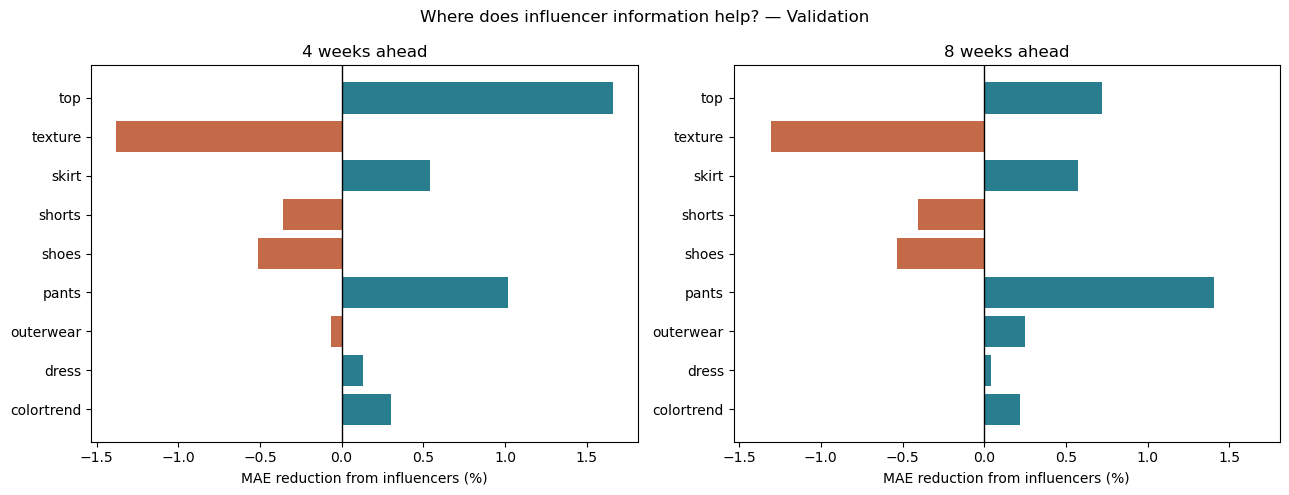

Positive = improvement; negative = worse.
These are exploratory differences, not significance tests.


In [31]:
paired_parts = []

for horizon, predictions in [
    (4, predictions_h4),
    (8, predictions_h8),
]:
    keys = ["forecast_date", "date", "item", "horizon"]

    without = predictions.loc[
        predictions["with_influencer"].eq("no"),
        keys + ["actual", "predicted"],
    ].rename(columns={"predicted": "predicted_without"})

    with_signal = predictions.loc[
        predictions["with_influencer"].eq("yes"),
        keys + ["actual", "predicted"],
    ].rename(columns={
        "actual": "actual_with",
        "predicted": "predicted_with",
    })

    paired = without.merge(
        with_signal,
        on=keys,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    assert paired["_merge"].eq("both").all()
    assert np.allclose(paired["actual"], paired["actual_with"])

    paired = paired.drop(columns=["_merge", "actual_with"])

    # IDs contain region, gender, category and a final series number.
    paired["category"] = (
        paired["item"].astype(str)
        .str.extract(
            r"^[^_]+_[^_]+_(.+)_\d+$",
            expand=False,
        )
    )
    assert paired["category"].notna().all()

    paired["error_without"] = (
        paired["actual"] - paired["predicted_without"]
    ).abs()

    paired["error_with"] = (
        paired["actual"] - paired["predicted_with"]
    ).abs()

    paired["error_reduction"] = (
        paired["error_without"] - paired["error_with"]
    )

    paired_parts.append(paired)

paired_validation = pd.concat(paired_parts, ignore_index=True)

# Average errors within each series first.
series_effects = (
    paired_validation.groupby(
        ["horizon", "category", "item"],
        observed=True,
    )
    .agg(
        mae_without=("error_without", "mean"),
        mae_with=("error_with", "mean"),
        n_predictions=("actual", "size"),
    )
    .reset_index()
)

series_effects["improved"] = (
    series_effects["mae_with"] < series_effects["mae_without"]
)

category_effects = (
    series_effects.groupby(
        ["horizon", "category"], observed=True
    )
    .agg(
        n_series=("item", "nunique"),
        mae_without=("mae_without", "mean"),
        mae_with=("mae_with", "mean"),
        share_series_improved=("improved", "mean"),
    )
    .reset_index()
)

category_effects["series_improved_percent"] = (
    100 * category_effects.pop("share_series_improved")
)

category_effects["mae_reduction_percent"] = (
    100
    * (category_effects["mae_without"] - category_effects["mae_with"])
    / category_effects["mae_without"].replace(0, np.nan)
)

# Average across all series for each target week.
weekly_effects = (
    paired_validation.groupby(["horizon", "date"])
    .agg(
        mae_without=("error_without", "mean"),
        mae_with=("error_with", "mean"),
    )
    .reset_index()
)

weekly_effects["mae_reduction_percent"] = (
    100
    * (weekly_effects["mae_without"] - weekly_effects["mae_with"])
    / weekly_effects["mae_without"].replace(0, np.nan)
)

weekly_summary = (
    weekly_effects.assign(
        helped=lambda d: d["mae_with"] < d["mae_without"]
    )
    .groupby("horizon")
    .agg(
        validation_weeks=("date", "size"),
        weeks_improved=("helped", "sum"),
        share_weeks_improved=("helped", "mean"),
    )
    .reset_index()
)

weekly_summary["weeks_improved_percent"] = (
    100 * weekly_summary.pop("share_weeks_improved")
)

print("Results by category:")
display(category_effects.round(4))

print("\nConsistency across validation weeks:")
display(weekly_summary.round(2))

# Save analysis tables.
for filename, table in [
    ("influencer_effect_by_series_validation.csv", series_effects),
    ("influencer_effect_by_category_validation.csv", category_effects),
    ("influencer_effect_by_week_validation.csv", weekly_effects),
    ("influencer_weekly_summary_validation.csv", weekly_summary),
]:
    table.to_csv(MODEL_DIR / filename, index=False)

# Visualise category differences.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

category_order = sorted(category_effects["category"].unique())

for ax, horizon in zip(axes, HORIZONS):
    values = (
        category_effects.loc[
            category_effects["horizon"].eq(horizon)
        ]
        .set_index("category")
        .reindex(category_order)
    )

    reductions = values["mae_reduction_percent"]

    ax.barh(
        category_order,
        reductions,
        color=np.where(reductions >= 0, "#287D8E", "#C56A49"),
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{horizon} weeks ahead")
    ax.set_xlabel("MAE reduction from influencers (%)")

fig.suptitle("Where does influencer information help? — Validation")
plt.tight_layout()
plt.savefig(
    MODEL_DIR / "influencer_effect_by_category_validation.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Positive = improvement; negative = worse.")
print("These are exploratory differences, not significance tests.")

## 26. Check Uncertainty in Influencer Contribution

Use a paired moving-block bootstrap of weekly average errors.

Both model versions are resampled together, keeping neighbouring
weeks in blocks and all series together within each week.
This accounts for some dependence across weeks and between series.

We examine block lengths of 4, 8 and 13 weeks and report approximate
95% confidence intervals for the percentage reduction in MAE.

- Entire interval above zero: evidence of improvement.
- Interval includes zero: the direction of the benefit is uncertain.
- Entire interval below zero: evidence of worse performance.

Only 39 validation weeks are available, so intervals are exploratory.
They do not account for model selection, retraining uncertainty or
variation across random seeds, and they do not establish causation.

In [32]:
def paired_block_bootstrap(
    weekly_table,
    block_length,
    n_bootstrap=5000,
    seed=42,
):
    """Resample consecutive weekly blocks for both models together."""
    ordered = weekly_table.sort_values("date").reset_index(drop=True)

    dates = pd.DatetimeIndex(ordered["date"])
    assert dates.is_unique
    assert (
        dates.to_series().diff().dropna()
        == pd.Timedelta(weeks=1)
    ).all()

    errors = ordered[
        ["mae_without", "mae_with"]
    ].to_numpy(dtype=float)

    assert np.isfinite(errors).all()

    n_weeks = len(errors)
    if not 1 <= block_length <= n_weeks:
        raise ValueError("Invalid block length.")

    rng = np.random.default_rng(seed)
    blocks_needed = int(np.ceil(n_weeks / block_length))

    # Non-circular moving blocks: no artificial end-to-start joining.
    starts = rng.integers(
        0,
        n_weeks - block_length + 1,
        size=(n_bootstrap, blocks_needed),
    )

    indices = (
        starts[:, :, None]
        + np.arange(block_length)[None, None, :]
    ).reshape(n_bootstrap, -1)[:, :n_weeks]

    boot_means = errors[indices].mean(axis=1)

    assert (boot_means[:, 0] > 0).all()

    boot_reduction = (
        100
        * (boot_means[:, 0] - boot_means[:, 1])
        / boot_means[:, 0]
    )

    mean_without, mean_with = errors.mean(axis=0)
    observed = 100 * (mean_without - mean_with) / mean_without

    ci_low, ci_high = np.quantile(
        boot_reduction, [0.025, 0.975]
    )

    if ci_low > 0:
        interpretation = "interval supports improvement"
    elif ci_high < 0:
        interpretation = "interval supports worse performance"
    else:
        interpretation = "interval includes zero: uncertain"

    return {
        "validation_weeks": n_weeks,
        "block_length_weeks": block_length,
        "bootstrap_repeats": n_bootstrap,
        "mae_reduction_percent": observed,
        "ci_low_percent": ci_low,
        "ci_high_percent": ci_high,
        "interpretation": interpretation,
    }


bootstrap_rows = []

for horizon in HORIZONS:
    weekly = weekly_effects.loc[
        weekly_effects["horizon"].eq(horizon)
    ]

    for block_length in [4, 8, 13]:
        result = paired_block_bootstrap(
            weekly,
            block_length=block_length,
            seed=MODEL_SEED,
        )

        bootstrap_rows.append({
            "horizon": horizon,
            "period": "validation",
            **result,
        })

bootstrap_results = pd.DataFrame(bootstrap_rows)

bootstrap_results.to_csv(
    MODEL_DIR / "influencer_block_bootstrap_validation.csv",
    index=False,
)

display(bootstrap_results.round(4))

print(
    "\nRead all three block lengths together; "
    "do not select only the most favourable interval."
)
print("Test period remains unused.")

,horizon,period,validation_weeks,block_length_weeks,bootstrap_repeats,mae_reduction_percent,ci_low_percent,ci_high_percent,interpretation
0,4,validation,39,4,5000,0.2641,-0.0166,0.5975,interval includes zero: uncertain
1,4,validation,39,8,5000,0.2641,0.0849,0.5490,interval supports improvement
2,4,validation,39,13,5000,0.2641,0.1056,0.4450,interval supports improvement
3,8,validation,39,4,5000,0.2520,-0.0691,0.5546,interval includes zero: uncertain
4,8,validation,39,8,5000,0.2520,-0.1203,0.5334,interval includes zero: uncertain
5,8,validation,39,13,5000,0.2520,-0.1598,0.3983,interval includes zero: uncertain



Read all three block lengths together; do not select only the most favourable interval.
Test period remains unused.


Influencer inputs reduced validation MAE by approximately 0.26% at four weeks and 0.25% at eight weeks. However, the four-week finding was sensitive to bootstrap block length, while all eight-week confidence intervals included zero. The additional forecasting value of influencer information therefore remains uncertain.

## 27. Tune the Number of Trees — Four-Week Horizon

Compare 300, 500 and 1,000 trees using the same walk-forward validation.

All other settings remain unchanged. Each setting is tested both
with and without influencer information.

Select the tree count using the popularity-only model's validation
MAE, then apply that count to both versions. This keeps the influencer
comparison controlled.

These validation scores are used for development. Final performance
will be assessed on the reserved test period.

In [33]:
# Rebuild the four-week inputs; release eight-week inputs first.
if "X_h8" in globals():
    del X_h8, metadata_h8
    gc.collect()

X_h4, metadata_h4 = build_model_table(horizon=4)

for column in ["item", "period"]:
    metadata_h4[column] = metadata_h4[column].astype("category")

# Keep tuning outputs separate from the original experiment.
BASE_MODEL_DIR = MODEL_DIR
TUNING_DIR = BASE_MODEL_DIR / "tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

TREE_COUNTS = [300, 500, 1000]
tuning_rows_h4 = []

for tree_count in TREE_COUNTS:
    print(f"\nChecking {tree_count} trees...", flush=True)

    params = LGBM_PARAMS.copy()
    params["n_estimators"] = tree_count

    if tree_count == LGBM_PARAMS["n_estimators"]:
        # Reuse the completed experiment.
        candidate_predictions = predictions_h4
        print("Reusing existing predictions.", flush=True)

    else:
        candidate_dir = TUNING_DIR / f"h4_trees_{tree_count}"
        candidate_dir.mkdir(parents=True, exist_ok=True)

        # The existing function saves to MODEL_DIR.
        # Restore it even if this run encounters an error.
        try:
            MODEL_DIR = candidate_dir

            with open(candidate_dir / "parameters.json", "w") as file:
                json.dump(params, file, indent=2)

            candidate_predictions, candidate_log, candidate_importance = (
                run_validation_forecasts(
                    X_h4, metadata_h4, params
                )
            )
        finally:
            MODEL_DIR = BASE_MODEL_DIR

    for flag in ["no", "yes"]:
        subset = candidate_predictions.loc[
            candidate_predictions["with_influencer"].eq(flag)
        ]

        scores = score_prediction_rows(subset)

        tuning_rows_h4.append({
            "horizon": 4,
            "period": "validation",
            "n_estimators": tree_count,
            "with_influencer": flag,
            "mae": scores["mae"],
            "mase_train_m1": scores["mase"],
            "n_predictions": scores["n_predictions"],
        })

    # Save progress after each completed setting.
    pd.DataFrame(tuning_rows_h4).to_csv(
        TUNING_DIR / "tree_count_scores_4w.csv",
        index=False,
    )

tuning_scores_h4 = pd.DataFrame(tuning_rows_h4)

display(
    tuning_scores_h4.sort_values(
        ["with_influencer", "mae"]
    ).round(6)
)

# Select using ONLY the version without influencers.
selection = (
    tuning_scores_h4.loc[
        tuning_scores_h4["with_influencer"].eq("no")
    ]
    .sort_values(["mae", "n_estimators"])
    .iloc[0]
)

selected_trees_h4 = int(selection["n_estimators"])

print(
    "\nSelected tree count for both four-week versions:",
    selected_trees_h4,
)
print("Selection used popularity-only validation MAE.")
print("Test period remains unused.")

4-week horizon: prepared 40/165 forecast weeks
4-week horizon: prepared 80/165 forecast weeks
4-week horizon: prepared 120/165 forecast weeks
4-week horizon: prepared 160/165 forecast weeks
4-week horizon: prepared 165/165 forecast weeks

Checking 300 trees...
Block 1/10 | refit 2018-06-04 | influencers=no | 5.1 seconds
Block 1/10 | refit 2018-06-04 | influencers=yes | 6.1 seconds
Block 2/10 | refit 2018-07-02 | influencers=no | 5.2 seconds
Block 2/10 | refit 2018-07-02 | influencers=yes | 6.3 seconds
Block 3/10 | refit 2018-07-30 | influencers=no | 5.4 seconds
Block 3/10 | refit 2018-07-30 | influencers=yes | 6.5 seconds
Block 4/10 | refit 2018-08-27 | influencers=no | 5.9 seconds
Block 4/10 | refit 2018-08-27 | influencers=yes | 6.6 seconds
Block 5/10 | refit 2018-09-24 | influencers=no | 5.8 seconds
Block 5/10 | refit 2018-09-24 | influencers=yes | 6.9 seconds
Block 6/10 | refit 2018-10-22 | influencers=no | 6.0 seconds
Block 6/10 | refit 2018-10-22 | influencers=yes | 7.2 seconds
B

,horizon,period,n_estimators,with_influencer,mae,mase_train_m1,n_predictions
4,4,validation,1000,no,0.002877,0.745522,390000
2,4,validation,500,no,0.002951,0.760066,390000
0,4,validation,300,no,0.003028,0.775228,390000
5,4,validation,1000,yes,0.002866,0.742367,390000
3,4,validation,500,yes,0.002943,0.758313,390000
1,4,validation,300,yes,0.003020,0.774999,390000



Selected tree count for both four-week versions: 1000
Selection used popularity-only validation MAE.
Test period remains unused.


## 28. Tune the Number of Trees — Eight-Week Horizon

Compare 300, 500 and 1,000 trees using walk-forward validation.

Select the tree count using popularity-only validation MAE.
Apply the selected count to both versions so the influencer comparison
uses identical settings.

Save the selected settings for both horizons before final testing.

In [34]:
# Release four-week input tables to reduce memory use.
if "X_h4" in globals():
    del X_h4, metadata_h4
    gc.collect()

X_h8, metadata_h8 = build_model_table(horizon=8)

for column in ["item", "period"]:
    metadata_h8[column] = metadata_h8[column].astype("category")

tuning_rows_h8 = []

for tree_count in TREE_COUNTS:
    print(f"\nChecking {tree_count} trees...", flush=True)

    params = LGBM_PARAMS.copy()
    params["n_estimators"] = tree_count

    if tree_count == LGBM_PARAMS["n_estimators"]:
        candidate_predictions = predictions_h8
        print("Reusing existing predictions.", flush=True)

    else:
        candidate_dir = TUNING_DIR / f"h8_trees_{tree_count}"
        candidate_dir.mkdir(parents=True, exist_ok=True)

        try:
            MODEL_DIR = candidate_dir

            with open(candidate_dir / "parameters.json", "w") as file:
                json.dump(params, file, indent=2)

            candidate_predictions, candidate_log, candidate_importance = (
                run_validation_forecasts(
                    X_h8, metadata_h8, params
                )
            )
        finally:
            MODEL_DIR = BASE_MODEL_DIR

    for flag in ["no", "yes"]:
        subset = candidate_predictions.loc[
            candidate_predictions["with_influencer"].eq(flag)
        ]

        scores = score_prediction_rows(subset)

        tuning_rows_h8.append({
            "horizon": 8,
            "period": "validation",
            "n_estimators": tree_count,
            "with_influencer": flag,
            "mae": scores["mae"],
            "mase_train_m1": scores["mase"],
            "n_predictions": scores["n_predictions"],
        })

    pd.DataFrame(tuning_rows_h8).to_csv(
        TUNING_DIR / "tree_count_scores_8w.csv",
        index=False,
    )

tuning_scores_h8 = pd.DataFrame(tuning_rows_h8)

display(
    tuning_scores_h8.sort_values(
        ["with_influencer", "mae"]
    ).round(6)
)

selection = (
    tuning_scores_h8.loc[
        tuning_scores_h8["with_influencer"].eq("no")
    ]
    .sort_values(["mae", "n_estimators"])
    .iloc[0]
)

selected_trees_h8 = int(selection["n_estimators"])

# Record the selected parameters for both horizons.
selected_params = {}

for horizon, tree_count in [
    (4, selected_trees_h4),
    (8, selected_trees_h8),
]:
    selected_params[horizon] = {
        **LGBM_PARAMS,
        "n_estimators": tree_count,
    }

with open(BASE_MODEL_DIR / "selected_parameters.json", "w") as file:
    json.dump(selected_params, file, indent=2)

all_tuning_scores = pd.concat(
    [tuning_scores_h4, tuning_scores_h8],
    ignore_index=True,
)

all_tuning_scores.to_csv(
    TUNING_DIR / "tree_count_scores_both_horizons.csv",
    index=False,
)

print("\nSelected tree counts:")
print("4 weeks:", selected_trees_h4)
print("8 weeks:", selected_trees_h8)
print("\nSettings saved. Test period remains unused.")

8-week horizon: prepared 40/161 forecast weeks
8-week horizon: prepared 80/161 forecast weeks
8-week horizon: prepared 120/161 forecast weeks
8-week horizon: prepared 160/161 forecast weeks
8-week horizon: prepared 161/161 forecast weeks

Checking 300 trees...
Block 1/10 | refit 2018-05-07 | influencers=no | 5.5 seconds
Block 1/10 | refit 2018-05-07 | influencers=yes | 6.7 seconds
Block 2/10 | refit 2018-06-04 | influencers=no | 5.9 seconds
Block 2/10 | refit 2018-06-04 | influencers=yes | 7.4 seconds
Block 3/10 | refit 2018-07-02 | influencers=no | 5.9 seconds
Block 3/10 | refit 2018-07-02 | influencers=yes | 7.8 seconds
Block 4/10 | refit 2018-07-30 | influencers=no | 6.3 seconds
Block 4/10 | refit 2018-07-30 | influencers=yes | 8.3 seconds
Block 5/10 | refit 2018-08-27 | influencers=no | 7.6 seconds
Block 5/10 | refit 2018-08-27 | influencers=yes | 9.2 seconds
Block 6/10 | refit 2018-09-24 | influencers=no | 8.0 seconds
Block 6/10 | refit 2018-09-24 | influencers=yes | 12.2 seconds


,horizon,period,n_estimators,with_influencer,mae,mase_train_m1,n_predictions
4,8,validation,1000,no,0.003085,0.807581,390000
2,8,validation,500,no,0.003151,0.821669,390000
0,8,validation,300,no,0.003207,0.834140,390000
5,8,validation,1000,yes,0.003076,0.804462,390000
3,8,validation,500,yes,0.003143,0.819893,390000
1,8,validation,300,yes,0.003198,0.832777,390000



Selected tree counts:
4 weeks: 1000
8 weeks: 1000

Settings saved. Test period remains unused.


## 29. Load the Selected Validation Predictions

Load predictions using the tree count selected for each horizon.
Keep the original 500-tree predictions separately for reference.

Subsequent analyses will use the selected settings.
The test period remains unused.

In [35]:
# Preserve the initial results.
predictions_h4_initial = predictions_h4.copy()
predictions_h8_initial = predictions_h8.copy()

selected_validation = {}

for horizon, tree_count in [
    (4, selected_trees_h4),
    (8, selected_trees_h8),
]:
    if tree_count == LGBM_PARAMS["n_estimators"]:
        source_dir = BASE_MODEL_DIR
    else:
        source_dir = TUNING_DIR / f"h{horizon}_trees_{tree_count}"

    parts = []

    for flag in ["no", "yes"]:
        path = source_dir / (
            f"predictions_{horizon}w_influencer_{flag}_validation.csv.gz"
        )

        if not path.is_file():
            raise FileNotFoundError(f"Missing predictions: {path}")

        # Read yes/no as text, preserving the agreed labels.
        rows = pd.read_csv(
            path,
            dtype={"item": str, "with_influencer": str},
            parse_dates=["date", "forecast_date", "refit_date"],
        )

        assert rows["with_influencer"].eq(flag).all()
        assert rows["horizon"].eq(horizon).all()
        assert rows["period"].eq("validation").all()
        assert len(rows) == 39 * len(model_items)

        assert (
            rows["date"] - rows["forecast_date"]
        ).eq(pd.Timedelta(weeks=horizon)).all()

        assert not rows.duplicated(
            ["date", "item", "horizon"]
        ).any()

        rows["n_estimators"] = tree_count
        parts.append(rows)

    selected_validation[horizon] = pd.concat(
        parts, ignore_index=True
    )

# Use selected predictions in subsequent analysis.
predictions_h4 = selected_validation[4]
predictions_h8 = selected_validation[8]

selected_validation_scores = pd.concat(
    [
        compare_validation_models(predictions_h4, 4),
        compare_validation_models(predictions_h8, 8),
    ],
    ignore_index=True,
)

selected_validation_scores["n_estimators"] = (
    selected_validation_scores["horizon"]
    .map({4: selected_trees_h4, 8: selected_trees_h8})
    .where(
        selected_validation_scores["model"].eq(
            "lightgbm_seasonal_correction"
        )
    )
    .astype("Int64")
)

selected_validation_scores.to_csv(
    BASE_MODEL_DIR / "scores_selected_validation.csv",
    index=False,
)

display(
    selected_validation_scores[
        [
            "model", "with_influencer", "horizon",
            "n_estimators", "mae", "mase_train_m1",
            "relative_mae_vs_four_week_average",
        ]
    ].round(6)
)

print("\nSelected validation predictions loaded.")
print("No models retrained. Test period remains unused.")

,model,with_influencer,horizon,n_estimators,mae,mase_train_m1,relative_mae_vs_four_week_average
0,lightgbm_seasonal_correction,yes,4,1000,0.002866,0.742367,0.612671
1,lightgbm_seasonal_correction,no,4,1000,0.002877,0.745522,0.615081
2,seasonal_naive,not_applicable,4,<NA>,0.003518,0.944008,0.752191
3,last_value,not_applicable,4,<NA>,0.004459,1.055599,0.953295
4,four_week_average,not_applicable,4,<NA>,0.004677,1.062286,1.000000
5,lightgbm_seasonal_correction,yes,8,1000,0.003076,0.804462,0.476298
6,lightgbm_seasonal_correction,no,8,1000,0.003085,0.807581,0.477805
7,seasonal_naive,not_applicable,8,<NA>,0.003518,0.944008,0.544800
8,last_value,not_applicable,8,<NA>,0.006217,1.398347,0.962812
9,four_week_average,not_applicable,8,<NA>,0.006458,1.413411,1.000000



Selected validation predictions loaded.
No models retrained. Test period remains unused.


Results by category:


,horizon,category,n_series,mae_without,mae_with,series_improved_percent,mae_reduction_percent
0,4,colortrend,430,0.0020,0.0020,56.5116,0.1581
1,4,dress,118,0.0034,0.0034,50.0000,0.2057
2,4,outerwear,1757,0.0038,0.0038,53.1019,0.0938
3,4,pants,1264,0.0039,0.0038,60.0475,1.3969
4,4,shoes,1924,0.0027,0.0027,51.6112,-0.0838
5,4,shorts,369,0.0111,0.0112,45.7995,-0.5609
6,4,skirt,142,0.0109,0.0108,67.6056,0.8250
7,4,texture,840,0.0010,0.0010,54.6429,-1.5068
8,4,top,3156,0.0014,0.0013,55.6084,1.4802
9,8,colortrend,430,0.0022,0.0022,55.5814,0.3471



Consistency across validation weeks:


,horizon,validation_weeks,weeks_improved,weeks_improved_percent
0,4,39,27,69.23
1,8,39,24,61.54


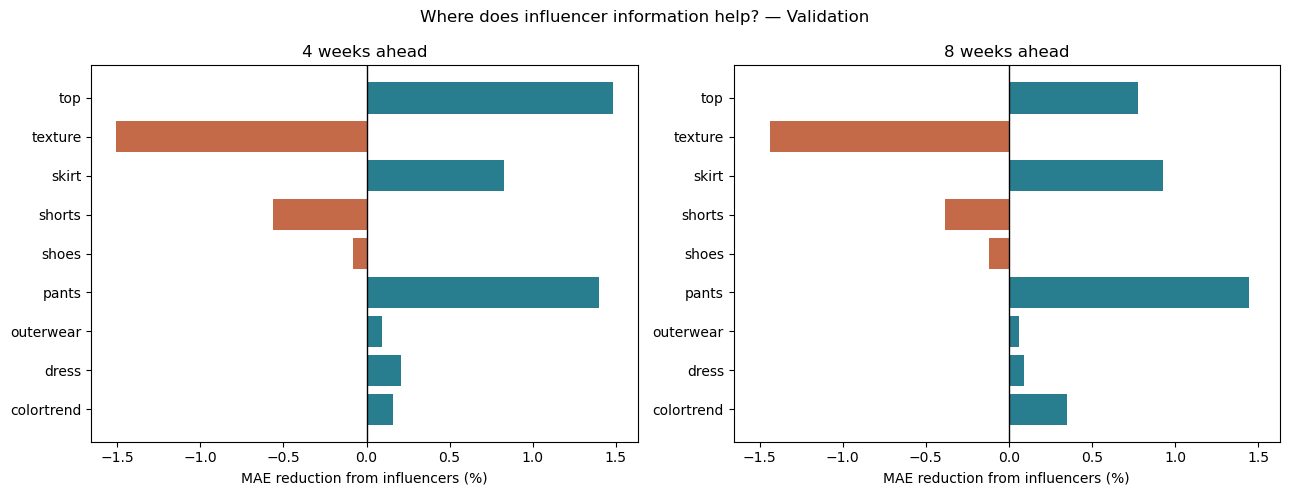

Positive = improvement; negative = worse.
These are exploratory differences, not significance tests.


In [36]:
paired_parts = []

for horizon, predictions in [
    (4, predictions_h4),
    (8, predictions_h8),
]:
    keys = ["forecast_date", "date", "item", "horizon"]

    without = predictions.loc[
        predictions["with_influencer"].eq("no"),
        keys + ["actual", "predicted"],
    ].rename(columns={"predicted": "predicted_without"})

    with_signal = predictions.loc[
        predictions["with_influencer"].eq("yes"),
        keys + ["actual", "predicted"],
    ].rename(columns={
        "actual": "actual_with",
        "predicted": "predicted_with",
    })

    paired = without.merge(
        with_signal,
        on=keys,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    assert paired["_merge"].eq("both").all()
    assert np.allclose(paired["actual"], paired["actual_with"])

    paired = paired.drop(columns=["_merge", "actual_with"])

    # IDs contain region, gender, category and a final series number.
    paired["category"] = (
        paired["item"].astype(str)
        .str.extract(
            r"^[^_]+_[^_]+_(.+)_\d+$",
            expand=False,
        )
    )
    assert paired["category"].notna().all()

    paired["error_without"] = (
        paired["actual"] - paired["predicted_without"]
    ).abs()

    paired["error_with"] = (
        paired["actual"] - paired["predicted_with"]
    ).abs()

    paired["error_reduction"] = (
        paired["error_without"] - paired["error_with"]
    )

    paired_parts.append(paired)

paired_validation = pd.concat(paired_parts, ignore_index=True)

# Average errors within each series first.
series_effects = (
    paired_validation.groupby(
        ["horizon", "category", "item"],
        observed=True,
    )
    .agg(
        mae_without=("error_without", "mean"),
        mae_with=("error_with", "mean"),
        n_predictions=("actual", "size"),
    )
    .reset_index()
)

series_effects["improved"] = (
    series_effects["mae_with"] < series_effects["mae_without"]
)

category_effects = (
    series_effects.groupby(
        ["horizon", "category"], observed=True
    )
    .agg(
        n_series=("item", "nunique"),
        mae_without=("mae_without", "mean"),
        mae_with=("mae_with", "mean"),
        share_series_improved=("improved", "mean"),
    )
    .reset_index()
)

category_effects["series_improved_percent"] = (
    100 * category_effects.pop("share_series_improved")
)

category_effects["mae_reduction_percent"] = (
    100
    * (category_effects["mae_without"] - category_effects["mae_with"])
    / category_effects["mae_without"].replace(0, np.nan)
)

# Average across all series for each target week.
weekly_effects = (
    paired_validation.groupby(["horizon", "date"])
    .agg(
        mae_without=("error_without", "mean"),
        mae_with=("error_with", "mean"),
    )
    .reset_index()
)

weekly_effects["mae_reduction_percent"] = (
    100
    * (weekly_effects["mae_without"] - weekly_effects["mae_with"])
    / weekly_effects["mae_without"].replace(0, np.nan)
)

weekly_summary = (
    weekly_effects.assign(
        helped=lambda d: d["mae_with"] < d["mae_without"]
    )
    .groupby("horizon")
    .agg(
        validation_weeks=("date", "size"),
        weeks_improved=("helped", "sum"),
        share_weeks_improved=("helped", "mean"),
    )
    .reset_index()
)

weekly_summary["weeks_improved_percent"] = (
    100 * weekly_summary.pop("share_weeks_improved")
)

print("Results by category:")
display(category_effects.round(4))

print("\nConsistency across validation weeks:")
display(weekly_summary.round(2))

# Save analysis tables.
for filename, table in [
    ("influencer_effect_by_series_validation.csv", series_effects),
    ("influencer_effect_by_category_validation.csv", category_effects),
    ("influencer_effect_by_week_validation.csv", weekly_effects),
    ("influencer_weekly_summary_validation.csv", weekly_summary),
]:
    table.to_csv(MODEL_DIR / filename, index=False)

# Visualise category differences.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

category_order = sorted(category_effects["category"].unique())

for ax, horizon in zip(axes, HORIZONS):
    values = (
        category_effects.loc[
            category_effects["horizon"].eq(horizon)
        ]
        .set_index("category")
        .reindex(category_order)
    )

    reductions = values["mae_reduction_percent"]

    ax.barh(
        category_order,
        reductions,
        color=np.where(reductions >= 0, "#287D8E", "#C56A49"),
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{horizon} weeks ahead")
    ax.set_xlabel("MAE reduction from influencers (%)")

fig.suptitle("Where does influencer information help? — Validation")
plt.tight_layout()
plt.savefig(
    MODEL_DIR / "influencer_effect_by_category_validation.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Positive = improvement; negative = worse.")
print("These are exploratory differences, not significance tests.")

In [37]:
def paired_block_bootstrap(
    weekly_table,
    block_length,
    n_bootstrap=5000,
    seed=42,
):
    """Resample consecutive weekly blocks for both models together."""
    ordered = weekly_table.sort_values("date").reset_index(drop=True)

    dates = pd.DatetimeIndex(ordered["date"])
    assert dates.is_unique
    assert (
        dates.to_series().diff().dropna()
        == pd.Timedelta(weeks=1)
    ).all()

    errors = ordered[
        ["mae_without", "mae_with"]
    ].to_numpy(dtype=float)

    assert np.isfinite(errors).all()

    n_weeks = len(errors)
    if not 1 <= block_length <= n_weeks:
        raise ValueError("Invalid block length.")

    rng = np.random.default_rng(seed)
    blocks_needed = int(np.ceil(n_weeks / block_length))

    # Non-circular moving blocks: no artificial end-to-start joining.
    starts = rng.integers(
        0,
        n_weeks - block_length + 1,
        size=(n_bootstrap, blocks_needed),
    )

    indices = (
        starts[:, :, None]
        + np.arange(block_length)[None, None, :]
    ).reshape(n_bootstrap, -1)[:, :n_weeks]

    boot_means = errors[indices].mean(axis=1)

    assert (boot_means[:, 0] > 0).all()

    boot_reduction = (
        100
        * (boot_means[:, 0] - boot_means[:, 1])
        / boot_means[:, 0]
    )

    mean_without, mean_with = errors.mean(axis=0)
    observed = 100 * (mean_without - mean_with) / mean_without

    ci_low, ci_high = np.quantile(
        boot_reduction, [0.025, 0.975]
    )

    if ci_low > 0:
        interpretation = "interval supports improvement"
    elif ci_high < 0:
        interpretation = "interval supports worse performance"
    else:
        interpretation = "interval includes zero: uncertain"

    return {
        "validation_weeks": n_weeks,
        "block_length_weeks": block_length,
        "bootstrap_repeats": n_bootstrap,
        "mae_reduction_percent": observed,
        "ci_low_percent": ci_low,
        "ci_high_percent": ci_high,
        "interpretation": interpretation,
    }


bootstrap_rows = []

for horizon in HORIZONS:
    weekly = weekly_effects.loc[
        weekly_effects["horizon"].eq(horizon)
    ]

    for block_length in [4, 8, 13]:
        result = paired_block_bootstrap(
            weekly,
            block_length=block_length,
            seed=MODEL_SEED,
        )

        bootstrap_rows.append({
            "horizon": horizon,
            "period": "validation",
            **result,
        })

bootstrap_results = pd.DataFrame(bootstrap_rows)

bootstrap_results.to_csv(
    MODEL_DIR / "influencer_block_bootstrap_validation.csv",
    index=False,
)

display(bootstrap_results.round(4))

print(
    "\nRead all three block lengths together; "
    "do not select only the most favourable interval."
)
print("Test period remains unused.")

,horizon,period,validation_weeks,block_length_weeks,bootstrap_repeats,mae_reduction_percent,ci_low_percent,ci_high_percent,interpretation
0,4,validation,39,4,5000,0.3919,0.1056,0.7159,interval supports improvement
1,4,validation,39,8,5000,0.3919,0.1833,0.6594,interval supports improvement
2,4,validation,39,13,5000,0.3919,0.2731,0.5174,interval supports improvement
3,8,validation,39,4,5000,0.3153,0.0313,0.6522,interval supports improvement
4,8,validation,39,8,5000,0.3153,0.0664,0.5877,interval supports improvement
5,8,validation,39,13,5000,0.3153,0.0703,0.4641,interval supports improvement



Read all three block lengths together; do not select only the most favourable interval.
Test period remains unused.


## 30. Freeze Settings Before Final Testing

Validation selected 1,000 trees for both forecast horizons.
Use identical settings for models with and without influencer inputs.

The final evaluation includes all 10,000 series and all 40 test weeks.
Models are retrained every four forecast weeks, using only answers
available on each refit date.

Earlier test observations may enter later training once they become
available. Test results will not be used to change model settings,
select categories or remove difficult weeks.

Report MAE, training-based MASE and relative MAE against the
four-week-average baseline separately.

In [38]:
FINAL_DIR = BASE_MODEL_DIR / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

test_dates = split_by_date.index[
    split_by_date.eq("test")
]

# Copy the selected settings so later changes to initial settings
# do not accidentally change the final experiment.
FINAL_PARAMS = {
    horizon: selected_params[horizon].copy()
    for horizon in HORIZONS
}

final_protocol = {
    "model": "lightgbm_seasonal_correction",
    "target": "single_week_popularity",
    "horizons_weeks": list(HORIZONS),
    "series_count": len(model_items),
    "test_target_start": str(test_dates.min().date()),
    "test_target_end": str(test_dates.max().date()),
    "test_target_weeks": len(test_dates),
    "refit_every_forecast_weeks": REFIT_EVERY,
    "training_rule": "training target date <= refit date",
    "forecast_rule": "seasonal reference + predicted adjustment",
    "clip_forecasts_at_zero": True,
    "with_influencer_versions": ["no", "yes"],
    "parameters_by_horizon": FINAL_PARAMS,
    "metrics": [
        "mae",
        "mase_train_m1",
        "relative_mae_vs_four_week_average",
    ],
    "bootstrap_block_lengths_weeks": [4, 8, 13],
    "bootstrap_repeats": 5000,
}

with open(FINAL_DIR / "evaluation_protocol.json", "w") as file:
    json.dump(final_protocol, file, indent=2)

display(pd.DataFrame([
    {
        "horizon": horizon,
        "trees": FINAL_PARAMS[horizon]["n_estimators"],
        "test_weeks": len(test_dates),
        "series": len(model_items),
        "predictions_per_version": len(test_dates) * len(model_items),
    }
    for horizon in HORIZONS
]))

print("Final settings saved.")
print("No test predictions generated yet.")

,horizon,trees,test_weeks,series,predictions_per_version
0,4,1000,40,10000,400000
1,8,1000,40,10000,400000


Final settings saved.
No test predictions generated yet.


## 31. Prepare Four-Week Final-Test Examples

Build features using the same definitions as the validation experiment,
now allowing targets in the reserved test period.

Keep historical examples for training and mark test examples separately.
Before every model fit, training targets will be restricted to answers
already known on that refit date.

No test scores are calculated in this section.

In [40]:
def build_final_examples(forecast_pos, horizon):
    """Same inputs as validation, allowing final-test target dates."""
    target_pos = forecast_pos + horizon

    if horizon not in HORIZONS:
        raise ValueError("Unsupported horizon.")

    if forecast_pos < max(POPULARITY_LAGS):
        raise ValueError("Insufficient history.")

    if target_pos >= len(popularity):
        raise ValueError("Target is beyond the dataset.")

    target_date = popularity.index[target_pos]
    features = {}

    for prefix, data, lags in [
        ("pop", popularity, POPULARITY_LAGS),
        ("inf", influencer, INFLUENCER_LAGS),
    ]:
        for lag in lags:
            features[f"{prefix}_lag_{lag}"] = (
                data.iloc[forecast_pos - lag].to_numpy()
            )

        for window in ROLLING_WINDOWS:
            features[f"{prefix}_mean_{window}"] = (
                data.iloc[
                    forecast_pos - window + 1:forecast_pos + 1
                ]
                .mean(axis=0)
                .to_numpy()
            )

        for gap in [1, 4]:
            features[f"{prefix}_change_{gap}"] = (
                features[f"{prefix}_lag_0"]
                - features[f"{prefix}_lag_{gap}"]
            )

        features[f"{prefix}_std_8"] = (
            data.iloc[forecast_pos - 7:forecast_pos + 1]
            .std(axis=0, ddof=0)
            .to_numpy()
        )

    angle = 2 * np.pi * (target_date.dayofyear - 1) / 365.25
    features["target_week_sin"] = np.sin(angle)
    features["target_week_cos"] = np.cos(angle)

    seasonal_pos = target_pos - SEASONAL_PERIOD
    assert 0 <= seasonal_pos <= forecast_pos

    reference = popularity.iloc[seasonal_pos].to_numpy(
        dtype=np.float32
    )
    features[SEASONAL_FEATURE] = reference

    X = pd.DataFrame(
        features,
        index=pd.Index(popularity.columns, name="item"),
    )[comparison_inputs["yes"]].astype("float32")

    metadata = pd.DataFrame({
        "item": popularity.columns.to_numpy(),
        "forecast_date": popularity.index[forecast_pos],
        "date": target_date,
        "horizon": horizon,
        "period": split_by_date.loc[target_date],
        "actual": popularity.iloc[target_pos].to_numpy(),
        "seasonal_reference": reference,
    })

    metadata["residual_target"] = (
        metadata["actual"] - metadata["seasonal_reference"]
    )

    return X, metadata


# Verify that the new builder reproduces the validation inputs exactly.
check_pos = int(eligible_forecasts[("validation", 4)][0])

X_old, meta_old = build_seasonal_examples(check_pos, 4)
X_new, meta_new = build_final_examples(check_pos, 4)

pd.testing.assert_frame_equal(X_old, X_new)
pd.testing.assert_frame_equal(meta_old, meta_new)

print("Feature consistency check passed.")


def build_final_table(horizon):
    feature_parts = []
    metadata_parts = []

    positions = range(
        max(POPULARITY_LAGS),
        len(popularity) - horizon,
    )

    for number, position in enumerate(positions, start=1):
        X, metadata = build_final_examples(position, horizon)

        X = X.loc[model_items]
        metadata = (
            metadata.set_index("item")
            .loc[model_items]
            .rename_axis("item")
            .reset_index()
        )

        feature_parts.append(X.reset_index(drop=True))
        metadata_parts.append(metadata)

        if number % 50 == 0 or number == len(positions):
            print(
                f"Prepared {number}/{len(positions)} forecast weeks",
                flush=True,
            )

    X_all = pd.concat(feature_parts, ignore_index=True)
    metadata_all = pd.concat(metadata_parts, ignore_index=True)

    for column in ["item", "period"]:
        metadata_all[column] = metadata_all[column].astype("category")

    assert X_all.index.equals(metadata_all.index)
    assert np.isfinite(X_all.to_numpy()).all()

    return X_all, metadata_all


# Release the previous large input tables.
if "X_h8" in globals():
    del X_h8, metadata_h8
    gc.collect()

X_final_h4, metadata_final_h4 = build_final_table(horizon=4)

test_mask_h4 = metadata_final_h4["period"].eq("test")

assert test_mask_h4.sum() == len(test_dates) * len(model_items)
assert (
    metadata_final_h4["date"]
    - metadata_final_h4["forecast_date"]
).eq(pd.Timedelta(weeks=4)).all()

display(
    metadata_final_h4.groupby("period", observed=True)
    .agg(
        examples=("item", "size"),
        target_weeks=("date", "nunique"),
        first_target=("date", "min"),
        last_target=("date", "max"),
    )
    .reset_index()
)

print("\nFour-week final-test tables ready.")
print("No test forecasts generated or scored yet.")

Feature consistency check passed.
Prepared 50/205 forecast weeks
Prepared 100/205 forecast weeks
Prepared 150/205 forecast weeks
Prepared 200/205 forecast weeks
Prepared 205/205 forecast weeks


,period,examples,target_weeks,first_target,last_target
0,test,400000,40,2019-04-01,2019-12-30
1,training,1260000,126,2016-02-01,2018-06-25
2,validation,390000,39,2018-07-02,2019-03-25



Four-week final-test tables ready.
No test forecasts generated or scored yet.


## 32. Generate Four-Week Test Forecasts

Evaluate both LightGBM versions using the settings selected on validation.

Retrain every four forecast weeks. Each fit uses only targets already
known on its refit date. Earlier test observations may enter later
training once they become available.

Save predictions, models, feature importance and training logs.
Keep model settings unchanged after viewing test results.

In [41]:
def run_final_test(X, metadata, horizon):
    params = FINAL_PARAMS[horizon].copy()

    output_dir = FINAL_DIR / f"h{horizon}"
    output_dir.mkdir(parents=True, exist_ok=True)

    test_mask = metadata["period"].eq("test")
    forecast_dates = pd.DatetimeIndex(
        metadata.loc[test_mask, "forecast_date"]
        .drop_duplicates()
        .sort_values()
    )

    assert len(forecast_dates) == len(test_dates)

    prediction_parts = []
    log_rows = []
    importance_parts = []

    n_blocks = int(np.ceil(len(forecast_dates) / REFIT_EVERY))

    for block_number, start in enumerate(
        range(0, len(forecast_dates), REFIT_EVERY),
        start=1,
    ):
        block_dates = forecast_dates[start:start + REFIT_EVERY]
        refit_date = block_dates[0]

        train_mask = metadata["date"].le(refit_date)
        predict_mask = (
            test_mask
            & metadata["forecast_date"].isin(block_dates)
        )

        assert train_mask.any() and predict_mask.any()

        latest_training_target = metadata.loc[
            train_mask, "date"
        ].max()
        assert latest_training_target <= refit_date

        y_train = metadata.loc[
            train_mask, "residual_target"
        ].to_numpy()

        for flag, features in comparison_inputs.items():
            started = time.perf_counter()

            model = lgb.LGBMRegressor(**params)
            model.fit(X.loc[train_mask, features], y_train)

            adjustment = model.predict(
                X.loc[predict_mask, features]
            )

            output = metadata.loc[
                predict_mask,
                [
                    "date", "item", "horizon", "actual", "period",
                    "forecast_date", "seasonal_reference",
                ],
            ].copy()

            output["predicted"] = np.maximum(
                output["seasonal_reference"].to_numpy() + adjustment,
                0.0,
            )

            output["model"] = "lightgbm_seasonal_correction"
            output["with_influencer"] = flag
            output["refit_date"] = refit_date
            output["seed"] = params["random_state"]
            output["n_estimators"] = params["n_estimators"]

            assert np.isfinite(output["predicted"]).all()

            # Internal date convention remains target date.
            prediction_parts.append(output)

            # Shared exports use date = forecast date.
            shared = output.rename(
                columns={"date": "target_date"}
            ).copy()
            shared["date"] = shared["forecast_date"]

            shared = shared[
                [
                    "date", "item", "horizon", "actual", "predicted",
                    "model", "period", "with_influencer",
                    "target_date", "forecast_date", "refit_date",
                    "seed", "n_estimators", "seasonal_reference",
                ]
            ]

            shared.to_csv(
                output_dir / (
                    f"predictions_block_{block_number:02d}"
                    f"_influencer_{flag}.csv.gz"
                ),
                index=False,
                compression="gzip",
            )

            model.booster_.save_model(str(
                output_dir / (
                    f"model_influencer_{flag}"
                    f"_{refit_date:%Y%m%d}.txt"
                )
            ))

            importance_parts.append(pd.DataFrame({
                "feature": features,
                "gain": model.booster_.feature_importance(
                    importance_type="gain"
                ),
                "horizon": horizon,
                "with_influencer": flag,
                "refit_date": refit_date,
            }))

            elapsed = time.perf_counter() - started

            log_rows.append({
                "horizon": horizon,
                "block": block_number,
                "with_influencer": flag,
                "refit_date": refit_date,
                "latest_training_target": latest_training_target,
                "training_rows": int(train_mask.sum()),
                "prediction_rows": int(predict_mask.sum()),
                "seconds": elapsed,
            })

            # Save the log progressively.
            pd.DataFrame(log_rows).to_csv(
                output_dir / "fit_log_test.csv",
                index=False,
            )

            print(
                f"Block {block_number}/{n_blocks} | "
                f"refit {refit_date.date()} | "
                f"influencers={flag} | {elapsed:.1f} seconds",
                flush=True,
            )

            del model
            gc.collect()

    predictions = pd.concat(prediction_parts, ignore_index=True)
    fit_log = pd.DataFrame(log_rows)
    importance = pd.concat(importance_parts, ignore_index=True)

    assert not predictions.duplicated(
        ["date", "item", "horizon", "with_influencer"]
    ).any()

    expected = int(test_mask.sum())

    for flag in ["no", "yes"]:
        rows = predictions.loc[
            predictions["with_influencer"].eq(flag)
        ].copy()

        assert len(rows) == expected

        shared = rows.rename(columns={"date": "target_date"})
        shared["date"] = shared["forecast_date"]

        shared = shared[
            [
                "date", "item", "horizon", "actual", "predicted",
                "model", "period", "with_influencer",
                "target_date", "forecast_date", "refit_date",
                "seed", "n_estimators", "seasonal_reference",
            ]
        ]

        shared.to_csv(
            output_dir / (
                f"predictions_{horizon}w_influencer_{flag}_test.csv.gz"
            ),
            index=False,
            compression="gzip",
        )

    importance.to_csv(
        output_dir / "gain_importance_test.csv",
        index=False,
    )

    return predictions, fit_log, importance


test_predictions_h4, test_fit_log_h4, test_importance_h4 = (
    run_final_test(
        X_final_h4,
        metadata_final_h4,
        horizon=4,
    )
)

print("\nFour-week test forecasts complete.")
display(
    test_predictions_h4.groupby("with_influencer").size()
)
print("Shared exports use date = forecast date.")
print("Next: score these forecasts against the test baselines.")

Block 1/10 | refit 2019-03-04 | influencers=no | 23.2 seconds
Block 1/10 | refit 2019-03-04 | influencers=yes | 25.8 seconds
Block 2/10 | refit 2019-04-01 | influencers=no | 23.2 seconds
Block 2/10 | refit 2019-04-01 | influencers=yes | 29.7 seconds
Block 3/10 | refit 2019-04-29 | influencers=no | 29.8 seconds
Block 3/10 | refit 2019-04-29 | influencers=yes | 42.4 seconds
Block 4/10 | refit 2019-05-27 | influencers=no | 35.6 seconds
Block 4/10 | refit 2019-05-27 | influencers=yes | 41.7 seconds
Block 5/10 | refit 2019-06-24 | influencers=no | 32.9 seconds
Block 5/10 | refit 2019-06-24 | influencers=yes | 39.5 seconds
Block 6/10 | refit 2019-07-22 | influencers=no | 35.4 seconds
Block 6/10 | refit 2019-07-22 | influencers=yes | 41.6 seconds
Block 7/10 | refit 2019-08-19 | influencers=no | 35.1 seconds
Block 7/10 | refit 2019-08-19 | influencers=yes | 45.3 seconds
Block 8/10 | refit 2019-09-16 | influencers=no | 37.7 seconds
Block 8/10 | refit 2019-09-16 | influencers=yes | 46.1 seconds


with_influencer
no     400000
yes    400000
dtype: int64

Shared exports use date = forecast date.
Next: score these forecasts against the test baselines.


## 33. Evaluate Four-Week Test Forecasts

Compare the two fixed LightGBM versions with all three baselines on
identical test examples.

Report MAE, training-based MASE and relative MAE against the
four-week-average baseline separately.

Measure the additional error reduction from influencer information.
These are final-test results and will not be used to retune the models.

In [42]:
def compare_test_models(predictions, horizon):
    reference = (
        predictions.loc[
            predictions["with_influencer"].eq("no"),
            ["date", "forecast_date", "item", "actual"],
        ]
        .copy()
        .reset_index(drop=True)
    )

    keys = ["date", "forecast_date", "item"]
    assert not reference.duplicated(keys).any()

    score_rows = []

    for flag in ["no", "yes"]:
        rows = predictions.loc[
            predictions["with_influencer"].eq(flag)
        ]

        matched = reference.merge(
            rows[keys + ["actual", "predicted"]],
            on=keys,
            how="outer",
            suffixes=("_reference", "_model"),
            validate="one_to_one",
            indicator=True,
        )

        assert matched["_merge"].eq("both").all()
        assert np.allclose(
            matched["actual_reference"],
            matched["actual_model"],
        )

        score_rows.append({
            "model": "lightgbm_seasonal_correction",
            "with_influencer": flag,
            "horizon": horizon,
            "period": "test",
            **score_prediction_rows(rows),
        })

    target_pos = popularity.index.get_indexer(reference["date"])
    origin_pos = popularity.index.get_indexer(
        reference["forecast_date"]
    )
    item_pos = popularity.columns.get_indexer(reference["item"])

    assert (target_pos >= 0).all()
    assert (origin_pos >= 3).all()
    assert (item_pos >= 0).all()
    assert (target_pos - origin_pos == horizon).all()

    seasonal_pos = target_pos - SEASONAL_PERIOD
    assert (seasonal_pos >= 0).all()
    assert (seasonal_pos <= origin_pos).all()

    values = popularity.to_numpy()
    rolling4 = popularity_rolling4.to_numpy()

    # Confirm that the stored targets match the original data.
    assert np.allclose(
        reference["actual"],
        values[target_pos, item_pos],
    )

    baseline_values = {
        "last_value": values[origin_pos, item_pos],
        "four_week_average": rolling4[origin_pos, item_pos],
        "seasonal_naive": values[seasonal_pos, item_pos],
    }

    baseline_exports = []

    for name, predicted in baseline_values.items():
        rows = reference.copy()
        rows["predicted"] = predicted

        score_rows.append({
            "model": name,
            "with_influencer": "not_applicable",
            "horizon": horizon,
            "period": "test",
            **score_prediction_rows(rows),
        })

        # Shared format: date means forecast date.
        shared = rows.rename(columns={"date": "target_date"})
        shared["date"] = shared["forecast_date"]
        shared["horizon"] = horizon
        shared["model"] = name
        shared["period"] = "test"
        shared["with_influencer"] = "not_applicable"

        baseline_exports.append(shared[
            [
                "date", "item", "horizon", "actual", "predicted",
                "model", "period", "with_influencer",
                "target_date", "forecast_date",
            ]
        ])

    scores = pd.DataFrame(score_rows).rename(
        columns={"mase": "mase_train_m1"}
    )

    reference_mae = scores.loc[
        scores["model"].eq("four_week_average"), "mae"
    ].iloc[0]

    assert reference_mae > 0
    scores["relative_mae_vs_four_week_average"] = (
        scores["mae"] / reference_mae
    )

    scores = scores.sort_values("mae").reset_index(drop=True)

    output_dir = FINAL_DIR / f"h{horizon}"

    scores.to_csv(output_dir / "scores_test.csv", index=False)

    pd.concat(baseline_exports, ignore_index=True).to_csv(
        output_dir / f"predictions_baselines_{horizon}w_test.csv.gz",
        index=False,
        compression="gzip",
    )

    return scores


test_scores_h4 = compare_test_models(test_predictions_h4, horizon=4)

display(test_scores_h4.round(6))

model_scores = test_scores_h4.loc[
    test_scores_h4["model"].eq("lightgbm_seasonal_correction")
].set_index("with_influencer")

mae_no = model_scores.loc["no", "mae"]
mae_yes = model_scores.loc["yes", "mae"]

print(
    "\nTest MAE reduction from influencers: "
    f"{100 * (mae_no - mae_yes) / mae_no:+.4f}%"
)
print("Positive = improvement; negative = worse.")
print("Statistical uncertainty will be assessed separately.")

,model,with_influencer,horizon,period,mae,mase_train_m1,n_predictions,n_series,n_series_mase,relative_mae_vs_four_week_average
0,lightgbm_seasonal_correction,yes,4,test,0.003014,0.770875,400000,10000,10000,0.582180
1,lightgbm_seasonal_correction,no,4,test,0.003018,0.773142,400000,10000,10000,0.583044
2,seasonal_naive,not_applicable,4,test,0.003596,0.963946,400000,10000,10000,0.694567
3,last_value,not_applicable,4,test,0.004736,1.106554,400000,10000,10000,0.914825
4,four_week_average,not_applicable,4,test,0.005177,1.157552,400000,10000,10000,1.000000



Test MAE reduction from influencers: +0.1481%
Positive = improvement; negative = worse.
Statistical uncertainty will be assessed separately.


## 34. Run the Eight-Week Final Test

Evaluate the eight-week models using their fixed validation-selected
settings. Compare both versions with the same three baselines.

Use only information available on each forecast date, and retrain
every four forecast weeks.

In [43]:
# Release the four-week input tables; retain predictions and scores.
del X_final_h4, metadata_final_h4
gc.collect()

# Prepare eight-week examples.
X_final_h8, metadata_final_h8 = build_final_table(horizon=8)

test_mask_h8 = metadata_final_h8["period"].eq("test")

assert test_mask_h8.sum() == len(test_dates) * len(model_items)

assert (
    metadata_final_h8["date"]
    - metadata_final_h8["forecast_date"]
).eq(pd.Timedelta(weeks=8)).all()

# Train and predict using the frozen settings.
test_predictions_h8, test_fit_log_h8, test_importance_h8 = (
    run_final_test(
        X_final_h8,
        metadata_final_h8,
        horizon=8,
    )
)

# Compare against baselines on identical examples.
test_scores_h8 = compare_test_models(
    test_predictions_h8,
    horizon=8,
)

display(test_scores_h8.round(6))

model_scores = test_scores_h8.loc[
    test_scores_h8["model"].eq("lightgbm_seasonal_correction")
].set_index("with_influencer")

mae_no = model_scores.loc["no", "mae"]
mae_yes = model_scores.loc["yes", "mae"]

print(
    "\nEight-week test MAE reduction from influencers: "
    f"{100 * (mae_no - mae_yes) / mae_no:+.4f}%"
)
print("Positive = improvement; negative = worse.")

# Save both horizons together.
final_test_scores = pd.concat(
    [test_scores_h4, test_scores_h8],
    ignore_index=True,
)

final_test_scores.to_csv(
    FINAL_DIR / "scores_test_both_horizons.csv",
    index=False,
)

print("\nBoth test horizons completed and scores saved.")

Prepared 50/201 forecast weeks
Prepared 100/201 forecast weeks
Prepared 150/201 forecast weeks
Prepared 200/201 forecast weeks
Prepared 201/201 forecast weeks
Block 1/10 | refit 2019-02-04 | influencers=no | 21.5 seconds
Block 1/10 | refit 2019-02-04 | influencers=yes | 24.4 seconds
Block 2/10 | refit 2019-03-04 | influencers=no | 22.4 seconds
Block 2/10 | refit 2019-03-04 | influencers=yes | 34.5 seconds
Block 3/10 | refit 2019-04-01 | influencers=no | 36.1 seconds
Block 3/10 | refit 2019-04-01 | influencers=yes | 46.8 seconds
Block 4/10 | refit 2019-04-29 | influencers=no | 37.3 seconds
Block 4/10 | refit 2019-04-29 | influencers=yes | 42.9 seconds
Block 5/10 | refit 2019-05-27 | influencers=no | 35.4 seconds
Block 5/10 | refit 2019-05-27 | influencers=yes | 42.8 seconds
Block 6/10 | refit 2019-06-24 | influencers=no | 35.3 seconds
Block 6/10 | refit 2019-06-24 | influencers=yes | 42.6 seconds
Block 7/10 | refit 2019-07-22 | influencers=no | 36.0 seconds
Block 7/10 | refit 2019-07-22

,model,with_influencer,horizon,period,mae,mase_train_m1,n_predictions,n_series,n_series_mase,relative_mae_vs_four_week_average
0,lightgbm_seasonal_correction,yes,8,test,0.003202,0.832158,400000,10000,10000,0.431548
1,lightgbm_seasonal_correction,no,8,test,0.003212,0.835139,400000,10000,10000,0.432898
2,seasonal_naive,not_applicable,8,test,0.003596,0.963946,400000,10000,10000,0.484585
3,last_value,not_applicable,8,test,0.006977,1.550831,400000,10000,10000,0.940253
4,four_week_average,not_applicable,8,test,0.007420,1.620850,400000,10000,10000,1.000000



Eight-week test MAE reduction from influencers: +0.3120%
Positive = improvement; negative = worse.

Both test horizons completed and scores saved.


## 35. Assess Uncertainty in the Test-Period Influencer Benefit

Pair forecasts with and without influencer information for identical
examples. Average errors across all series within each target week.

Use the same paired moving-block bootstrap as in validation, with
block lengths of 4, 8 and 13 weeks.

Positive MAE reduction means influencer information helped.
An interval containing zero means the direction remains uncertain.

The intervals describe variation across the 40 observed test weeks,
conditional on the fitted models and included series. They do not
establish causation or account for all sources of uncertainty.

In [44]:
test_weekly_parts = []

for horizon, predictions in [
    (4, test_predictions_h4),
    (8, test_predictions_h8),
]:
    keys = ["date", "forecast_date", "item", "horizon"]

    without = predictions.loc[
        predictions["with_influencer"].eq("no"),
        keys + ["actual", "predicted"],
    ].rename(columns={"predicted": "predicted_without"})

    with_signal = predictions.loc[
        predictions["with_influencer"].eq("yes"),
        keys + ["actual", "predicted"],
    ].rename(columns={
        "actual": "actual_with",
        "predicted": "predicted_with",
    })

    paired = without.merge(
        with_signal,
        on=keys,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    assert paired["_merge"].eq("both").all()
    assert np.allclose(paired["actual"], paired["actual_with"])

    paired["error_without"] = (
        paired["actual"] - paired["predicted_without"]
    ).abs()

    paired["error_with"] = (
        paired["actual"] - paired["predicted_with"]
    ).abs()

    weekly = (
        paired.groupby(["horizon", "date"])
        .agg(
            mae_without=("error_without", "mean"),
            mae_with=("error_with", "mean"),
            n_series=("item", "nunique"),
        )
        .reset_index()
    )

    assert len(weekly) == len(test_dates)
    assert weekly["n_series"].eq(len(model_items)).all()

    test_weekly_parts.append(weekly)

test_weekly_effects = pd.concat(
    test_weekly_parts, ignore_index=True
)

test_bootstrap_rows = []

for horizon in HORIZONS:
    weekly = test_weekly_effects.loc[
        test_weekly_effects["horizon"].eq(horizon)
    ]

    for block_length in [4, 8, 13]:
        result = paired_block_bootstrap(
            weekly,
            block_length=block_length,
            n_bootstrap=5000,
            seed=MODEL_SEED,
        )

        # The reused function names this field "validation_weeks".
        result["test_weeks"] = result.pop("validation_weeks")

        test_bootstrap_rows.append({
            "horizon": horizon,
            "period": "test",
            **result,
        })

test_bootstrap_results = pd.DataFrame(test_bootstrap_rows)

test_weekly_effects.to_csv(
    FINAL_DIR / "influencer_weekly_errors_test.csv",
    index=False,
)

test_bootstrap_results.to_csv(
    FINAL_DIR / "influencer_block_bootstrap_test.csv",
    index=False,
)

display(
    test_bootstrap_results[
        [
            "horizon", "period", "test_weeks",
            "block_length_weeks", "mae_reduction_percent",
            "ci_low_percent", "ci_high_percent",
            "interpretation",
        ]
    ].round(4)
)

print("\nRead all block lengths together.")
print("Model settings remain unchanged.")

,horizon,period,test_weeks,block_length_weeks,mae_reduction_percent,ci_low_percent,ci_high_percent,interpretation
0,4,test,40,4,0.1481,-0.1555,0.5126,interval includes zero: uncertain
1,4,test,40,8,0.1481,-0.1976,0.5646,interval includes zero: uncertain
2,4,test,40,13,0.1481,-0.2368,0.4219,interval includes zero: uncertain
3,8,test,40,4,0.3120,-0.0278,0.6178,interval includes zero: uncertain
4,8,test,40,8,0.3120,-0.0387,0.6454,interval includes zero: uncertain
5,8,test,40,13,0.3120,-0.0225,0.5132,interval includes zero: uncertain



Read all block lengths together.
Model settings remain unchanged.


The seasonal-correction LightGBM models outperformed all three baselines at both horizons. Adding influencer features reduced test MAE by 0.148% at four weeks and 0.312% at eight weeks. However, all approximate 95% block-bootstrap confidence intervals included zero, so the additional benefit remained uncertain.

## 36. Analyse Test Errors by Category

Compare forecasts with and without influencer inputs within each category.

Report raw MAE and training-based MASE. Raw errors depend on each
series' scale, so larger MAE alone does not mean a category is harder
to forecast.

Compare influencer improvements between validation and test.
Category differences are descriptive, not significance tests.
They will not be used to remove categories or change the models.

Test results by category:


,horizon,category,n_series,mae_without,mae_with,mase_train_m1_without,mase_train_m1_with,series_improved_percent,mae_reduction_percent
0,4,colortrend,430,0.0019,0.0019,0.8421,0.8387,49.3023,0.0073
1,4,dress,118,0.0032,0.0032,0.7122,0.7070,57.6271,0.9364
2,4,outerwear,1757,0.0040,0.0040,0.7627,0.7624,55.9476,-0.1930
3,4,pants,1264,0.0041,0.0040,0.7405,0.7292,62.8956,1.6761
4,4,shoes,1924,0.0027,0.0028,0.7769,0.7804,48.7006,-0.6535
5,4,shorts,369,0.0128,0.0128,0.8212,0.8212,50.4065,-0.1103
6,4,skirt,142,0.0107,0.0106,0.7696,0.7684,65.4930,0.3809
7,4,texture,840,0.0010,0.0010,0.8459,0.8424,53.6905,-0.1009
8,4,top,3156,0.0014,0.0014,0.7578,0.7548,53.7706,0.0703
9,8,colortrend,430,0.0021,0.0021,0.9241,0.9224,50.2326,-0.0916



Validation versus test:


,horizon,category,validation_reduction_percent,test_reduction_percent
0,4,colortrend,0.1581,0.0073
1,4,dress,0.2057,0.9364
2,4,outerwear,0.0938,-0.1930
3,4,pants,1.3969,1.6761
4,4,shoes,-0.0838,-0.6535
5,4,shorts,-0.5609,-0.1103
6,4,skirt,0.8250,0.3809
7,4,texture,-1.5068,-0.1009
8,4,top,1.4802,0.0703
9,8,colortrend,0.3471,-0.0916


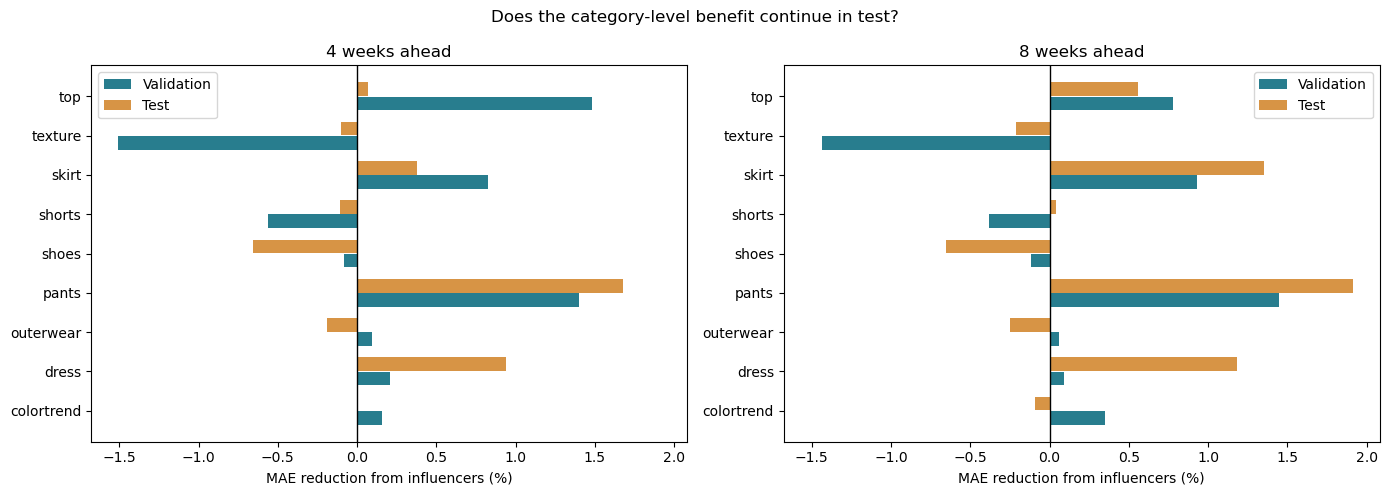

Positive = improvement; negative = worse.
Category differences are descriptive, not significance tests.


In [46]:
test_series_parts = []

for horizon, predictions in [
    (4, test_predictions_h4),
    (8, test_predictions_h8),
]:
    keys = ["date", "forecast_date", "item", "horizon"]

    without = predictions.loc[
        predictions["with_influencer"].eq("no"),
        keys + ["actual", "predicted"],
    ].rename(columns={"predicted": "predicted_without"})

    with_signal = predictions.loc[
        predictions["with_influencer"].eq("yes"),
        keys + ["actual", "predicted"],
    ].rename(columns={
        "actual": "actual_with",
        "predicted": "predicted_with",
    })

    paired = without.merge(
        with_signal,
        on=keys,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    assert paired["_merge"].eq("both").all()
    assert np.allclose(paired["actual"], paired["actual_with"])

    paired["error_without"] = (
        paired["actual"] - paired["predicted_without"]
    ).abs()
    paired["error_with"] = (
        paired["actual"] - paired["predicted_with"]
    ).abs()

    per_series = (
        paired.groupby(["horizon", "item"], observed=True)
        .agg(
            mae_without=("error_without", "mean"),
            mae_with=("error_with", "mean"),
            n_predictions=("actual", "size"),
        )
        .reset_index()
    )

    per_series["category"] = (
        per_series["item"].astype(str)
        .str.extract(r"^[^_]+_[^_]+_(.+)_\d+$", expand=False)
    )
    assert per_series["category"].notna().all()

    denominator = (
        per_series["item"]
        .astype(str)
        .map(mase_denominator)
        .astype("float64")
    )
    valid = np.isfinite(denominator) & denominator.gt(0)

    per_series["mase_without"] = (
        per_series["mae_without"] / denominator.where(valid)
    )
    per_series["mase_with"] = (
        per_series["mae_with"] / denominator.where(valid)
    )

    per_series["improved"] = (
        per_series["mae_with"] < per_series["mae_without"]
    )

    test_series_parts.append(per_series)

test_series_effects = pd.concat(
    test_series_parts, ignore_index=True
)

test_category_effects = (
    test_series_effects.groupby(
        ["horizon", "category"], observed=True
    )
    .agg(
        n_series=("item", "nunique"),
        mae_without=("mae_without", "mean"),
        mae_with=("mae_with", "mean"),
        mase_train_m1_without=("mase_without", "mean"),
        mase_train_m1_with=("mase_with", "mean"),
        share_series_improved=("improved", "mean"),
    )
    .reset_index()
)

test_category_effects["series_improved_percent"] = (
    100 * test_category_effects.pop("share_series_improved")
)

test_category_effects["mae_reduction_percent"] = (
    100
    * (
        test_category_effects["mae_without"]
        - test_category_effects["mae_with"]
    )
    / test_category_effects["mae_without"].replace(0, np.nan)
)

print("Test results by category:")
display(test_category_effects.round(4))

# category_effects should contain the selected-model validation
# results from rerunning Section 25 after Section 29.
category_comparison = category_effects[
    ["horizon", "category", "mae_reduction_percent"]
].rename(columns={
    "mae_reduction_percent": "validation_reduction_percent"
}).merge(
    test_category_effects[
        ["horizon", "category", "mae_reduction_percent"]
    ].rename(columns={
        "mae_reduction_percent": "test_reduction_percent"
    }),
    on=["horizon", "category"],
    validate="one_to_one",
)

print("\nValidation versus test:")
display(category_comparison.round(4))

test_series_effects.to_csv(
    FINAL_DIR / "influencer_effect_by_series_test.csv",
    index=False,
)
test_category_effects.to_csv(
    FINAL_DIR / "influencer_effect_by_category_test.csv",
    index=False,
)
category_comparison.to_csv(
    FINAL_DIR / "category_effect_validation_vs_test.csv",
    index=False,
)

# Show validation and test side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

categories = sorted(category_comparison["category"].unique())
positions = np.arange(len(categories))

for ax, horizon in zip(axes, HORIZONS):
    values = (
        category_comparison.loc[
            category_comparison["horizon"].eq(horizon)
        ]
        .set_index("category")
        .reindex(categories)
    )

    ax.barh(
        positions - 0.18,
        values["validation_reduction_percent"],
        height=0.35,
        label="Validation",
        color="#287D8E",
    )
    ax.barh(
        positions + 0.18,
        values["test_reduction_percent"],
        height=0.35,
        label="Test",
        color="#D79445",
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(categories)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{horizon} weeks ahead")
    ax.set_xlabel("MAE reduction from influencers (%)")
    ax.legend()

fig.suptitle("Does the category-level benefit continue in test?")
plt.tight_layout()
plt.savefig(
    FINAL_DIR / "category_effect_validation_vs_test.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Positive = improvement; negative = worse.")
print("Category differences are descriptive, not significance tests.")

Although the overall influencer benefit remained uncertain, category-level analysis showed repeated improvements for pants, dresses and skirts across validation and test. Pants had the largest test improvement at both horizons. These findings suggest that influencer features may be more useful for some categories, but category-specific uncertainty tests are needed before claiming a reliable benefit.

## 37. Inspect Model Feature Importance

Use LightGBM's saved gain importance to examine which inputs helped
reduce the training objective when building trees.

Convert gain to percentages within each fitted model, then average
across refits. These percentages describe the learned seasonal
adjustment, not the complete forecast: the seasonal reference is also
added directly to every prediction.

Gain importance does not show causation, the direction of an effect,
or how much an input improves test accuracy. Correlated inputs can
share or substitute for each other's importance.

The with-versus-without comparison remains our main test of the
additional forecasting value of influencer information.

Importance by input group:


,horizon,with_influencer,feature_group,mean_gain_percent
0,4,no,Calendar,7.64
1,4,no,Popularity history,52.54
2,4,no,Seasonal reference,39.82
3,4,yes,Calendar,6.87
4,4,yes,Influencer history,3.08
5,4,yes,Popularity history,50.78
6,4,yes,Seasonal reference,39.27
7,8,no,Calendar,12.15
8,8,no,Popularity history,51.27
9,8,no,Seasonal reference,36.57


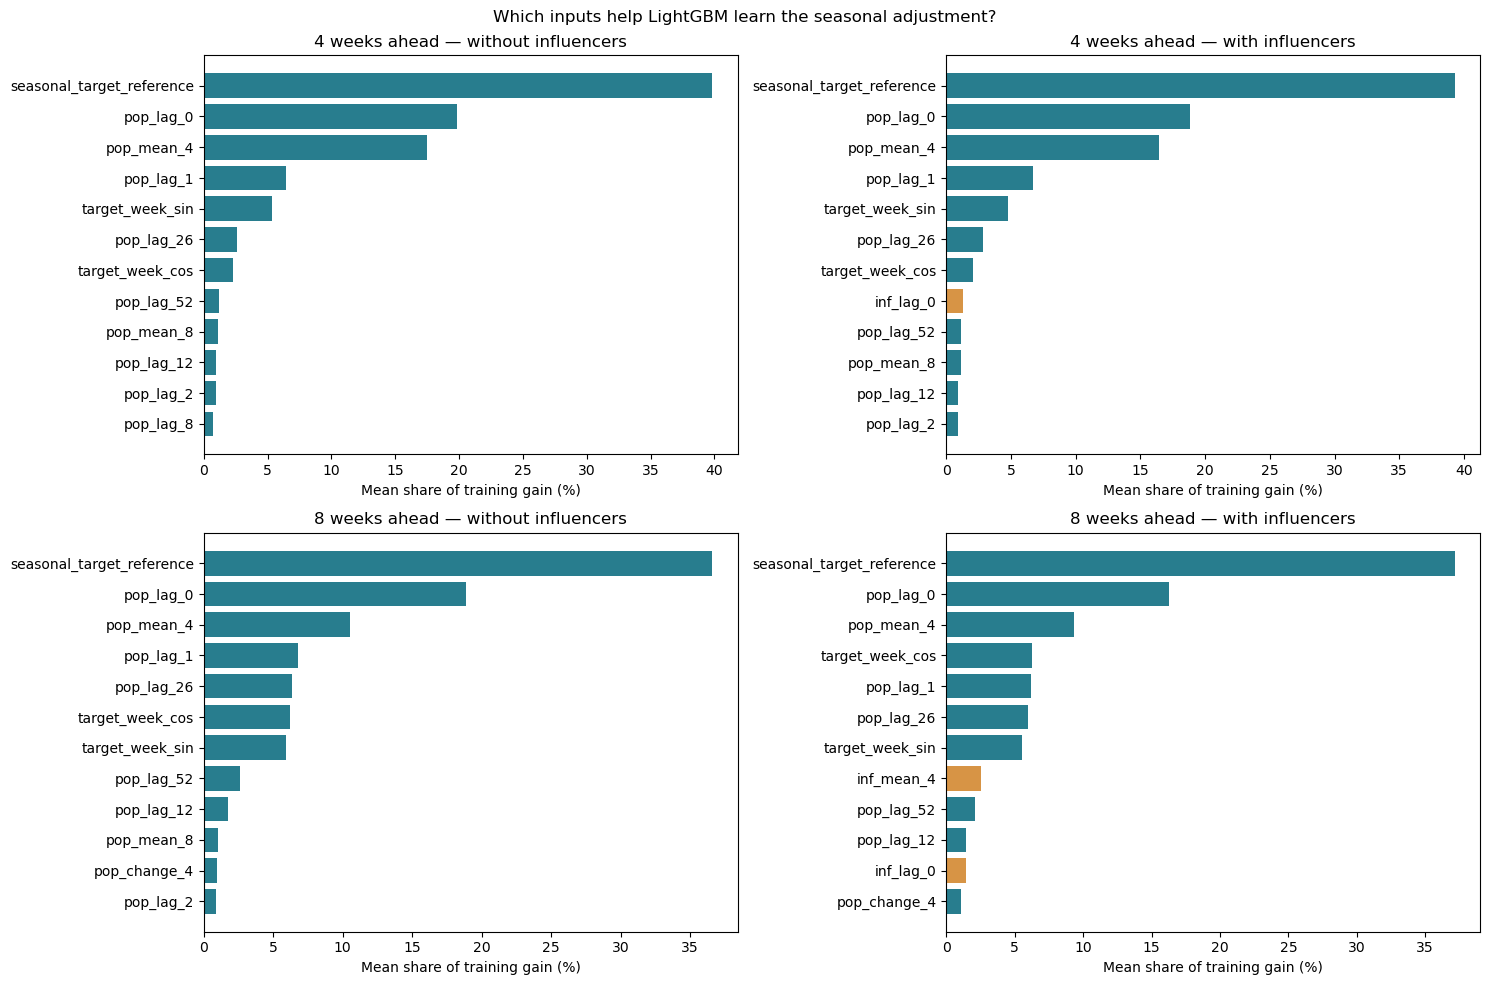

Orange bars identify influencer features.
Gain importance is not a measure of test-error improvement.


In [47]:
test_feature_importance = pd.concat(
    [test_importance_h4, test_importance_h8],
    ignore_index=True,
)

model_groups = ["horizon", "with_influencer", "refit_date"]

# Normalise separately within each fitted model.
gain_totals = test_feature_importance.groupby(
    model_groups
)["gain"].transform("sum")

test_feature_importance["gain_percent"] = (
    100
    * test_feature_importance["gain"]
    / gain_totals.replace(0, np.nan)
)

importance_summary = (
    test_feature_importance.groupby(
        ["horizon", "with_influencer", "feature"]
    )
    .agg(
        mean_gain_percent=("gain_percent", "mean"),
        std_gain_percent=("gain_percent", "std"),
        n_refits=("refit_date", "nunique"),
    )
    .reset_index()
)

importance_summary["feature_group"] = np.select(
    [
        importance_summary["feature"].str.startswith("inf_"),
        importance_summary["feature"].str.startswith("pop_"),
        importance_summary["feature"].eq(SEASONAL_FEATURE),
    ],
    [
        "Influencer history",
        "Popularity history",
        "Seasonal reference",
    ],
    default="Calendar",
)

group_importance = (
    importance_summary.groupby(
        ["horizon", "with_influencer", "feature_group"]
    )["mean_gain_percent"]
    .sum()
    .reset_index()
)

print("Importance by input group:")
display(group_importance.round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for row, horizon in enumerate(HORIZONS):
    for column, flag in enumerate(["no", "yes"]):
        ax = axes[row, column]

        top_features = (
            importance_summary.loc[
                importance_summary["horizon"].eq(horizon)
                & importance_summary["with_influencer"].eq(flag)
            ]
            .nlargest(12, "mean_gain_percent")
            .sort_values("mean_gain_percent")
        )

        colours = np.where(
            top_features["feature_group"].eq("Influencer history"),
            "#D79445",
            "#287D8E",
        )

        ax.barh(
            top_features["feature"],
            top_features["mean_gain_percent"],
            color=colours,
        )

        version = "with influencers" if flag == "yes" else "without influencers"
        ax.set_title(f"{horizon} weeks ahead — {version}")
        ax.set_xlabel("Mean share of training gain (%)")

fig.suptitle(
    "Which inputs help LightGBM learn the seasonal adjustment?"
)
plt.tight_layout()
plt.savefig(
    FINAL_DIR / "feature_importance_gain_test_models.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

importance_summary.to_csv(
    FINAL_DIR / "feature_importance_gain_summary.csv",
    index=False,
)

group_importance.to_csv(
    FINAL_DIR / "feature_importance_gain_groups.csv",
    index=False,
)

print("Orange bars identify influencer features.")
print("Gain importance is not a measure of test-error improvement.")

Gain importance indicates that the seasonal adjustments relied mainly on historical popularity and the seasonal reference. Influencer features received a smaller share of training gain, increasing from 3.08% at four weeks to 5.79% at eight weeks. Their use during training did not translate into a clearly reliable improvement in test accuracy.

## 38. Visualise Final-Test Forecasts

Select three series using a fixed random seed, independently of model
performance. Plot the same series at both forecast horizons.

Compare actual popularity, the seasonal baseline and LightGBM forecasts
with and without influencer inputs.

The horizontal axis shows the target week. Each prediction was made
4 or 8 weeks earlier. These examples illustrate forecast behaviour;
the full score tables remain the main evidence of performance.

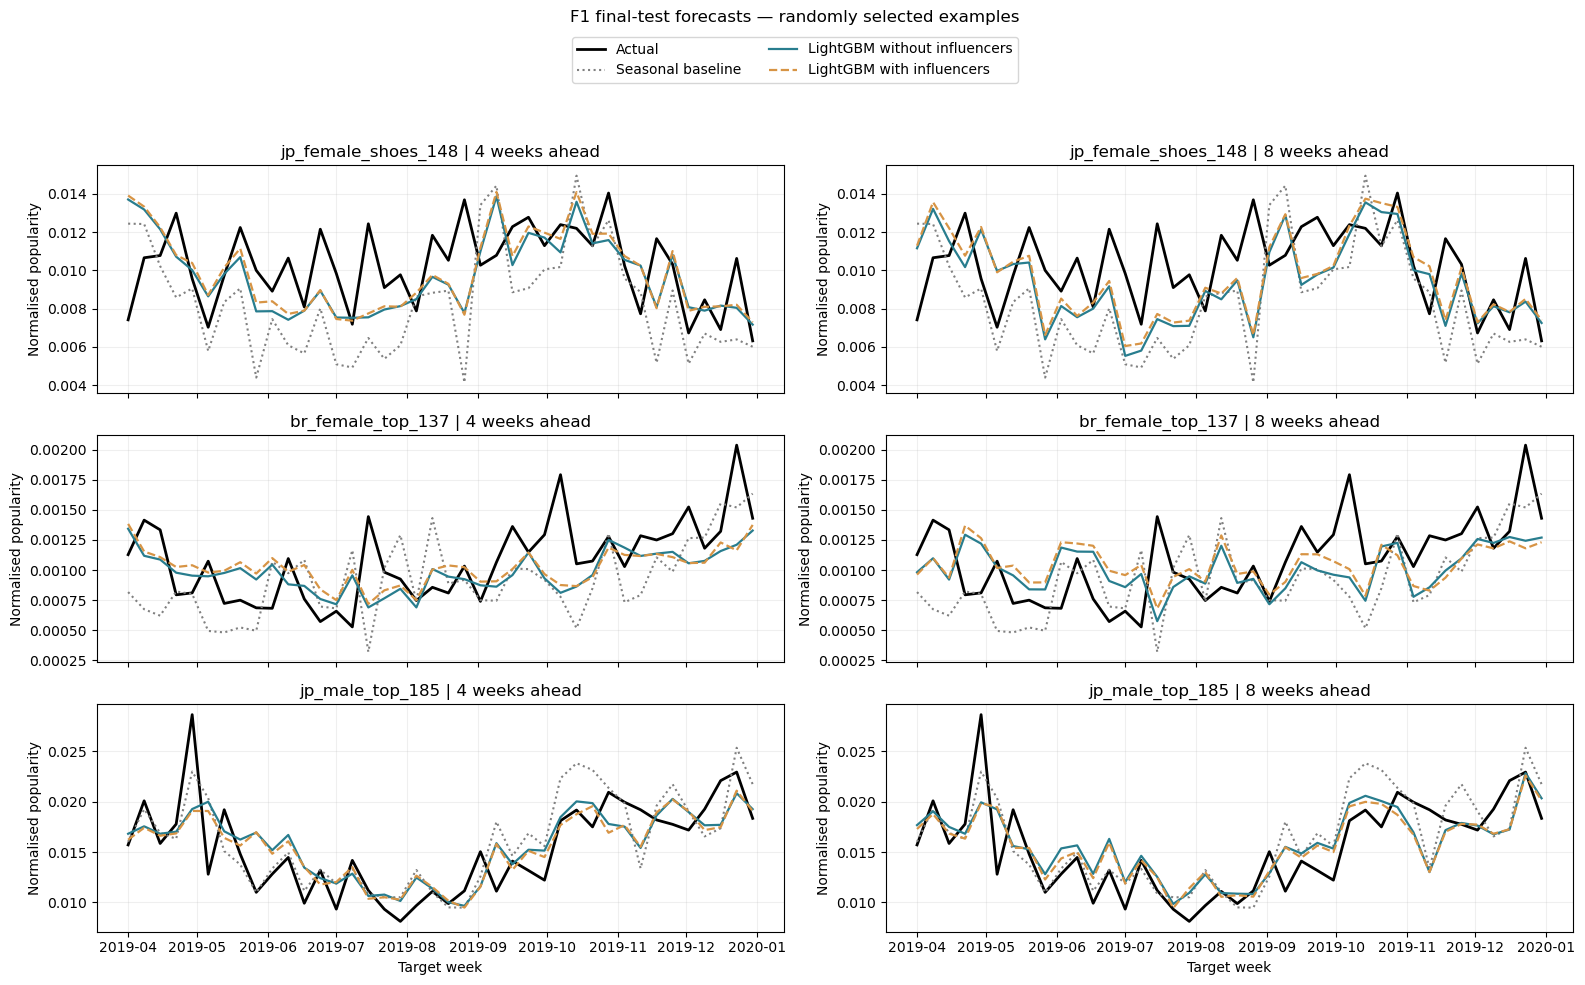

Example chart and its underlying values saved.


In [48]:
# Select examples without using their forecasting errors.
example_rng = np.random.default_rng(MODEL_SEED)

example_items = example_rng.choice(
    popularity.columns.to_numpy(),
    size=3,
    replace=False,
).tolist()

pd.DataFrame({"item": example_items}).to_csv(
    FINAL_DIR / "forecast_example_items.csv",
    index=False,
)

fig, axes = plt.subplots(
    len(example_items),
    len(HORIZONS),
    figsize=(16, 10),
    sharex=True,
    squeeze=False,
)

example_export_parts = []

for column, (horizon, predictions) in enumerate([
    (4, test_predictions_h4),
    (8, test_predictions_h8),
]):
    for row, item in enumerate(example_items):
        ax = axes[row, column]

        selected = predictions.loc[
            predictions["item"].eq(item)
        ].copy()

        without = (
            selected.loc[selected["with_influencer"].eq("no")]
            .sort_values("date")
            .set_index("date")
        )

        with_signal = (
            selected.loc[selected["with_influencer"].eq("yes")]
            .sort_values("date")
            .set_index("date")
        )

        assert without.index.equals(with_signal.index)
        assert np.allclose(
            without["actual"], with_signal["actual"]
        )

        # Use the original data for the seasonal baseline.
        seasonal_dates = (
            without.index - pd.Timedelta(weeks=SEASONAL_PERIOD)
        )
        seasonal_values = popularity.loc[
            seasonal_dates, item
        ].to_numpy()

        ax.plot(
            without.index, without["actual"],
            color="black", linewidth=2, label="Actual",
        )
        ax.plot(
            without.index, seasonal_values,
            color="gray", linestyle=":",
            label="Seasonal baseline",
        )
        ax.plot(
            without.index, without["predicted"],
            color="#287D8E", linewidth=1.6,
            label="LightGBM without influencers",
        )
        ax.plot(
            with_signal.index, with_signal["predicted"],
            color="#D79445", linestyle="--", linewidth=1.6,
            label="LightGBM with influencers",
        )

        ax.set_title(f"{item} | {horizon} weeks ahead")
        ax.set_ylabel("Normalised popularity")
        ax.grid(alpha=0.2)

        example_export_parts.append(pd.DataFrame({
            "target_date": without.index,
            "forecast_date": without["forecast_date"].to_numpy(),
            "item": item,
            "horizon": horizon,
            "actual": without["actual"].to_numpy(),
            "seasonal_naive": seasonal_values,
            "predicted_without": without["predicted"].to_numpy(),
            "predicted_with": with_signal["predicted"].to_numpy(),
        }))

for ax in axes[-1]:
    ax.set_xlabel("Target week")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=2,
)

fig.suptitle("F1 final-test forecasts — randomly selected examples")
fig.tight_layout(rect=[0, 0, 1, 0.89])

fig.savefig(
    FINAL_DIR / "forecast_examples_test.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

pd.concat(example_export_parts, ignore_index=True).to_csv(
    FINAL_DIR / "forecast_examples_test.csv",
    index=False,
)

print("Example chart and its underlying values saved.")

In the randomly selected examples, LightGBM captures some broad popularity patterns but misses several sharp weekly changes. Forecasts with and without influencer features are visually similar, consistent with their small difference in test MAE. These examples illustrate model behaviour; overall performance is assessed across all 10,000 series.

## 39. Forecast errors during large weekly changes

For each series, a large weekly change is an absolute week-to-week change
above the 90th percentile of that series’ training-period changes.

These thresholds are calculated from training data only. Test observations
are then grouped retrospectively into large-change weeks and other weeks.

This is an error diagnostic: the group uses the observed target-week change,
which would not yet be known when making the forecast. It is not a method
for predicting spikes or identifying their causes.

In [49]:
# Training-only thresholds, calculated separately for each series.
change_thresholds = (
    popularity_train.diff().abs().quantile(0.90)
    .reindex(popularity.columns)
    .astype("float64")
)

assert change_thresholds.notna().all()

change_thresholds.rename("training_change_p90").to_csv(
    FINAL_DIR / "large_change_thresholds.csv"
)

change_results = []

for horizon, predictions in [
    (4, test_predictions_h4),
    (8, test_predictions_h8),
]:
    for flag in ["no", "yes"]:
        rows = predictions.loc[
            predictions["with_influencer"].eq(flag),
            ["date", "item", "actual", "predicted"],
        ].copy()

        # Internal prediction dates are target dates.
        target_positions = popularity.index.get_indexer(
            pd.to_datetime(rows["date"])
        )
        item_positions = popularity.columns.get_indexer(
            rows["item"].astype(str)
        )

        assert (target_positions > 0).all()
        assert (item_positions >= 0).all()

        actual = rows["actual"].to_numpy(dtype="float64")
        predicted = rows["predicted"].to_numpy(dtype="float64")

        previous_week = popularity.to_numpy(copy=False)[
            target_positions - 1, item_positions
        ].astype("float64")

        thresholds = change_thresholds.to_numpy()[item_positions]

        groups = np.where(
            np.abs(actual - previous_week) > thresholds,
            "Large weekly change",
            "Other weeks",
        )

        errors = pd.DataFrame({
            "change_group": groups,
            "absolute_error": np.abs(actual - predicted),
        })

        summary = (
            errors.groupby("change_group", observed=True)
            .agg(
                n_predictions=("absolute_error", "size"),
                mae=("absolute_error", "mean"),
            )
            .reset_index()
        )

        summary["horizon"] = horizon
        summary["model"] = "lightgbm_seasonal_correction"
        summary["with_influencer"] = flag
        change_results.append(summary)

        # Score the seasonal baseline on exactly the same observations.
        if flag == "no":
            seasonal_prediction = popularity.to_numpy(copy=False)[
                target_positions - SEASONAL_PERIOD,
                item_positions,
            ].astype("float64")

            errors["absolute_error"] = np.abs(
                actual - seasonal_prediction
            )

            baseline_summary = (
                errors.groupby("change_group", observed=True)
                .agg(
                    n_predictions=("absolute_error", "size"),
                    mae=("absolute_error", "mean"),
                )
                .reset_index()
            )

            baseline_summary["horizon"] = horizon
            baseline_summary["model"] = "seasonal_naive"
            baseline_summary["with_influencer"] = "not_applicable"
            change_results.append(baseline_summary)

change_error_summary = pd.concat(
    change_results, ignore_index=True
)[[
    "horizon",
    "change_group",
    "model",
    "with_influencer",
    "n_predictions",
    "mae",
]].sort_values(
    ["horizon", "change_group", "model", "with_influencer"]
)

change_error_summary.to_csv(
    FINAL_DIR / "errors_by_weekly_change_test.csv",
    index=False,
)

display(change_error_summary.round({"mae": 6}))

,horizon,change_group,model,with_influencer,n_predictions,mae
0,4,Large weekly change,lightgbm_seasonal_correction,no,23100,0.005679
4,4,Large weekly change,lightgbm_seasonal_correction,yes,23100,0.005648
2,4,Large weekly change,seasonal_naive,not_applicable,23100,0.005548
1,4,Other weeks,lightgbm_seasonal_correction,no,376900,0.002855
5,4,Other weeks,lightgbm_seasonal_correction,yes,376900,0.002852
3,4,Other weeks,seasonal_naive,not_applicable,376900,0.003476
6,8,Large weekly change,lightgbm_seasonal_correction,no,23100,0.005652
10,8,Large weekly change,lightgbm_seasonal_correction,yes,23100,0.005626
8,8,Large weekly change,seasonal_naive,not_applicable,23100,0.005548
7,8,Other weeks,lightgbm_seasonal_correction,no,376900,0.003063


### Interpretation

Forecast errors were higher during large weekly changes. In this group,
the seasonal-naïve baseline slightly outperformed both LightGBM versions
at both horizons. LightGBM's overall improvement was concentrated in
the remaining observations.

Adding influencer features slightly reduced LightGBM's MAE in both
groups. However, the overall test-period bootstrap intervals included
zero, so a reliable additional benefit was not established.

These groups were defined retrospectively using observed target-week
changes and training-derived thresholds. This analysis describes where
errors occurred; it does not demonstrate an ability to anticipate sudden
changes or establish their causes.

## 40. Export final model scores

This table combines the selected LightGBM validation results, final test
results, and baseline comparisons.

- MAE measures error in normalized popularity.
- mase_train_m1 scales each series' MAE by its training-period mean
  absolute weekly change, then averages across series.
- relative_mae_vs_four_week_average divides overall MAE by the
  four-week-average baseline's MAE on the same evaluation observations.

F1 forecasts predict a single week's popularity four or eight weeks ahead.
This differs from the four-week-average target used in the Google Trends
experiment, so results should be interpreted separately.

In [50]:
HANDOFF_DIR = FINAL_DIR / "team_export"
HANDOFF_DIR.mkdir(parents=True, exist_ok=True)

validation_export = selected_validation_scores.copy()
validation_export["period"] = "validation"

test_export = final_test_scores.copy()
test_export["period"] = "test"

team_scores = pd.concat(
    [validation_export, test_export],
    ignore_index=True,
)

score_columns = [
    "model",
    "with_influencer",
    "horizon",
    "period",
    "mae",
    "mase_train_m1",
    "relative_mae_vs_four_week_average",
    "n_predictions",
    "n_series",
    "n_series_mase",
]

# Keep the available fields without inventing missing values.
required_columns = score_columns[:8]
missing = set(required_columns) - set(team_scores.columns)
assert not missing, f"Missing score columns: {sorted(missing)}"

team_scores = team_scores[
    [column for column in score_columns if column in team_scores.columns]
].copy()

score_keys = ["model", "with_influencer", "horizon", "period"]
assert not team_scores.duplicated(score_keys).any()

metric_columns = [
    "mae",
    "mase_train_m1",
    "relative_mae_vs_four_week_average",
]

assert np.isfinite(
    team_scores[metric_columns].to_numpy(dtype="float64")
).all()

assert team_scores["n_predictions"].gt(0).all()

team_scores = team_scores.sort_values(
    ["period", "horizon", "mae"]
).reset_index(drop=True)

scores_path = HANDOFF_DIR / "scores.csv"
team_scores.to_csv(scores_path, index=False)

display(team_scores.round(6))
print("Saved:", scores_path)

,model,with_influencer,horizon,period,mae,mase_train_m1,relative_mae_vs_four_week_average,n_predictions,n_series,n_series_mase
0,lightgbm_seasonal_correction,yes,4,test,0.003014,0.770875,0.582180,400000,10000,10000
1,lightgbm_seasonal_correction,no,4,test,0.003018,0.773142,0.583044,400000,10000,10000
2,seasonal_naive,not_applicable,4,test,0.003596,0.963946,0.694567,400000,10000,10000
3,last_value,not_applicable,4,test,0.004736,1.106554,0.914825,400000,10000,10000
4,four_week_average,not_applicable,4,test,0.005177,1.157552,1.000000,400000,10000,10000
5,lightgbm_seasonal_correction,yes,8,test,0.003202,0.832158,0.431548,400000,10000,10000
6,lightgbm_seasonal_correction,no,8,test,0.003212,0.835139,0.432898,400000,10000,10000
7,seasonal_naive,not_applicable,8,test,0.003596,0.963946,0.484585,400000,10000,10000
8,last_value,not_applicable,8,test,0.006977,1.550831,0.940253,400000,10000,10000
9,four_week_average,not_applicable,8,test,0.007420,1.620850,1.000000,400000,10000,10000


Saved: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/lightgbm/final/team_export/scores.csv


## 41. Export LightGBM predictions

In the exported file, date is the forecast-origin week and target_date
is the week being predicted. last4_avg is the average popularity over
the four weeks up to and including the forecast date.

Actual and predicted values remain single-week popularity values.
They are not four-week-average forecasts.

In [51]:
prediction_parts = []

for period, horizon, predictions in [
    ("validation", 4, predictions_h4),
    ("validation", 8, predictions_h8),
    ("test", 4, test_predictions_h4),
    ("test", 8, test_predictions_h8),
]:
    # Copy so the notebook's internal date convention stays unchanged.
    export = predictions[[
        "forecast_date", "date", "item", "actual", "predicted",
        "model", "with_influencer",
    ]].copy()

    export = export.rename(columns={
        "date": "target_date",
        "forecast_date": "date",
    })

    export["date"] = pd.to_datetime(export["date"])
    export["target_date"] = pd.to_datetime(export["target_date"])
    export["item"] = export["item"].astype(str)
    export["horizon"] = horizon
    export["period"] = period

    origin_positions = popularity.index.get_indexer(export["date"])
    target_positions = popularity.index.get_indexer(export["target_date"])
    item_positions = popularity.columns.get_indexer(export["item"])

    assert (origin_positions >= 3).all()
    assert (target_positions >= 0).all()
    assert (item_positions >= 0).all()
    assert ((target_positions - origin_positions) == horizon).all()

    export["last4_avg"] = popularity_rolling4.to_numpy(copy=False)[
        origin_positions, item_positions
    ]

    prediction_parts.append(export)

team_predictions = pd.concat(prediction_parts, ignore_index=True)[[
    "date",
    "item",
    "horizon",
    "actual",
    "predicted",
    "model",
    "period",
    "with_influencer",
    "target_date",
    "last4_avg",
]]

prediction_keys = [
    "date", "item", "horizon", "model", "period", "with_influencer"
]

assert not team_predictions.duplicated(prediction_keys).any()
assert np.isfinite(
    team_predictions[["actual", "predicted", "last4_avg"]]
    .to_numpy(dtype="float64")
).all()

# Compression keeps this large export easier to share.
predictions_path = HANDOFF_DIR / "predictions.csv.gz"
team_predictions.to_csv(
    predictions_path,
    index=False,
    compression="gzip",
    date_format="%Y-%m-%d",
)

display(
    team_predictions.groupby(
        ["period", "horizon", "with_influencer"],
        observed=True,
    ).size().rename("n_predictions").reset_index()
)

display(team_predictions.head())
print("Saved:", predictions_path)
print("Total rows:", f"{len(team_predictions):,}")

,period,horizon,with_influencer,n_predictions
0,test,4,no,400000
1,test,4,yes,400000
2,test,8,no,400000
3,test,8,yes,400000
4,validation,4,no,390000
5,validation,4,yes,390000
6,validation,8,no,390000
7,validation,8,yes,390000


,date,item,horizon,actual,predicted,model,period,with_influencer,target_date,last4_avg
0,2018-06-04,br_female_outerwear_0,4,0.012046,0.019568,lightgbm_seasonal_correction,validation,no,2018-07-02,0.014382
1,2018-06-04,br_female_outerwear_1,4,0.022887,0.018255,lightgbm_seasonal_correction,validation,no,2018-07-02,0.016296
2,2018-06-04,br_female_outerwear_2,4,0.019876,0.016123,lightgbm_seasonal_correction,validation,no,2018-07-02,0.013668
3,2018-06-04,br_female_outerwear_3,4,0.012046,0.017009,lightgbm_seasonal_correction,validation,no,2018-07-02,0.013598
4,2018-06-04,br_female_outerwear_4,4,0.048786,0.038227,lightgbm_seasonal_correction,validation,no,2018-07-02,0.038046


Saved: /Users/daki/Desktop/SEM 2/ML/Project/results/f1/lightgbm/final/team_export/predictions.csv.gz
Total rows: 3,160,000


## 42. Verify exported predictions against reported MAE

Recalculate MAE from the exported LightGBM predictions and compare it
with scores.csv. Also check that both influencer versions contain the
same observations and actual values.

In [52]:
# Read back the saved files to verify the actual exports.
saved_predictions = pd.read_csv(
    HANDOFF_DIR / "predictions.csv.gz",
    parse_dates=["date", "target_date"],
    dtype={"item": str},
)

saved_scores = pd.read_csv(HANDOFF_DIR / "scores.csv")

keys = ["model", "with_influencer", "horizon", "period"]

saved_predictions["absolute_error"] = (
    saved_predictions["actual"] - saved_predictions["predicted"]
).abs()

recalculated = (
    saved_predictions.groupby(keys, observed=True)
    .agg(
        recalculated_mae=("absolute_error", "mean"),
        exported_rows=("absolute_error", "size"),
    )
    .reset_index()
)

verification = recalculated.merge(
    saved_scores[keys + ["mae", "n_predictions"]],
    on=keys,
    how="outer",
    validate="one_to_one",
    indicator=True,
)

# Scores also contain baselines, which are exported separately.
verification = verification.loc[
    verification["model"].eq("lightgbm_seasonal_correction")
].copy()

assert verification["_merge"].eq("both").all()
assert (
    verification["exported_rows"] == verification["n_predictions"]
).all()

np.testing.assert_allclose(
    verification["recalculated_mae"],
    verification["mae"],
    rtol=1e-8,
    atol=1e-12,
)

# Confirm that the two versions predict identical evaluation cases.
case_keys = ["date", "target_date", "item", "horizon", "period"]

without = saved_predictions.loc[
    saved_predictions["with_influencer"].eq("no"),
    case_keys + ["actual", "last4_avg"],
]

with_inf = saved_predictions.loc[
    saved_predictions["with_influencer"].eq("yes"),
    case_keys + ["actual", "last4_avg"],
]

paired_check = without.merge(
    with_inf,
    on=case_keys,
    how="outer",
    suffixes=("_without", "_with"),
    validate="one_to_one",
    indicator=True,
)

assert paired_check["_merge"].eq("both").all()

for column in ["actual", "last4_avg"]:
    np.testing.assert_allclose(
        paired_check[f"{column}_without"],
        paired_check[f"{column}_with"],
        rtol=0,
        atol=0,
    )

verification["mae_difference"] = (
    verification["recalculated_mae"] - verification["mae"]
)

verification.drop(columns="_merge").to_csv(
    HANDOFF_DIR / "export_verification.csv",
    index=False,
)

display(verification[[
    "period", "horizon", "with_influencer",
    "exported_rows", "mae", "recalculated_mae", "mae_difference",
]])

print("Passed: exported MAE matches the reported scores.")
print("Passed: influencer versions use identical evaluation cases.")

# Release the extra copies created only for this check.
del saved_predictions, without, with_inf, paired_check

,period,horizon,with_influencer,exported_rows,mae,recalculated_mae,mae_difference
8,test,4,no,400000.0,0.003018,0.003018,5.204170e-17
9,validation,4,no,390000.0,0.002877,0.002877,8.977194e-17
10,test,8,no,400000.0,0.003212,0.003212,7.806256e-17
11,validation,8,no,390000.0,0.003085,0.003085,4.206704e-17
12,test,4,yes,400000.0,0.003014,0.003014,2.471981e-17
13,validation,4,yes,390000.0,0.002866,0.002866,2.992398e-17
14,test,8,yes,400000.0,0.003202,0.003202,1.734723e-17
15,validation,8,yes,390000.0,0.003076,0.003076,8.239937e-18


Passed: exported MAE matches the reported scores.
Passed: influencer versions use identical evaluation cases.


## 43. Final methods, findings, and limitations

Save a summary of the F1 experiment alongside the exported predictions
and scores. This distinguishes overall forecasting performance from
the additional contribution of influencer features.

In [53]:
final_explanation = """F1 / HERMES forecasting experiment

1. What I did

I evaluated whether influencer-history features improve weekly fashion
popularity forecasts beyond popularity history and seasonality.

The dataset contains 10,000 weekly popularity series from 2015 to 2019.
I used a chronological split: 182 initial training weeks, 39 validation
target weeks, and 40 final test target weeks.

I compared last-value, trailing-four-week-average, and seasonal-naive
baselines with LightGBM seasonal-correction models, with and without
influencer features. LightGBM predicts a correction to the popularity
observed 52 weeks before the target week.

Inputs included popularity lags, recent averages, changes, volatility,
calendar seasonality, and a seasonal reference. The additional-feature
version also included influencer lags and recent summary statistics.

I compared 300, 500, and 1,000 boosting iterations on validation data.
The popularity-only validation results selected 1,000 iterations at
both horizons. The same settings were used for both influencer versions.

Models were retrained every four forecast weeks using an expanding
history. Training labels were included only when their target dates
were available by the refit date. Predictions were clipped at zero.
Hyperparameters were fixed before final test evaluation.

2. What I found

LightGBM outperformed the evaluated baselines overall on the final test
period. Seasonal naive was the strongest baseline.

At four weeks, MAE was approximately 0.003018 without influencers and
0.003014 with influencers, compared with 0.003596 for seasonal naive.

At eight weeks, MAE was approximately 0.003212 without influencers and
0.003202 with influencers, compared with 0.003596 for seasonal naive.

Adding influencer features reduced overall test MAE by 0.1481% at four
weeks and 0.3120% at eight weeks. Paired moving-block bootstrap intervals
included zero at both horizons for all three tested block lengths
(4, 8, and 13 weeks). Therefore, the test results did not establish a
statistically reliable additional benefit from influencer features.

Category-level results varied. Pants, dresses, and skirts showed
positive point estimates in validation and test at both horizons.
These category findings are descriptive; category-specific statistical
reliability was not established.

Popularity history and seasonal-reference features accounted for most
of the model's training gain. Influencer features contributed a smaller
share. Training-gain importance does not establish out-of-sample
accuracy improvements or causal influence.

A retrospective error analysis found higher errors during large weekly
changes. In that group, seasonal naive slightly outperformed LightGBM.
LightGBM's overall advantage was concentrated in the other observations.
Large changes were defined using each series' training-period 90th
percentile of absolute weekly changes.

3. Metric and export definitions

MAE is measured in normalized popularity units.

mase_train_m1 is the average across series of each series' MAE divided
by its initial training-period mean absolute weekly change.

relative_mae_vs_four_week_average is overall model MAE divided by the
four-week-average baseline's MAE on the same evaluation observations.
It is reported separately from mase_train_m1.

In the team predictions export, date is the forecast-origin week.
target_date is the predicted week. last4_avg is the average of the
four observed weeks up to and including the forecast origin.

F1 actual and predicted values refer to a single target week at t+4
or t+8. They differ from the four-week-average target used in the
Google Trends experiment.

4. Limitations and interpretation

This dataset predates 2020 and cannot establish how influencer signals
perform in the current TikTok or Instagram environment.

The final test period contains only 40 target weeks. The many series
do not provide 400,000 independent time observations. Bootstrap
intervals describe uncertainty under the chosen resampling procedure.

The series use anonymous identifiers, limiting direct alignment with
named Google Trends styles. Some influencer histories are duplicated
across series, so the influencer inputs are not all independent signals.

This experiment measures predictive associations, not causal effects
of influencers. A small or uncertain incremental improvement does not
prove that influencers have no value.

LightGBM was the strongest evaluated final-test model in this experiment.
XGBoost was not evaluated here, so these results do not establish that
LightGBM would outperform XGBoost.

The F1 experiment supports the wider project by testing the incremental
value of social signals. Its different dates, target definition, and
measurement scale limit direct numerical comparisons with Google
Trends and VISUELLE results.
"""

explanation_path = HANDOFF_DIR / "result_explanation.txt"
explanation_path.write_text(final_explanation, encoding="utf-8")

print(final_explanation)
print("\nSaved:", explanation_path)

F1 / HERMES forecasting experiment

1. What I did

I evaluated whether influencer-history features improve weekly fashion
popularity forecasts beyond popularity history and seasonality.

The dataset contains 10,000 weekly popularity series from 2015 to 2019.
I used a chronological split: 182 initial training weeks, 39 validation
target weeks, and 40 final test target weeks.

I compared last-value, trailing-four-week-average, and seasonal-naive
baselines with LightGBM seasonal-correction models, with and without
influencer features. LightGBM predicts a correction to the popularity
observed 52 weeks before the target week.

Inputs included popularity lags, recent averages, changes, volatility,
calendar seasonality, and a seasonal reference. The additional-feature
version also included influencer lags and recent summary statistics.

I compared 300, 500, and 1,000 boosting iterations on validation data.
The popularity-only validation results selected 1,000 iterations at
both horizons. The 